# Проект исследовательский анализ мероприятий сервиса яндекс афиша

## Цели и задачи проекта

Цель исследования - выявить инсайты об изменении пользовательских предпочтений и популярности событий осенью 2024 года, а также проверить гипотезы о разнице в поведении пользователей с мобильными и стационарными устройствами. 


## План проекта
1. Выгрузить данные
2. обработать данные 
3. анализ 
4. стат. проверка гипозеты
5. вывод

## Описание данных

Первый датасет final_tickets_orders_df.csv включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. Поля датасета соответствуют таблице purchases, с которой вы работали в предыдущих заданиях:

order_id — уникальный идентификатор заказа.

user_id — уникальный идентификатор пользователя.

created_dt_msk — дата создания заказа (московское время).

created_ts_msk — дата и время создания заказа (московское время).

event_id — идентификатор мероприятия из таблицы events.

cinema_circuit — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.

age_limit — возрастное ограничение мероприятия.

currency_code — валюта оплаты, например rub для российских рублей.

device_type_canonical — тип устройства, с которого был оформлен заказ, например mobile для мобильных устройств, desktop для стационарных.

revenue — выручка от заказа.

service_name — название билетного оператора.

tickets_count — количество купленных билетов.

total — общая сумма заказа.

days_since_prev - количество дней между заказами пользователя


Второй датасет final_tickets_events_df содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. Обратите внимание, что из данных исключили фильмы, ведь, как было видно на дашборде, событий такого типа не так много. Датасет содержит такие поля:

event_id — уникальный идентификатор мероприятия.

event_name — название мероприятия. Аналог поля event_name_code из исходной базы данных.

event_type_description — описание типа мероприятия.

event_type_main — основной тип мероприятия: театральная постановка, концерт и так далее.

organizers — организаторы мероприятия.

region_name — название региона.

city_name — название города.

venue_id — уникальный идентификатор площадки.

venue_name — название площадки.

venue_address — адрес площадки.


## Загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu



In [136]:
#df_order = pd.read_csv('final_tickets_orders_df.csv')

In [137]:
#df_event = pd.read_csv('final_tickets_events_df.csv')

In [138]:
#df_tenge = pd.read_csv('final_tickets_tenge_df.csv')

In [5]:
df_order.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [6]:
df_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

In [7]:
print('Вывод значений по количеству билетов')
print(df_order['tickets_count'].head())
print(df_order['tickets_count'].max())
print()
print('Вывод значений по интервалу медоу заказами')
print(df_order['days_since_prev'].head())
print(df_order['days_since_prev'].max())

Вывод значений по количеству билетов
0    4
1    2
2    4
3    2
4    3
Name: tickets_count, dtype: int64
57

Вывод значений по интервалу медоу заказами
0     NaN
1     NaN
2    75.0
3     NaN
4    83.0
Name: days_since_prev, dtype: float64
148.0


290849 строк 14 столбцов

В колонке пропуски только в днях между заказами что значит это первая покупка

необходимо преобразование изменить типа данных в колонках по датам на datetime

для оптимизации памяти необходимо преобразование данных в age_limit, в tickets_count на тип int8. значения менне 128 

Необходимо проверить данные на дубликаты как полные так и не полные
дубликаты по order_id, поскольку заказы это уникальный не должны поворятся, при этом пользователи могут несколько заказов делать

Так же видно что выручка в  двух валютах необходимо привести к единой выручке  

In [8]:
df_event.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [9]:
df_event.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


Строк 22427, 11 столбцов

пропусков нет,

Типы данных корректны и нет еобходимости менять для оптимизации памяти

Необходиом проверить на дубликаты и опечатки event_name, organizers, region_name, city_name, venue_name




In [10]:
df_tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [11]:
df_tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


356 строк, 4 столбца

прокусков нет.

необходимо data привести к типу дата
другие корректировки и проверки не нужны

Ошибок в текстовых значениях нет

In [12]:
display(df_order['revenue'].describe())
display(df_order['tickets_count'].describe())
display(df_order['total'].describe())

count    290849.000000
mean        625.083054
std        1227.316214
min         -90.760000
25%         116.790000
50%         355.340000
75%         809.750000
max       81174.540000
Name: revenue, dtype: float64

count    290849.000000
mean          2.754230
std           1.170467
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          57.000000
Name: tickets_count, dtype: float64

count    290849.000000
mean       7526.465613
std       15328.267730
min        -358.850000
25%        2156.870000
50%        4771.390000
75%        8955.950000
max      811745.400000
Name: total, dtype: float64

В столбце с выручкой есть отрицательные значения, а также аномально высокие

В столбце с количестовм блетов за заказ есть максимум 57 билетов, выглядит реаьно возмжно как групповое мероприятие, по типу школьной экскурсии или группы студентов

В столбце с общей суммы за заказ аналогично столбцу с выручкой

Нужно будет аномальные значения исключить 

In [13]:
print('Количество пропусков в столбце days_since_prev:', df_order['days_since_prev'].isna().sum())

Количество пропусков в столбце days_since_prev: 21940


## Обработка данных

### Поиск дубликатов

Необходимо проверить данные на наличие дубликатов

In [14]:
df_event.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


In [15]:
print(df_order.duplicated().sum(), 
df_order['order_id'].duplicated().sum())
print('Полных дубликатов и дубликатов по столбцу заказов нет')

print(df_event.duplicated().sum(), 
df_order['event_id'].duplicated().sum())
print('Полных дубликатов и дубликатов по столбцу заказов нет')


duplicate_events = df_event.groupby('event_id').agg({
    'event_name': 'nunique'})

problematic_events = duplicate_events[duplicate_events['event_name'] > 1]
print('дубликаты по event_id ',problematic_events.count())


0 0
Полных дубликатов и дубликатов по столбцу заказов нет
0 268403
Полных дубликатов и дубликатов по столбцу заказов нет
дубликаты по event_id  event_name    0
dtype: int64


In [16]:
# Группируем по индетификаторы площадок и считаем уникальные значения в ключевых полях
venue_duplicates = df_event.groupby('venue_id').agg({
    'venue_name': 'nunique',
    'venue_address': 'nunique'
})

# Оставляем индетификаторы площадок с более чем одной уникальной записью
problematic_venues = venue_duplicates[
    (venue_duplicates['venue_name'] > 1) |
    (venue_duplicates['venue_address'] > 1)]

print(f"Найдено {len(problematic_venues)} venue_id с противоречивыми данными") 

Найдено 0 venue_id с противоречивыми данными


In [17]:
print(df_order['cinema_circuit'].unique())
print(df_order['age_limit'].unique())
print(df_order['currency_code'].unique())
print(df_order['device_type_canonical'].unique())
print()
print(df_order['service_name'].unique())



['нет' 'Другое' 'Киномакс' 'КиноСити' 'Москино' 'ЦентрФильм']
[16  0 18 12  6]
['rub' 'kzt']
['mobile' 'desktop']

['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино билет' 'Цвет и билет' 'Зе Бест!'
 'Тех билет' 'Лимоны' 'Билеты в интернете']


In [18]:
for column in df_event.columns:
    print(f"Уникальные значения в столбце '{column}':")
    print(df_event[column].unique())
    print()

Уникальные значения в столбце 'event_id':
[  4436   5785   8817 ... 591877 592322 592325]

Уникальные значения в столбце 'event_name':
['e4f26fba-da77-4c61-928a-6c3e434d793f'
 '5cc08a60-fdea-4186-9bb2-bffc3603fb77'
 '8e379a89-3a10-4811-ba06-ec22ebebe989' ...
 '196f51a8-344a-462a-b806-a8467fd0e5fa'
 '9283cb32-2750-43cd-b57e-dde9ccd5552e'
 'f4952452-27ff-4d03-9adb-f7836430f83b']

Уникальные значения в столбце 'event_type_description':
['спектакль' 'балет' 'мюзикл' 'опера' 'концерт' 'шоу' 'ёлка'
 'цирковое шоу' 'событие' 'фестиваль' 'спортивное мероприятие' 'выставка'
 'спорт' 'оперетта' 'экскурсия' 'рок-мюзикл' 'музыкальный спектакль'
 'снегурочка' 'подарок' 'кукольный спектакль']

Уникальные значения в столбце 'event_type_main':
['театр' 'концерты' 'ёлки' 'другое' 'стендап' 'выставки' 'спорт']

Уникальные значения в столбце 'organizers':
['№4893' '№1931' '№4896' ... '№4817' '№5105' '№4552']

Уникальные значения в столбце 'region_name':
['Североярская область' 'Светополянский округ' 'Кам

Дубликатов обоих видов необнаружено в данных

### Конвертация типов данных

Для оптимиазации памяти допустимо перобразовать типы данных к int8 в  колонках age_limit, tickets_count поскольку не содержат больших значений

In [19]:
df_order['age_limit'] = df_order['age_limit'].astype('int8')
df_order['tickets_count'] = df_order['tickets_count'].astype('int8')

In [20]:
df_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int8   
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int8   
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(2), int8(2), ob

Оптимизация двух столбцов с  31.1+ MB до 27.2+ MB

### обработка типов данных 

Колонки с датами необходимо преоброзовать к типу данных datetime64 для корретной работы со временем, сейчас тип данных object

In [21]:
date_col = ['created_dt_msk', 'created_ts_msk']
df_order[date_col] = df_order[date_col].apply(pd.to_datetime)
df_order[date_col].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 2 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   created_dt_msk  290849 non-null  datetime64[ns]
 1   created_ts_msk  290849 non-null  datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 4.4 MB


In [22]:
df_tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


In [23]:
df_tenge['data'] = pd.to_datetime(df_tenge['data']) 
df_tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   data     357 non-null    datetime64[ns]
 1   nominal  357 non-null    int64         
 2   curs     357 non-null    float64       
 3   cdx      357 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 11.3+ KB


в таблице с заказми были преобразованы две колонки с датами к типу datetime64[ns]
в таблице с курсом валбт была преобразована одна колонка с датой к типу datetime64[ns]

### аномалии

Проверка значений на аномалии по колонке revenue выручка, при этом следует разделить проверку по валютам 

In [24]:
df_order.columns

Index(['order_id', 'user_id', 'created_dt_msk', 'created_ts_msk', 'event_id',
       'cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical',
       'revenue', 'service_name', 'tickets_count', 'total', 'days_since_prev'],
      dtype='object')

In [25]:
df_order['currency_code'].unique()


array(['rub', 'kzt'], dtype=object)

In [26]:
# аоздание масок по валютам заказов
ru = df_order[df_order['currency_code'] =='rub']
kz = df_order[df_order['currency_code'] =='kzt']

ru_n = len(ru)
kz_n = len(kz)
ru_n, kz_n

(285780, 5069)

In [27]:
print('Статистические значения по заказам в рублях: \n',
ru['revenue'].describe(),'\n\n',
'Статистические значения по заказам в тенге: \n',
kz['revenue'].describe()
)

Статистические значения по заказам в рублях: 
 count    285780.000000
mean        547.568333
std         871.524559
min         -90.760000
25%         113.827500
50%         346.100000
75%         791.700000
max       81174.540000
Name: revenue, dtype: float64 

 Статистические значения по заказам в тенге: 
 count     5069.000000
mean      4995.206767
std       4916.752776
min          0.000000
25%        518.100000
50%       3698.830000
75%       7397.660000
max      26425.860000
Name: revenue, dtype: float64


В рублевых заказах есть отрицательные значения, либо ошибочные либо льготыне билеты бесплатные. Есть значения аномально высокие 75% заказов небольше 791 руб., средняя 547, что говорит, о том что аномальные единичные заказы, может быть ошибка или большой заказ следует дополнительно проверить про количество билетов.

Заказов в тенге  нет отцирательнызх значений , единственое есть аномально большие значения значительно больше средней и 75% заказов



In [28]:
# вывод перцентиоли с 1 по 99 по обоим валютам
print('перцентиля с 1 по 99 в рублях')
print(ru['revenue'].quantile(0.99))
print(ru['revenue'].quantile(0.01))

ru_high = ru['revenue'].quantile(0.99)
ru_low = ru['revenue'].quantile(0.01)
print()

print('перцентиля с 1 по 99 в тенге')
print(kz['revenue'].quantile(0.99))
print(kz['revenue'].quantile(0.01))

kz_high = kz['revenue'].quantile(0.99)
kz_low = kz['revenue'].quantile(0.01)

перцентиля с 1 по 99 в рублях
2569.5942000000005
0.0

перцентиля с 1 по 99 в тенге
17617.24
90.27


Значения в нормальные в 1 - 99 перцентиле, не аномальные

In [29]:
# создание фильтрованых датафреймов по валютам
ru_df = ru[(ru['revenue'] > ru_low) & (ru['revenue'] < ru_high)]
kz_df = kz[(kz['revenue'] > kz_low) & (kz['revenue'] < kz_high)]

ru_m = len (ru_df)
kz_m = len(kz_df)
print(f'Осталось данных: руб {ru_m}, тенге {kz_m} ')
print(f'Удалено данных: руб {ru_n-ru_m}, тенге {kz_n-kz_m} ')

Осталось данных: руб 276810, тенге 4786 
Удалено данных: руб 8970, тенге 283 


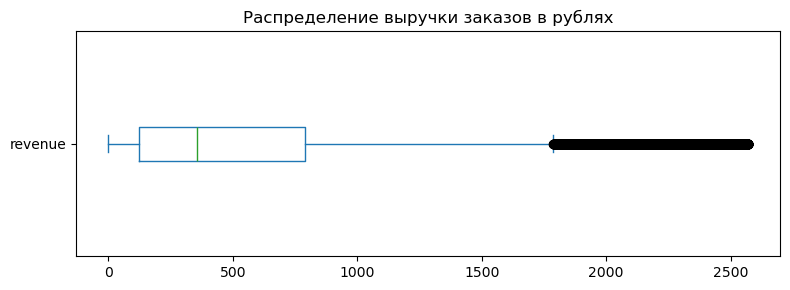

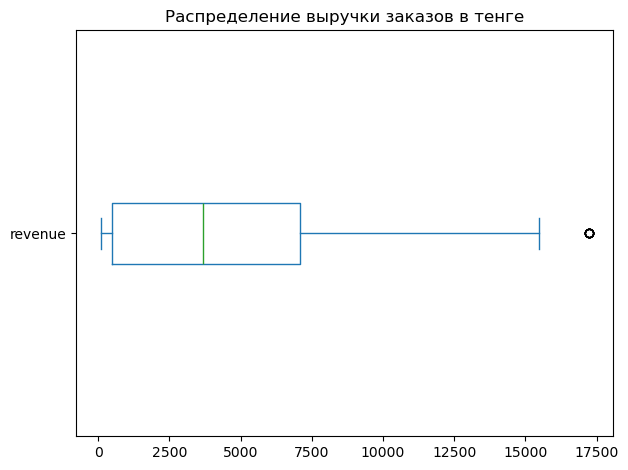

In [30]:
plt.figure(figsize=(8, 3)) 

ru_df['revenue'].plot.box(vert=False)

plt.title('Распределение выручки заказов в рублях')
plt.tight_layout()
plt.show()

kz_df['revenue'].plot.box(vert=False)

plt.title('Распределение выручки заказов в тенге')
plt.tight_layout()
plt.show()

Были обработаны выбросы в выручке заказов раздельно по валютам.  
Было выявлено аномальные значения в  рублевых заказов отрицательные значения так и огромные 80 тыс. что не реально если не  крупный заказ по числу билетов. Данные аномалии не обходимо было исключить из анализа т.к. если даже это не ошибки  то не являются типовым случаем


### пропуски

Пропуски обнаружены в одном столбце он показывает - небыло предыдущей покупки у пользователя их не следует трогать

In [31]:
df_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               290849 non-null  int64         
 1   user_id                290849 non-null  object        
 2   created_dt_msk         290849 non-null  datetime64[ns]
 3   created_ts_msk         290849 non-null  datetime64[ns]
 4   event_id               290849 non-null  int64         
 5   cinema_circuit         290849 non-null  object        
 6   age_limit              290849 non-null  int8          
 7   currency_code          290849 non-null  object        
 8   device_type_canonical  290849 non-null  object        
 9   revenue                290849 non-null  float64       
 10  service_name           290849 non-null  object        
 11  tickets_count          290849 non-null  int8          
 12  total                  290849 non-null  floa

In [32]:
pas = df_order['days_since_prev'].isna().sum()
share_pas = df_order['days_since_prev'].isna().sum()/len(df_order)*100
print(f'Число пропусков {pas}, Доля {share_pas:.2}')

Число пропусков 21940, Доля 7.5


In [33]:
df_order['user_id'].nunique()

21940

выявлено 21940 пропусков их доля состовляет 7,5% что отсносительно значимо, равно числу уникальных пользователей. Значит все пользователи за лето и осень новые либо старые в данной выгрузке отсутствуют

### Объединение датасетов

Необходимо объединить датасеты для анализа, перед этим нудно проверить что ключевые столбцы без дублей, проаерить что в данных курса валют все в порядке

In [34]:
display(df_order.info())
display(df_order.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               290849 non-null  int64         
 1   user_id                290849 non-null  object        
 2   created_dt_msk         290849 non-null  datetime64[ns]
 3   created_ts_msk         290849 non-null  datetime64[ns]
 4   event_id               290849 non-null  int64         
 5   cinema_circuit         290849 non-null  object        
 6   age_limit              290849 non-null  int8          
 7   currency_code          290849 non-null  object        
 8   device_type_canonical  290849 non-null  object        
 9   revenue                290849 non-null  float64       
 10  service_name           290849 non-null  object        
 11  tickets_count          290849 non-null  int8          
 12  total                  290849 non-null  floa

None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               290849 non-null  int64         
 1   user_id                290849 non-null  object        
 2   created_dt_msk         290849 non-null  datetime64[ns]
 3   created_ts_msk         290849 non-null  datetime64[ns]
 4   event_id               290849 non-null  int64         
 5   cinema_circuit         290849 non-null  object        
 6   age_limit              290849 non-null  int8          
 7   currency_code          290849 non-null  object        
 8   device_type_canonical  290849 non-null  object        
 9   revenue                290849 non-null  float64       
 10  service_name           290849 non-null  object        
 11  tickets_count          290849 non-null  int8          
 12  total                  290849 non-null  floa

None

In [35]:
print('Уникальных значений в таблице заказов и дубли: ', df_order['event_id'].nunique(), 
      df_order['event_id'].duplicated().sum(), '\n Уникальных значений в таблице заказов и дубли: ', 
      df_event['event_id'].nunique(), df_event['event_id'].duplicated().sum())

Уникальных значений в таблице заказов и дубли:  22446 268403 
 Уникальных значений в таблице заказов и дубли:  22427 0


Выявлены разница уникальных значений по id событий на 1, либо по событию вооще не было покупок, наприемер еще не начата продажа или ошибки.
В таблице мероприятий нет дублей, а в таблице заказов есть т.к. каждая покупка может быть много покупок на одно событие
событие без покупок будет исключено при присоединение таблиц осталя все строки из таблицы заказов и пересечения двух таблиц

In [36]:
df_tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   data     357 non-null    datetime64[ns]
 1   nominal  357 non-null    int64         
 2   curs     357 non-null    float64       
 3   cdx      357 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 11.3+ KB


In [37]:
col1= ['data', 'curs']

for i in df_tenge:
    print(df_tenge[col1].nunique())

data    357
curs    248
dtype: int64
data    357
curs    248
dtype: int64
data    357
curs    248
dtype: int64
data    357
curs    248
dtype: int64


In [38]:
df_tenge['curs'].unique()

array([19.9391, 19.7255, 19.5839, 19.4501, 19.4264, 19.4177, 19.5798,
       19.5741, 19.6081, 19.5477, 19.5983, 19.793 , 19.9035, 20.0695,
       19.9246, 19.8428, 20.0075, 20.1523, 20.1634, 20.2206, 20.0115,
       20.0513, 20.1832, 20.1826, 20.3703, 20.4167, 20.4093, 20.5344,
       20.6555, 20.596 , 20.5156, 20.4086, 20.575 , 20.5904, 20.4557,
       20.4659, 20.1286, 20.2689, 20.2544, 20.1082, 20.0522, 20.2783,
       20.2609, 20.245 , 20.375 , 20.3685, 20.4537, 20.5054, 20.5262,
       20.5476, 20.3758, 20.5225, 20.5589, 20.5142, 20.5728, 20.522 ,
       20.6105, 20.657 , 20.7196, 20.6442, 20.6542, 20.6982, 20.7218,
       20.7975, 20.8947, 20.9593, 20.8385, 20.8956, 20.9725, 21.0165,
       20.9611, 20.8853, 20.8856, 20.9334, 20.8196, 20.7573, 20.7135,
       20.7013, 20.8243, 20.6807, 20.6748, 20.7367, 20.8961, 20.8541,
       20.7201, 20.698 , 20.5985, 20.6049, 20.4433, 20.3751, 20.4139,
       20.4279, 20.2475, 20.012 , 19.9705, 20.2131, 20.2748, 20.2773,
       19.9833, 19.8

In [39]:
df_tenge['curs'].describe()

count    357.000000
mean      19.755818
std        0.833798
min       17.848600
25%       19.120200
50%       19.876000
75%       20.443300
max       21.937100
Name: curs, dtype: float64

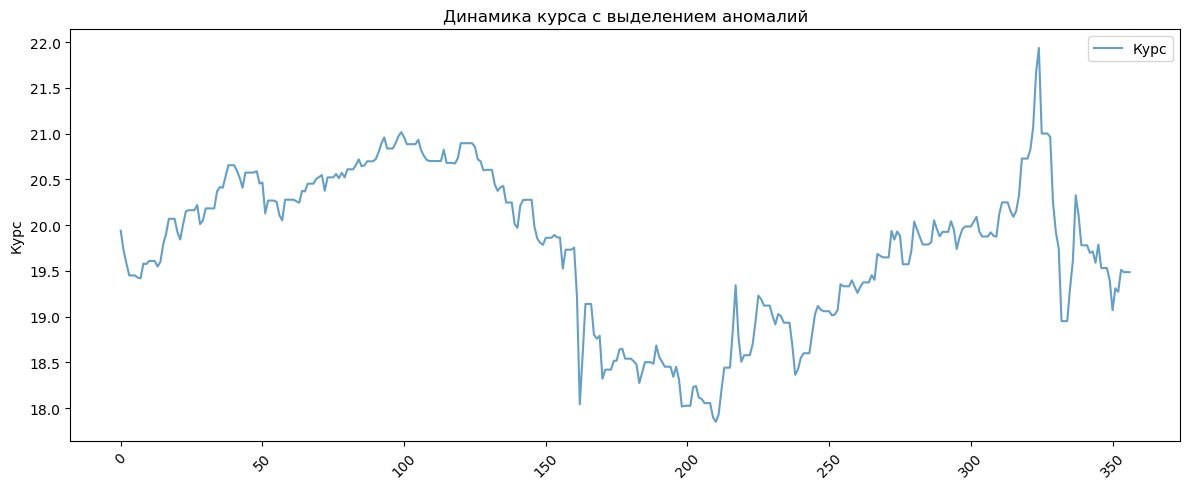

In [40]:
plt.figure(figsize=(12, 5))

# Рисуем основной график курса
plt.plot(df_tenge.index, df_tenge['curs'],label='Курс', alpha=0.7)


plt.title('Динамика курса с выделением аномалий')
plt.ylabel('Курс')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Данные без проблем можнол использовать в дальнейшей работе без обработки

In [41]:
df_tenge['data'].min(), df_tenge['data'].max()

(Timestamp('2024-01-10 00:00:00'), Timestamp('2024-12-31 00:00:00'))

In [42]:
df_tenge_actual = df_tenge[(df_tenge['data'] >= '2024-6-1') & (df_tenge['data'] <= '2024-10-31')]
df_tenge_actual['data'].min(), df_tenge_actual['data'].max()

(Timestamp('2024-06-01 00:00:00'), Timestamp('2024-10-31 00:00:00'))

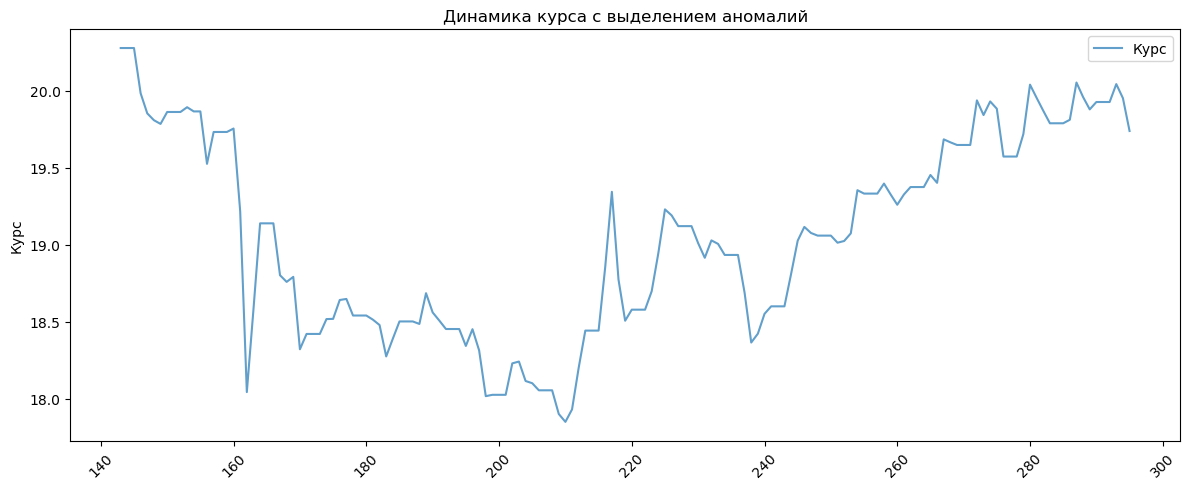

In [43]:
plt.figure(figsize=(12, 5))

# Рисуем основной график курса
plt.plot(df_tenge_actual.index, df_tenge_actual['curs'],label='Курс', alpha=0.7)


plt.title('Динамика курса с выделением аномалий')
plt.ylabel('Курс')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Данные не прерывны, значения адекватные, за период анализа

In [44]:
keys_order = set(df_order['event_id'].unique())
keys_event = set(df_event['event_id'].unique())
common_keys = keys_order & keys_event 
print('Пересечение событий', len(common_keys))
only_left = keys_order - keys_event
print('События которые теряются', len(only_left))
only_right = keys_event - keys_order
print('События которые теряются', len(only_right))

Пересечение событий 22427
События которые теряются 19
События которые теряются 0


In [45]:
lost_events = df_order[df_order['event_id'].isin(only_left)]
print(len(lost_events))

238


В таблице с заказами есть меропрития которых нет в таблице мероприйтия, по скольоку их категоризировать не получится следует их исключить, потеряно 238 заказа

In [46]:
df_final = df_order.merge(df_event, on='event_id', how='inner')
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290611 non-null  int64         
 1   user_id                 290611 non-null  object        
 2   created_dt_msk          290611 non-null  datetime64[ns]
 3   created_ts_msk          290611 non-null  datetime64[ns]
 4   event_id                290611 non-null  int64         
 5   cinema_circuit          290611 non-null  object        
 6   age_limit               290611 non-null  int8          
 7   currency_code           290611 non-null  object        
 8   device_type_canonical   290611 non-null  object        
 9   revenue                 290611 non-null  float64       
 10  service_name            290611 non-null  object        
 11  tickets_count           290611 non-null  int8          
 12  total                   290611

In [47]:
df_final = df_final.rename(columns={'created_dt_msk': 'data'})
df_curs = df_tenge[['data', 'curs']]

In [48]:
df_final = df_final.merge(df_curs, on='data', how='left')
display(df_final.head())

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address,curs
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,спектакль,театр,№3322,Каменевский регион,Глиногорск,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,событие,выставки,№4850,Каменевский регион,Глиногорск,213,2941,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,цирковое шоу,другое,№1540,Каменевский регион,Глиногорск,213,4507,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",19.6475
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,выставка,другое,№5049,Североярская область,Озёрск,2,3574,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",18.5010
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,шоу,стендап,№832,Озернинский край,Родниковецк,240,1896,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",19.6648


In [49]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290611 non-null  int64         
 1   user_id                 290611 non-null  object        
 2   data                    290611 non-null  datetime64[ns]
 3   created_ts_msk          290611 non-null  datetime64[ns]
 4   event_id                290611 non-null  int64         
 5   cinema_circuit          290611 non-null  object        
 6   age_limit               290611 non-null  int8          
 7   currency_code           290611 non-null  object        
 8   device_type_canonical   290611 non-null  object        
 9   revenue                 290611 non-null  float64       
 10  service_name            290611 non-null  object        
 11  tickets_count           290611 non-null  int8          
 12  total                   290611

In [50]:
for i in df_final:
    print([i], df_final[i].isna().sum())

['order_id'] 0
['user_id'] 0
['data'] 0
['created_ts_msk'] 0
['event_id'] 0
['cinema_circuit'] 0
['age_limit'] 0
['currency_code'] 0
['device_type_canonical'] 0
['revenue'] 0
['service_name'] 0
['tickets_count'] 0
['total'] 0
['days_since_prev'] 21913
['event_name'] 0
['event_type_description'] 0
['event_type_main'] 0
['organizers'] 0
['region_name'] 0
['city_name'] 0
['city_id'] 0
['venue_id'] 0
['venue_name'] 0
['venue_address'] 0
['curs'] 0


Пропуски есть только в одной колонке как и должно быть

### Создание новых столбцов

Для проведение дальнейшего анализ необходимо подготолвить новые столбцы:

* revenue_rub — приведите выручку с заказа к единой валюте — российскому рублю. 
* one_ticket_revenue_rub — выручку с продажи одного билета на мероприятие.
* month — выделить месяц оформления заказа.
* season —  столбец с информацией о сезонности: 'лето', 'осень', 'зима', 'весна'.

In [51]:
df_final['sum_rub'] = 0
display(df_final.head())

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address,curs,sum_rub
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,театр,№3322,Каменевский регион,Глиногорск,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972,0
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,выставки,№4850,Каменевский регион,Глиногорск,213,2941,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419,0
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,другое,№1540,Каменевский регион,Глиногорск,213,4507,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",19.6475,0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,другое,№5049,Североярская область,Озёрск,2,3574,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",18.5010,0
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,стендап,№832,Озернинский край,Родниковецк,240,1896,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",19.6648,0


In [52]:
# Столбце с рублевой выручкой
df_final['revenue_rub'] = np.where(
    df_final['currency_code'] == 'rub',
    df_final['revenue'],
    (df_final['revenue'] * df_final['curs']) / 100)
df_final.head()

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address,curs,sum_rub,revenue_rub
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,№3322,Каменевский регион,Глиногорск,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972,0,1521.94
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,№4850,Каменевский регион,Глиногорск,213,2941,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419,0,289.45
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,№1540,Каменевский регион,Глиногорск,213,4507,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",19.6475,0,1258.57
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,№5049,Североярская область,Озёрск,2,3574,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",18.5010,0,8.49
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,№832,Озернинский край,Родниковецк,240,1896,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",19.6648,0,1390.41


In [53]:
#  создание столбца с ценной за 1 билет в рублях
df_final['one_ticket_revenue_rub'] = df_final['revenue_rub']/df_final['tickets_count']
df_final['month'] = df_final['data'].dt.month
display(df_final.head())

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,city_name,city_id,venue_id,venue_name,venue_address,curs,sum_rub,revenue_rub,one_ticket_revenue_rub,month
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,Глиногорск,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972,0,1521.94,380.4850,8
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,Глиногорск,213,2941,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419,0,289.45,144.7250,7
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,Глиногорск,213,4507,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",19.6475,0,1258.57,314.6425,10
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,Озёрск,2,3574,"Театр альтернативного искусства ""Ода"" Лимитед","алл. Есенина, д. 243 к. 3/8",18.5010,0,8.49,4.2450,7
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,Родниковецк,240,1896,"Театр кукол ""Огни"" Инкорпорэйтед","ш. Набережное, д. 595 стр. 8",19.6648,0,1390.41,463.4700,10


In [54]:
# создание столбца сезона
def get_season(month):
    if month in [12, 1, 2]:
        return 'зима'
    elif month in [3, 4, 5]:
        return 'весна'
    elif month in [6, 7, 8]:
        return 'лето'
    else:
        return 'осень'

df_final['season'] = df_final['data'].dt.month.apply(get_season)
display(df_final.head(3))
display(df_final.tail(3))

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,city_id,venue_id,venue_name,venue_address,curs,sum_rub,revenue_rub,one_ticket_revenue_rub,month,season
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972,0,1521.94,380.4850,8,лето
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,213,2941,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419,0,289.45,144.7250,7,лето
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,213,4507,"Училище искусств ""Нирвана"" Инк","алл. Юбилейная, д. 5/6",19.6475,0,1258.57,314.6425,10,осень


,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,city_id,venue_id,venue_name,venue_address,curs,sum_rub,revenue_rub,one_ticket_revenue_rub,month,season
290608,8473772,fffcd3dde79eb2c,2024-10-30,2024-10-30 13:37:43,205231,нет,16,rub,desktop,178.95,...,213,3470,"Клуб киноманов ""Верность"" Лтд","пр. Титова, д. 5 стр. 68",19.9516,0,178.95,89.475,10,осень
290609,5526067,fffeeb3c120cf0b,2024-09-24,2024-09-24 10:07:42,454526,нет,18,rub,desktop,661.53,...,239,2449,"Гильдия художников ""Флит"" Инк","пр. Макарова, д. 4",19.3967,0,661.53,330.765,9,осень
290610,813654,ffff00725179321,2024-09-25,2024-09-25 15:12:40,284965,нет,16,rub,mobile,802.25,...,197,4113,"Мастерская живого действия ""Гардероб"" Лимитед","ш. 30 лет Победы, д. 38 стр. 664",19.3262,0,802.25,401.125,9,осень


In [55]:
df_final['revenue_rub'].describe()

count    290611.000000
mean        555.571987
std         875.498172
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64

In [56]:
print(df_final['revenue_rub'].quantile(0.99))
print(df_final['revenue_rub'].quantile(0.01))

2628.4217390400004
0.0


In [57]:
high = df_final['revenue_rub'].quantile(0.99)
low = df_final['revenue_rub'].quantile(0.01)

In [58]:
df_final = df_final[(df_final['revenue_rub']> low) & (df_final['revenue_rub'] < high)]
df_final['revenue_rub'].describe()

count    281697.000000
mean        527.531834
std         509.091254
min           0.020000
25%         122.610000
50%         357.990000
75%         796.360000
max        2627.000000
Name: revenue_rub, dtype: float64

{'whiskers': [<matplotlib.lines.Line2D at 0x21e13524190>,
 'caps': [<matplotlib.lines.Line2D at 0x21e13524410>,
 'boxes': [<matplotlib.lines.Line2D at 0x21e13524050>],
 'medians': [<matplotlib.lines.Line2D at 0x21e13524690>],
 'fliers': [<matplotlib.lines.Line2D at 0x21e135247d0>],
 'means': []}

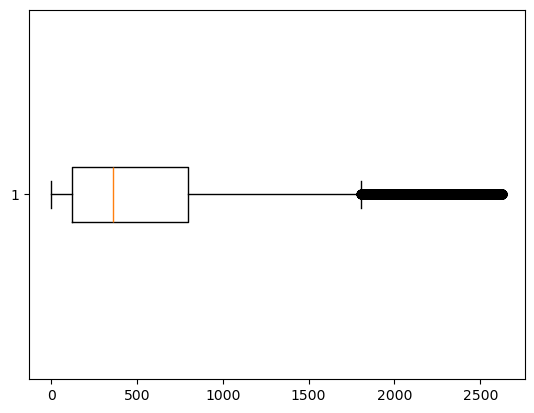

In [59]:
plt.boxplot(df_final['revenue_rub'], vert=False)

{'whiskers': [<matplotlib.lines.Line2D at 0x21e1355f4d0>,
 'caps': [<matplotlib.lines.Line2D at 0x21e1355f750>,
 'boxes': [<matplotlib.lines.Line2D at 0x21e1355f390>],
 'medians': [<matplotlib.lines.Line2D at 0x21e1355f9d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x21e1355fb10>],
 'means': []}

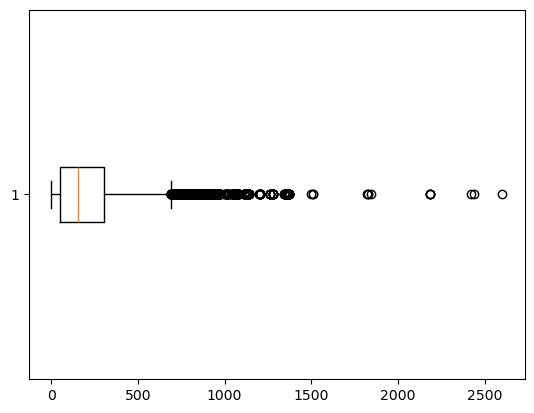

In [60]:
plt.boxplot(df_final['one_ticket_revenue_rub'], vert=False)

In [61]:
    Q1 = df_final['revenue_rub'].quantile(0.25)
    Q3 = df_final['revenue_rub'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_final = df_final[
        (df_final['revenue_rub'] >= lower_bound) &
        (df_final['revenue_rub'] <= upper_bound)]


{'whiskers': [<matplotlib.lines.Line2D at 0x21e0ccf7110>,
 'caps': [<matplotlib.lines.Line2D at 0x21e0ccf5a90>,
 'boxes': [<matplotlib.lines.Line2D at 0x21e0ccf7250>],
 'medians': [<matplotlib.lines.Line2D at 0x21e0ccf5f90>],
 'fliers': [<matplotlib.lines.Line2D at 0x21e0ccf5e50>],
 'means': []}

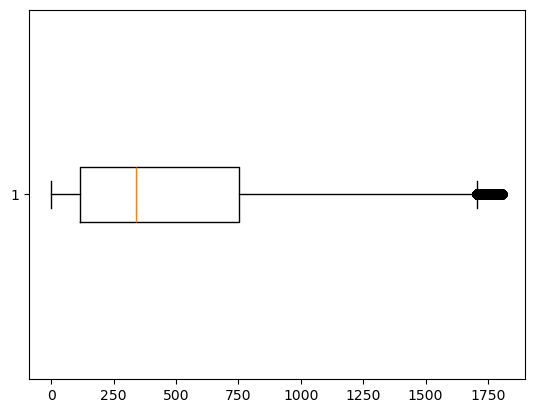

In [62]:
plt.boxplot(df_final['revenue_rub'], vert=False)

{'whiskers': [<matplotlib.lines.Line2D at 0x21e0b12f610>,
 'caps': [<matplotlib.lines.Line2D at 0x21e0b12f390>,
 'boxes': [<matplotlib.lines.Line2D at 0x21e0b12f750>],
 'medians': [<matplotlib.lines.Line2D at 0x21e0b12f890>],
 'fliers': [<matplotlib.lines.Line2D at 0x21e0cb3f9d0>],
 'means': []}

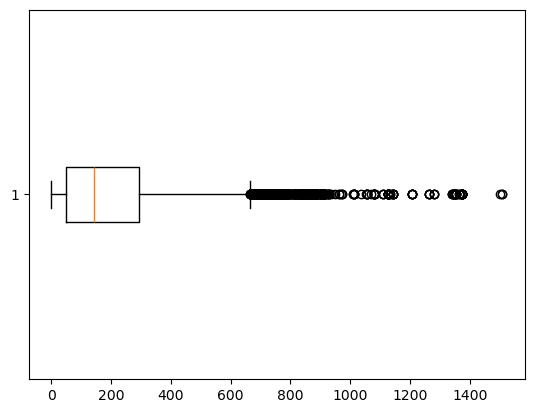

In [63]:
plt.boxplot(df_final['one_ticket_revenue_rub'], vert=False)

Несмотря на то что были исключены аномально высокие значения по выручки, остается много аномлаьных выброос по ценне за 1 билет. т.е. много выбросов не из за отдельных высоких заказов а из за отдельных меропритий


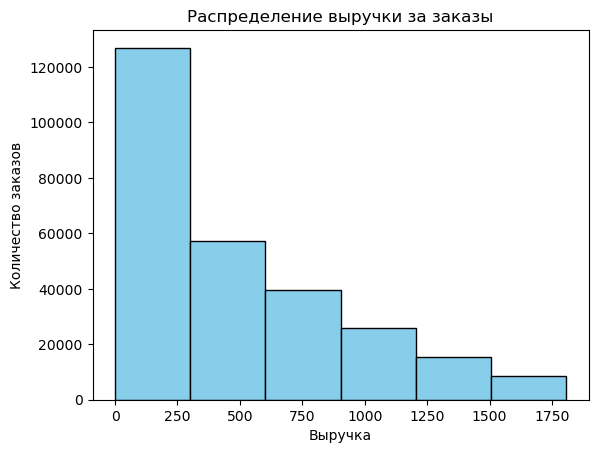

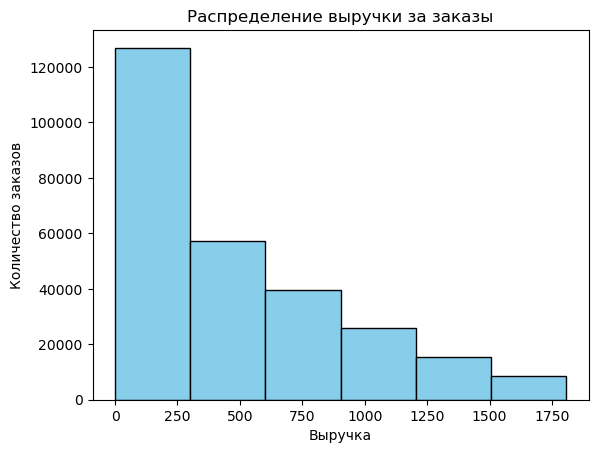

In [64]:
plt.hist(df_final['revenue_rub'], bins=6, color='skyblue', edgecolor='black')


plt.xlabel('Выручка')
plt.ylabel('Количество заказов')
plt.title('Распределение выручки за заказы')


plt.show()

plt.hist(df_final['revenue_rub'], bins=6, color='skyblue', edgecolor='black')


plt.xlabel('Выручка')
plt.ylabel('Количество заказов')
plt.title('Распределение выручки за заказы')

plt.show()

In [65]:
df_final.groupby('season')['revenue_rub'].value_counts()

season  revenue_rub
лето    1183.35        506
        788.90         425
        1577.80        311
        1308.74        309
        872.49         279
                      ... 
осень   1802.92          1
        1804.28          1
        1804.80          1
        1804.99          1
        1805.97          1
Name: count, Length: 54815, dtype: int64

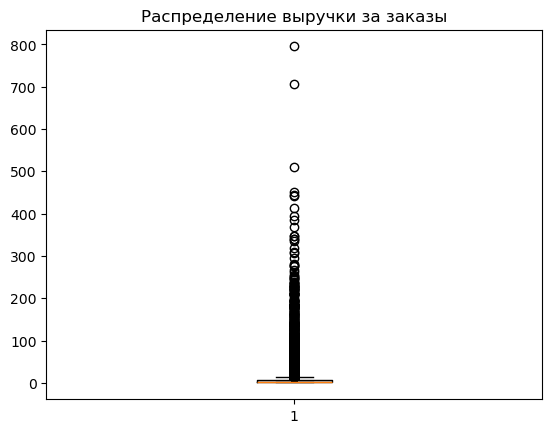

In [66]:
plt.boxplot(df_final['revenue_rub'].value_counts())


plt.xlabel('')
plt.ylabel('')
plt.title('Распределение выручки за заказы')


plt.show()

партнерам, устройствам, возрастным рейтингам

In [67]:
print(df_final['service_name'].describe())
print()
print(round(df_final['service_name'].value_counts(normalize=True)*100, 2))

count                 273611
unique                    36
top       Билеты без проблем
freq                   56452
Name: service_name, dtype: object

service_name
Билеты без проблем        20.63
Лови билет!               14.54
Билеты в руки             14.43
Мой билет                 11.99
Облачко                    9.38
Лучшие билеты              6.41
Весь в билетах             5.47
Прачечная                  3.67
Край билетов               2.05
Тебе билет!                1.84
Яблоко                     1.76
Дом культуры               1.52
За билетом!                1.03
Городской дом культуры     0.98
Мир касс                   0.75
Show_ticket                0.72
Быстробилет                0.71
Выступления.ру             0.56
Восьмёрка                  0.40
Crazy ticket!              0.28
Шоу начинается!            0.15
Радио ticket               0.14
Быстрый кассир             0.13
Телебилет                  0.12
Росбилет                   0.12
КарандашРУ                 0.05
Реес

In [68]:
print(df_final['device_type_canonical'].describe())
print()
print(round(df_final['device_type_canonical'].value_counts(normalize=True)*100, 2))

count     273611
unique         2
top       mobile
freq      219599
Name: device_type_canonical, dtype: object

device_type_canonical
mobile     80.26
desktop    19.74
Name: proportion, dtype: float64


In [69]:
print(df_final['age_limit'].describe())
print()
print(round(df_final['age_limit'].value_counts(normalize=True)*100, 2))

count    273611.000000
mean         10.112422
std           6.543038
min           0.000000
25%           6.000000
50%          12.000000
75%          16.000000
max          18.000000
Name: age_limit, dtype: float64

age_limit
16    27.30
0     21.77
12    21.32
6     17.87
18    11.74
Name: proportion, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

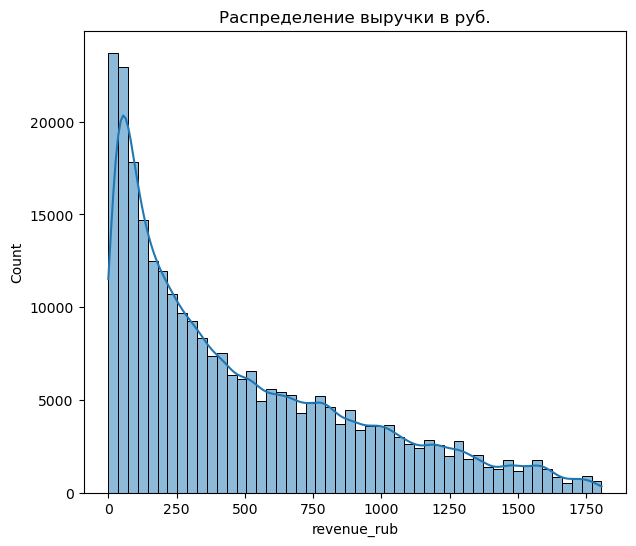

In [70]:
plt.figure(figsize=(7, 6))
sns.histplot(df_final['revenue_rub'], bins=50, kde=True)

plt.title('Распределение выручки в руб.')
plt.show

In [71]:
df_final['device_type_canonical'].value_counts()

device_type_canonical
mobile     219599
desktop     54012
Name: count, dtype: int64

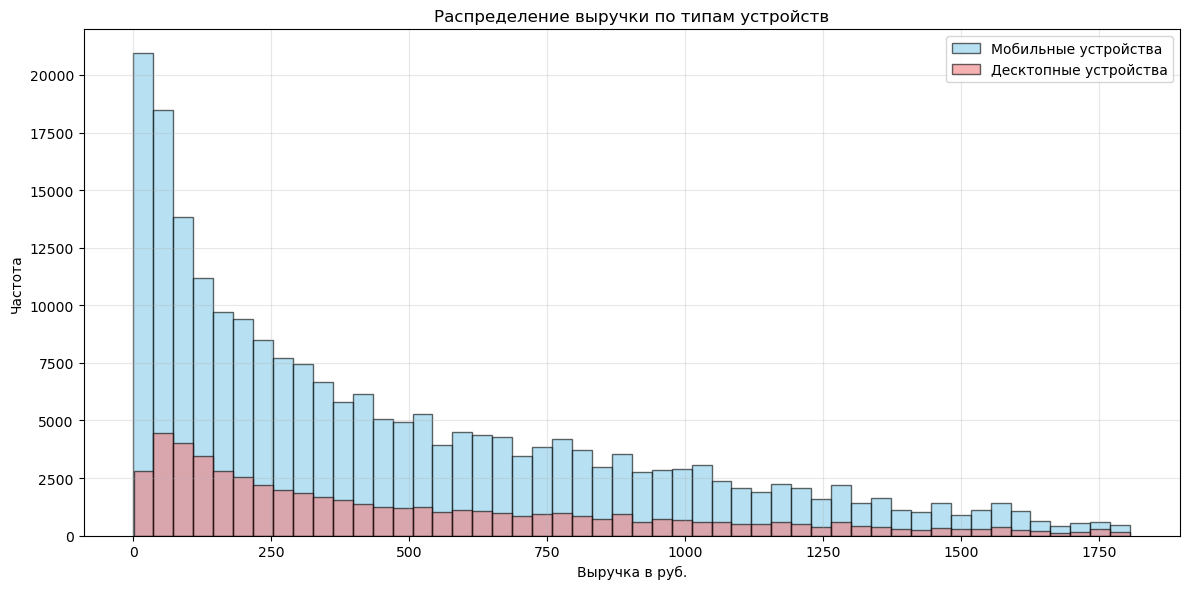

In [72]:

mobile = df_final[df_final['device_type_canonical'] == 'mobile']
desktop = df_final[df_final['device_type_canonical'] == 'desktop']

plt.figure(figsize=(12, 6))

plt.hist(
    mobile['revenue_rub'],  
    bins=50,
    alpha=0.6,
    label='Мобильные устройства',
    color='skyblue',
    edgecolor='black'
)

plt.hist(
    desktop['revenue_rub'],
    bins=50,
    alpha=0.6,
    label='Десктопные устройства',
    color='lightcoral',
    edgecolor='black'
)

plt.title('Распределение выручки по типам устройств')
plt.xlabel('Выручка в руб.')
plt.ylabel('Частота')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

C:\Users\User\AppData\Local\Temp\ipykernel_19680\3078625917.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


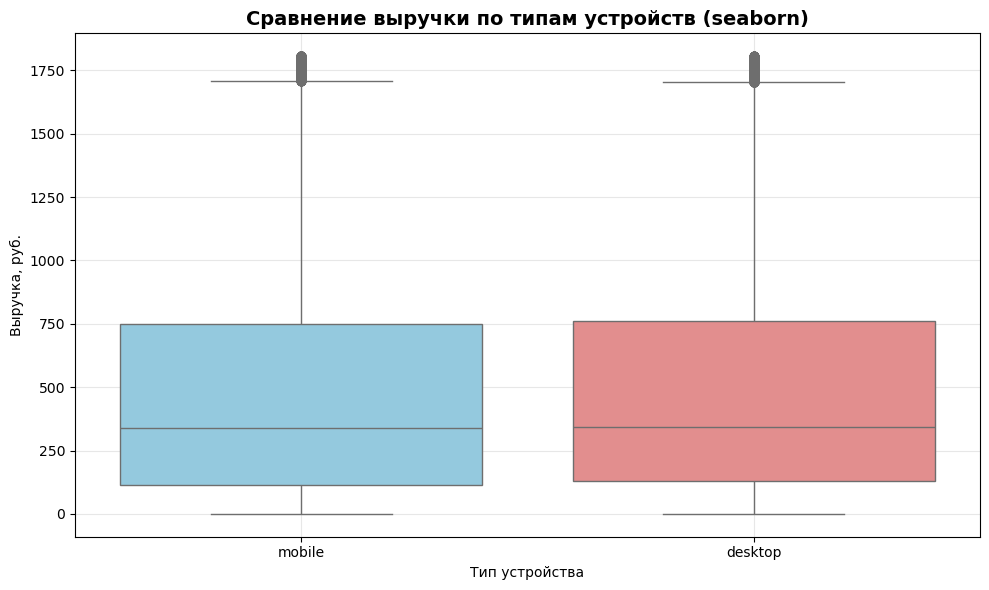

In [73]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_final,
    x='device_type_canonical',
    y='revenue_rub',
    order=['mobile', 'desktop'],
    palette={'mobile': 'skyblue', 'desktop': 'lightcoral'}
)
plt.title('Сравнение выручки по типам устройств (seaborn)', fontsize=14, fontweight='bold')
plt.xlabel('Тип устройства')
plt.ylabel('Выручка, руб.')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

Основная доля пользователей ипользует мобильные устройства, при этом по ценне нет разницы в типе устройств одинаковый средний чек.
Сточкий зрения стабильности работы приложения необходимо делать упор на мобльное приложение а не десктопное. Средний чек следует менять равномерно.

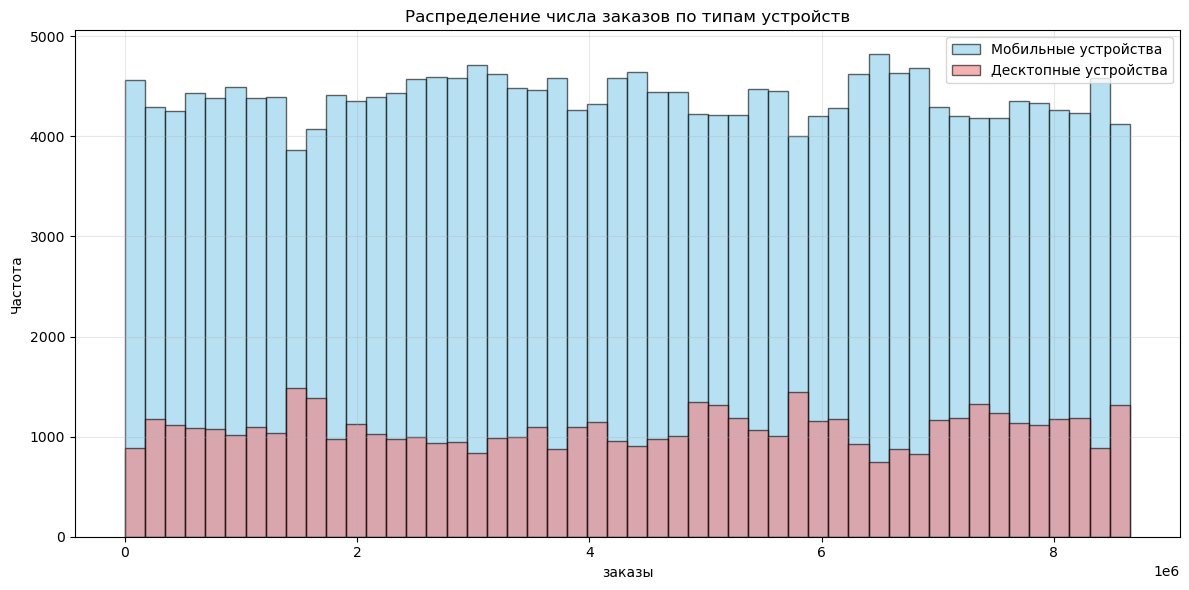

In [74]:
plt.figure(figsize=(12, 6))

plt.hist(
    mobile['order_id'],  
    bins=50,
    alpha=0.6,
    label='Мобильные устройства',
    color='skyblue',
    edgecolor='black'
)

plt.hist(
    desktop['order_id'],
    bins=50,
    alpha=0.6,
    label='Десктопные устройства',
    color='lightcoral',
    edgecolor='black'
)

plt.title('Распределение числа заказов по типам устройств')
plt.xlabel('заказы')
plt.ylabel('Частота')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

По количеству заказов распределены равномерно

In [75]:
df_final['season'].value_counts()

season
осень    163759
лето     109852
Name: count, dtype: int64

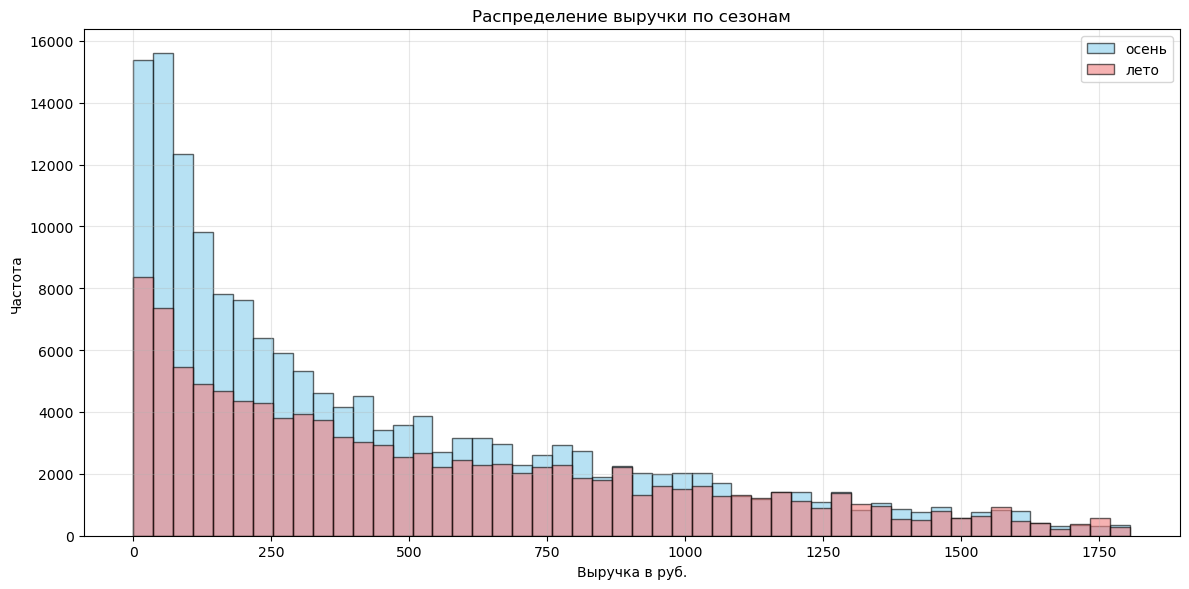

In [76]:

autumn = df_final[df_final['season'] == 'осень']
summer = df_final[df_final['season'] == 'лето']

plt.figure(figsize=(12, 6))

plt.hist(
    autumn['revenue_rub'],  
    bins=50,
    alpha=0.6,
    label='осень',
    color='skyblue',
    edgecolor='black'
)

plt.hist(
    summer['revenue_rub'],
    bins=50,
    alpha=0.6,
    label='лето',
    color='lightcoral',
    edgecolor='black'
)

plt.title('Распределение выручки по сезонам')
plt.xlabel('Выручка в руб.')
plt.ylabel('Частота')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

C:\Users\User\AppData\Local\Temp\ipykernel_19680\208495213.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


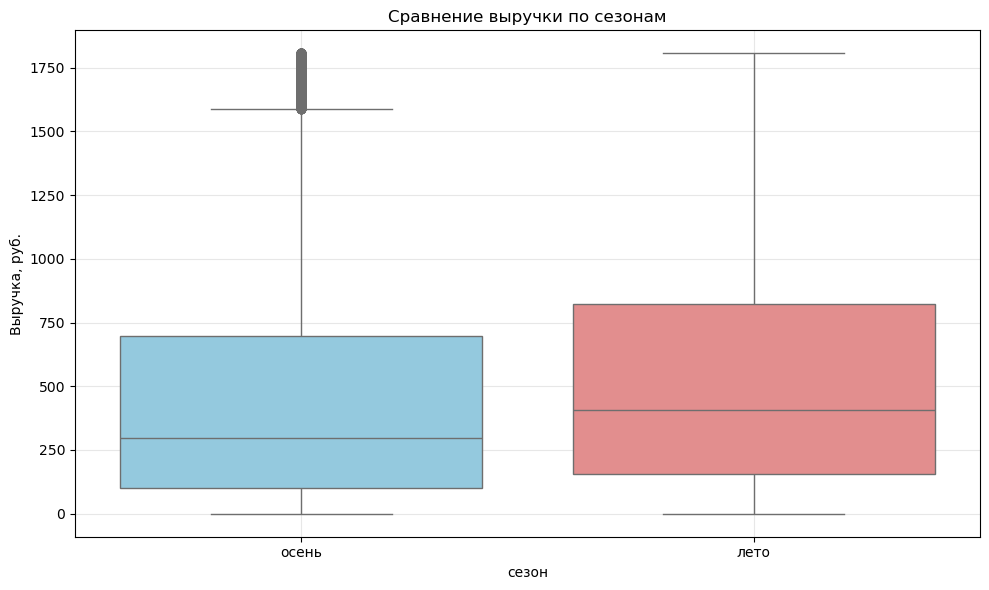

In [77]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_final,
    x='season',
    y='revenue_rub',
    order=['осень', 'лето'],
    palette={'осень': 'skyblue', 'лето': 'lightcoral'}
)
plt.title('Сравнение выручки по сезонам')
plt.xlabel('сезон')
plt.ylabel('Выручка, руб.')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

В летний период около двух раз ниже выручка от дешевых закзазов, при этом дорогие более менее равны

в летний период средний чек выше, чем осенью, что с учтом распредление говорит о том что меньше дешевых заказовЮ число доогих такое же 

Осенью больше заказов, но в низком ценновом сегменте, что снижается средний чек

In [78]:
df_final['season'].value_counts()

season
осень    163759
лето     109852
Name: count, dtype: int64

In [79]:
df_final.groupby('season')['event_id'].nunique()/df_final['event_id'].nunique()

season
лето     0.537958
осень    0.717004
Name: event_id, dtype: float64

In [80]:
df_final.groupby('season')['event_id'].nunique()

season
лето     11763
осень    15678
Name: event_id, dtype: int64

C:\Users\User\AppData\Local\Temp\ipykernel_19680\1652255256.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


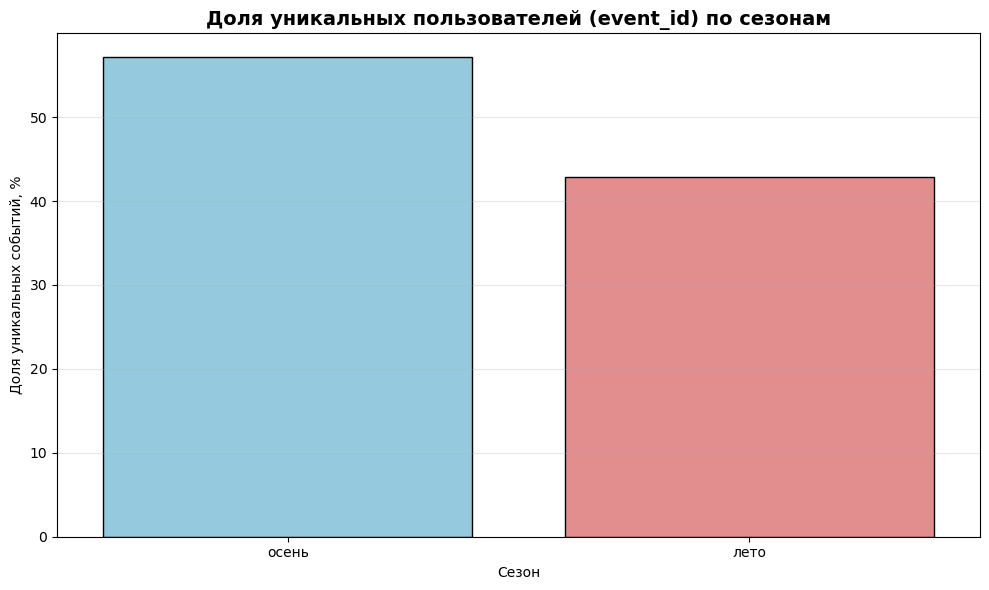

Абсолютное количество уникальных событий:
season
лето     11763
осень    15678
Name: event_id, dtype: int64


In [81]:
unique_col = 'event_id' 

unique_counts = df_final.groupby('season')[unique_col].nunique()

unique_percent = (unique_counts / unique_counts.sum()) * 100

unique_df = unique_percent.reset_index()
unique_df.columns = ['season', 'percentage']


plt.figure(figsize=(10, 6))

order = ['осень', 'лето'] 

sns.barplot(
    data=unique_df, 
    x='season', 
    y='percentage', 
    order=order,
    palette=['skyblue', 'lightcoral'],
    edgecolor='black'
)

plt.title(f'Доля уникальных пользователей ({unique_col}) по сезонам', fontsize=14, fontweight='bold')
plt.xlabel('Сезон')
plt.ylabel('Доля уникальных событий, %')
plt.grid(axis='y',  alpha=0.3)
plt.tight_layout()
plt.show()

print("Абсолютное количество уникальных событий:")
print(unique_counts)

Осенью в 1,5 раза больше мероприятий, что и объясняет рост осенью в два раза больше закзов дешевом сегменте

In [82]:
display(df_final.groupby('season')['service_name'].value_counts(normalize=True).head())
display(autumn['service_name'].value_counts(normalize=True).head())
display(summer['service_name'].value_counts(normalize=True).head())

season  service_name      
лето    Билеты без проблем    0.229217
        Лови билет!           0.131923
        Билеты в руки         0.128764
        Мой билет             0.126370
        Облачко               0.096202
Name: proportion, dtype: float64

service_name
Билеты без проблем    0.190964
Билеты в руки         0.154691
Лови билет!           0.154453
Мой билет             0.115548
Облачко               0.092196
Name: proportion, dtype: float64

service_name
Билеты без проблем    0.229217
Лови билет!           0.131923
Билеты в руки         0.128764
Мой билет             0.126370
Облачко               0.096202
Name: proportion, dtype: float64

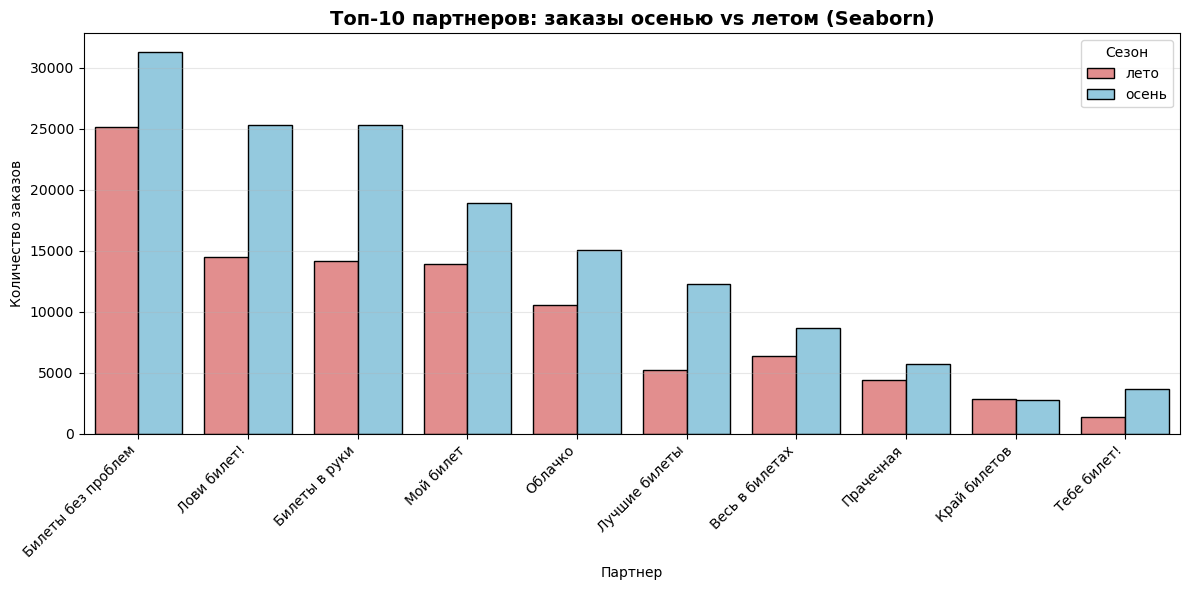

In [83]:
df_pivot = pd.pivot_table(df_final,  values='order_id',           
    index='service_name',             
    columns='season',           
    aggfunc='count')

df_pivot['Total'] = df_pivot.sum(axis=1)
df_top10 = df_pivot.nlargest(10, 'Total').drop(columns='Total')

# 3. Превращаем широкую таблицу в длинную (это ключевой шаг для seaborn!)
df_long = df_top10.reset_index().melt(
    id_vars='service_name', 
    var_name='season', 
    value_name='orders'
)

# 4. Теперь sns.barplot сработает идеально
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_long, 
    x='service_name', 
    y='orders', 
    hue='season',
    palette={'осень': 'skyblue', 'лето': 'lightcoral'},
    edgecolor='black'
)

plt.title('Топ-10 партнеров: заказы осенью vs летом (Seaborn)', fontsize=14, fontweight='bold')
plt.xlabel('Партнер')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
df_final['service_name'].value_counts(normalize=True)

service_name
Билеты без проблем        0.206322
Лови билет!               0.145407
Билеты в руки             0.144281
Мой билет                 0.119893
Облачко                   0.093805
Лучшие билеты             0.064076
Весь в билетах            0.054742
Прачечная                 0.036702
Край билетов              0.020471
Тебе билет!               0.018376
Яблоко                    0.017620
Дом культуры              0.015157
За билетом!               0.010336
Городской дом культуры    0.009777
Мир касс                  0.007507
Show_ticket               0.007229
Быстробилет               0.007112
Выступления.ру            0.005628
Восьмёрка                 0.003998
Crazy ticket!             0.002840
Шоу начинается!           0.001477
Радио ticket              0.001374
Быстрый кассир            0.001265
Телебилет                 0.001173
Росбилет                  0.001166
КарандашРУ                0.000486
Реестр                    0.000453
Билет по телефону         0.000300
Вперёд!

### Вывод

Выгружено 3 датасета предварительно изучены и обработаны
* дубликатов не обнаружено.
* Обработаны столбцы в df_order возрастные категории и количетсов билетов снижение разрядности к int8
* Обработаны 2 столбца в df_order дат вместо object к типу to_datetime. в df_tenge столбец дата к типу to_datetime 
* были обнаружены аномалли в столбце выручки (отрицательные значения и крайне высокие) вероятностьт ошибки присутсвтует было удалено по разделению на валюты строк: руб. 8970, тенге 283
* найдено пропусков 21940, 7.5% не тронуты т.к. это первые покупки пользователей
* объединены 3 дата сета в один, при объединение были потерены строки т.к. в закзах были мероприятия неучтеные в датасете мероприятий, были по итогу пропуски. дата сет валют был частично добавлен не все колонки
* Созданы новые столобцы revenue_rub, one_ticket_revenue_rub, month, season.
* Проведено иследование столбцов признаков 

## Анализ

### Анализ распределения заказов по сегментам и их сезонные изменения

В рамаках анализа необходимо выявить изменения пользовательских предпочтений и популярности событий. Для этого будет проведен анализ:
1. Распределения заказов по сегментам и их сезонные изменения в разрезе тип мероприятия, тип устройства, категория мероприятий по возрастному рейтингу.

    1 Для каждого месяца найдите количество заказов
    
    2 Для осеннего и летнего периодов сравните распределение заказов билетов
    
    3 Изменение выручки с продажи одного билет


2. Осенняя активность пользователей

    1 анализ динамики изменений по дням для:
- общего числа заказов;
- количества активных пользователей DAU;
- среднего числа заказов на одного пользователя;
- средней стоимости одного билета.

    2  недельную цикличность
    
3. Популярных событий и партнёров
- по регионам расчитать кол-во событий и партнеров
- По билетным партнёрам расчитать число мероприятий, число заказов, выручку с заказов билетов. 

4. Статистический анализ данных

#### По месячный анализ

In [85]:
l = ['event_type_main', 'device_type_canonical', 'age_limit']

In [86]:
pivot_t = pd.pivot_table(df_final, index='event_type_main', columns='month', values='order_id',  aggfunc='count')
pivot_t_percent = (pivot_t.div(pivot_t.sum(axis=1), axis=0) * 100).round(2) 

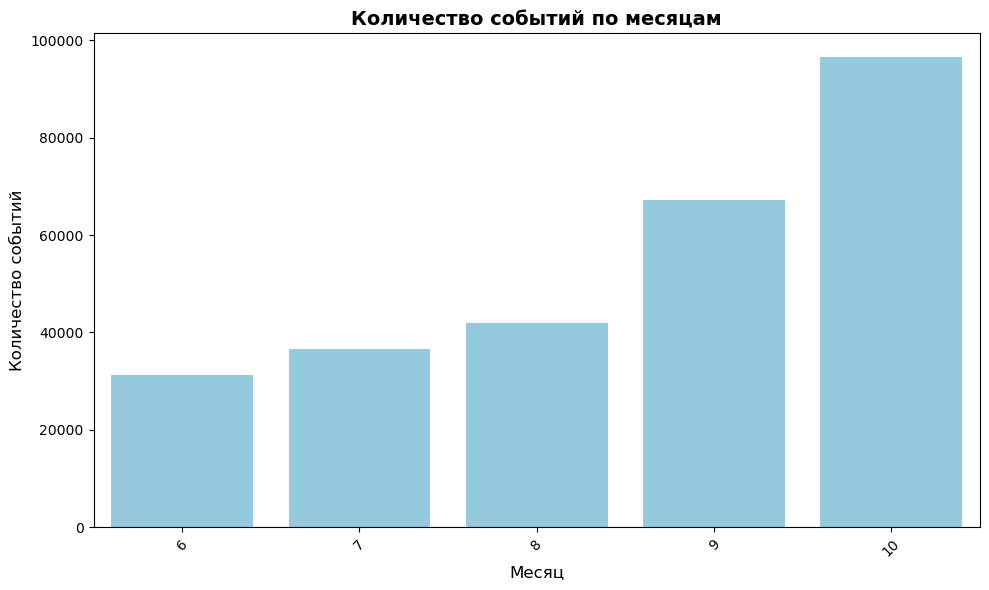

In [87]:
monthly_counts = df_final.groupby('month')['event_type_main'].count().reset_index()
monthly_counts.rename(columns={'event_type_main': 'event_count'}, inplace=True)

plt.figure(figsize=(10, 6))  # Задаем размер графика: ширина 10, высота 6 дюймов

sns.barplot(
    data=monthly_counts,  
    x='month',            
    y='event_count',      
    color='skyblue')

plt.title('Количество событий по месяцам', fontsize=14, fontweight='bold')
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Количество событий', fontsize=12)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

В течении лета было незначительный рост, основной бум пришелся на сентябрь и в октябре темп поддерживал
основная доля мероприятий приходится на осень 

In [88]:
for i in l:
    df_final.groupby('month')[i].count()
    print(df_final.groupby('month')[i].count())
    print()

month
6     31265
7     36679
8     41908
9     67173
10    96586
Name: event_type_main, dtype: int64

month
6     31265
7     36679
8     41908
9     67173
10    96586
Name: device_type_canonical, dtype: int64

month
6     31265
7     36679
8     41908
9     67173
10    96586
Name: age_limit, dtype: int64



Изменение числа заказов по месяцам 

month               6      7      8      9      10
event_type_main                                   
выставки           610   1012    784    824   1575
другое            7924   9296  11053  14085  18408
концерты         13859  15857  17370  23837  36202
спорт              204    647   1909   7945  10825
стендап           1464   2029   2582   2953   3785
театр             7140   7778   8080  17217  24505
ёлки                64     60    130    312   1286

Axes(0.125,0.11;0.775x0.77)
Axes(0.125,0.11;0.775x0.77)
Изменение заказов в % по отношению к прошлому месяцу 

month            6       7       8       9       10
event_type_main                                    
выставки        NaN   65.90  -22.53    5.10   91.14
другое          NaN   17.31   18.90   27.43   30.69
концерты        NaN   14.42    9.54   37.23   51.87
спорт           NaN  217.16  195.05  316.19   36.25
стендап         NaN   38.59   27.25   14.37   28.17
театр           NaN    8.94 

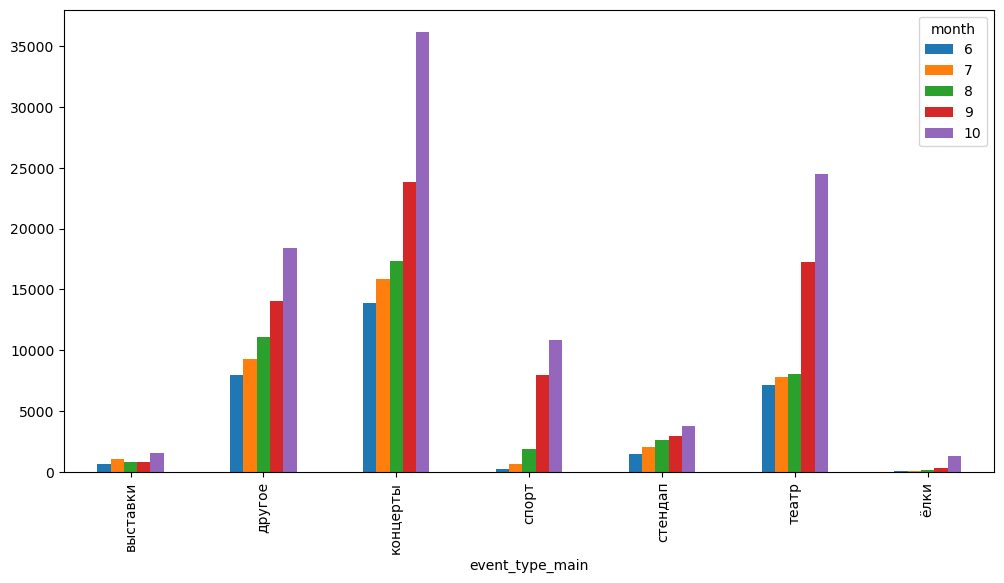

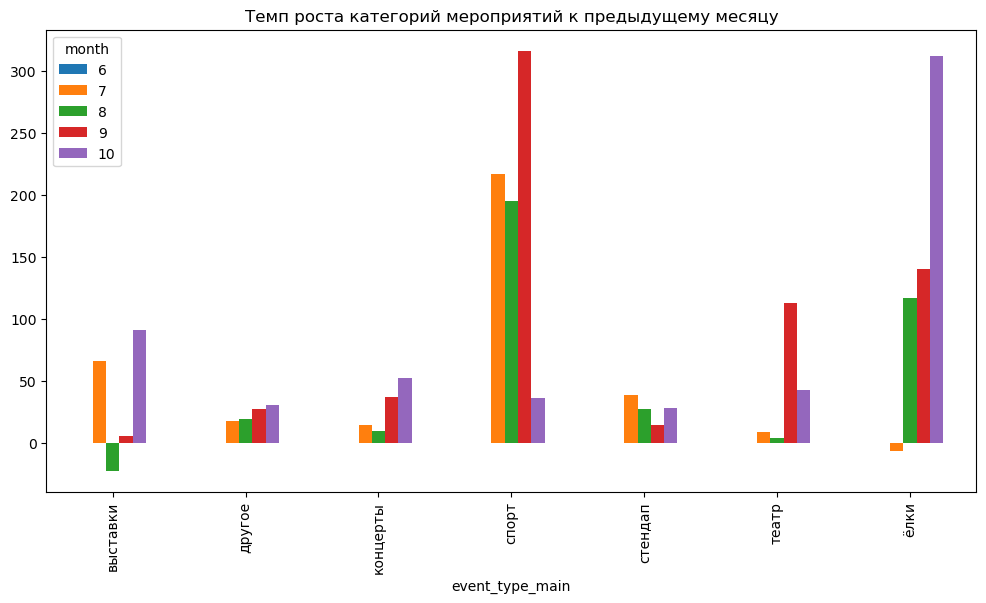

In [89]:
pivot_df = df_final.pivot_table(index='event_type_main', columns='month', values='order_id',  aggfunc='count', fill_value=0)
print('Изменение числа заказов по месяцам \n')
print(pivot_df)
print()
percentage_by_month = percentage_by_month = pivot_df.div(pivot_df.shift(1, axis=1))*100-100

print(pivot_df.plot(kind='bar', figsize=(12,6)))
print(percentage_by_month.plot(kind='bar', figsize=(12,6)))

plt.title('Темп роста категорий мероприятий к предыдущему месяцу')

percentage_by_month_rounded = percentage_by_month.round(2)
print('Изменение заказов в % по отношению к прошлому месяцу \n')
print(percentage_by_month_rounded)

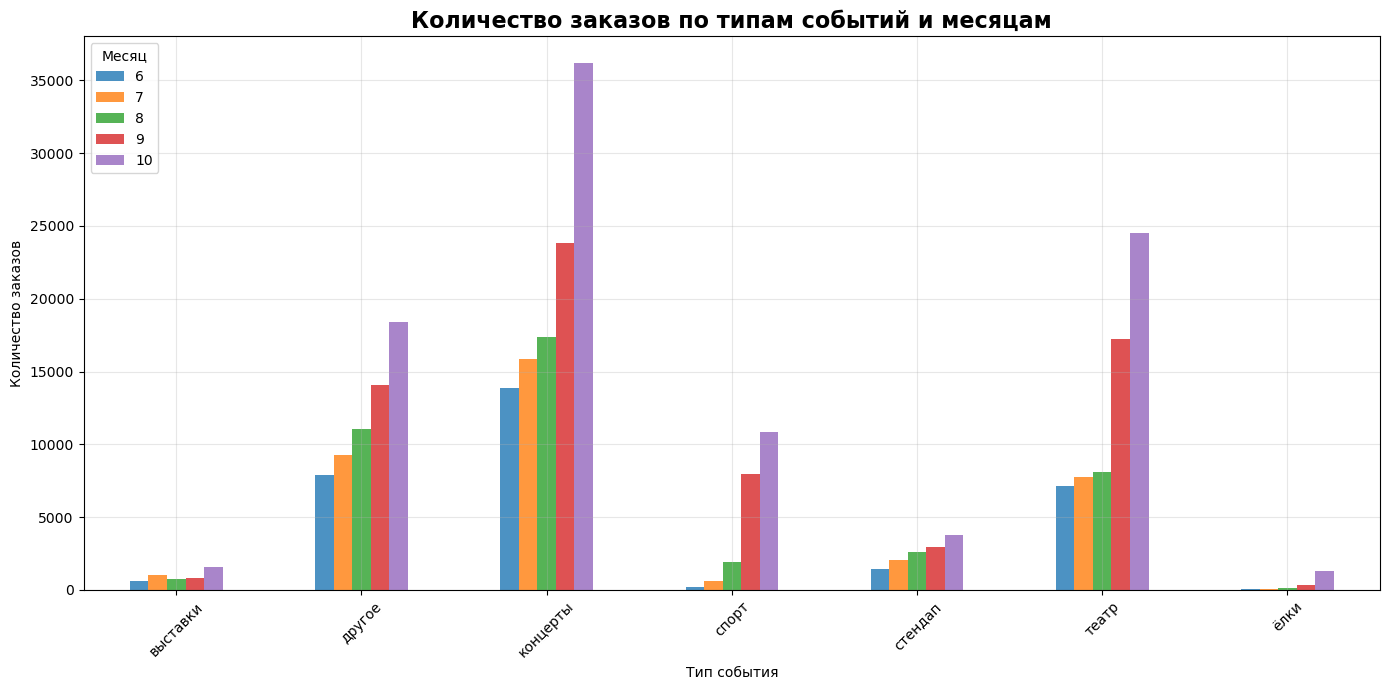

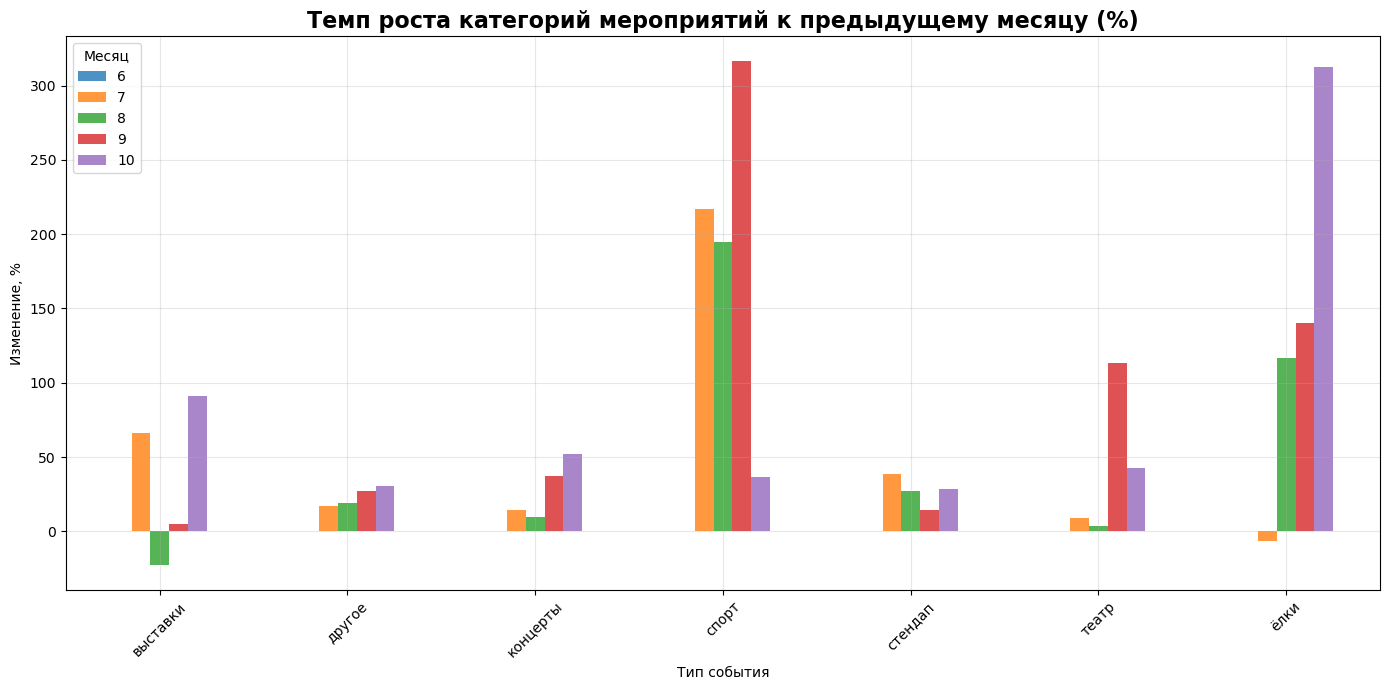

In [90]:
plt.figure(figsize=(14, 7))
pivot_df.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Количество заказов по типам событий и месяцам', fontsize=16, fontweight='bold')
plt.xlabel('Тип события')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
percentage_by_month.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Темп роста категорий мероприятий к предыдущему месяцу (%)', fontsize=16, fontweight='bold')
plt.xlabel('Тип события')
plt.ylabel('Изменение, %')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

Набольший рост показывает спорт стабильно, заисключением в октябре и елки в октябре, при этом с учтом общей популярности категорий фавориты концерты и театр

Елки явно подготовка к новому году праздники, редкое меропрятие в течении года с учтом его сезоности, слеждует изуить средний чек и возможно его стоит увеличить

стендап и выставки крайне не популярны, следует расмотреть возможность более дорогое меропритяи для поднятия прибыли


In [91]:
pivot_df = df_final.pivot_table(index='device_type_canonical', columns='month', values='order_id',  aggfunc='count', fill_value=0)
print('Изменение числа заказов по месяцам \n')
print(pivot_df)
print()
percentage_by_month = percentage_by_month = pivot_df.div(pivot_df.shift(1, axis=1))*100-100

percentage_by_month_rounded = percentage_by_month.round(2)
print('Изменение заказов в % по отношению к прошлому месяцу \n')
print(percentage_by_month_rounded)


Изменение числа заказов по месяцам 

month                     6      7      8      9      10
device_type_canonical                                   
desktop                 6071   6952   7739  12988  20262
mobile                 25194  29727  34169  54185  76324

Изменение заказов в % по отношению к прошлому месяцу 

month                  6      7      8      9      10
device_type_canonical                                
desktop               NaN  14.51  11.32  67.83  56.01
mobile                NaN  17.99  14.94  58.58  40.86


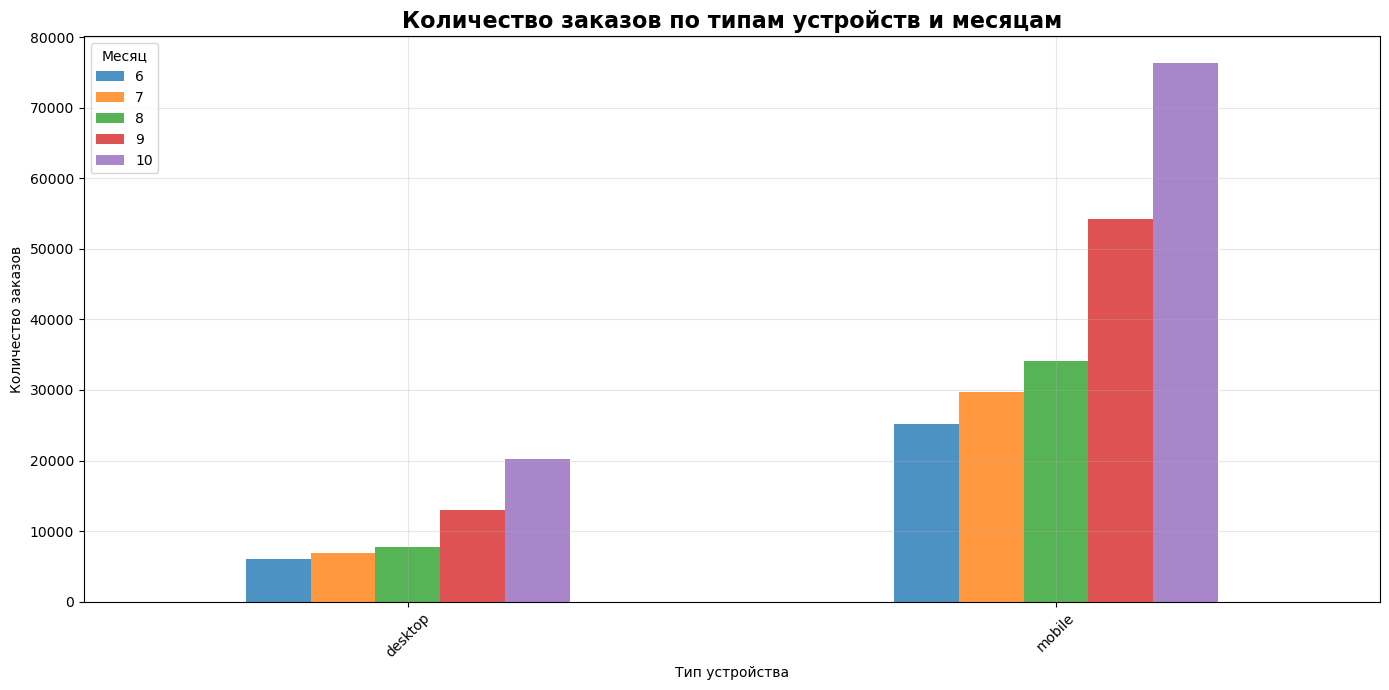

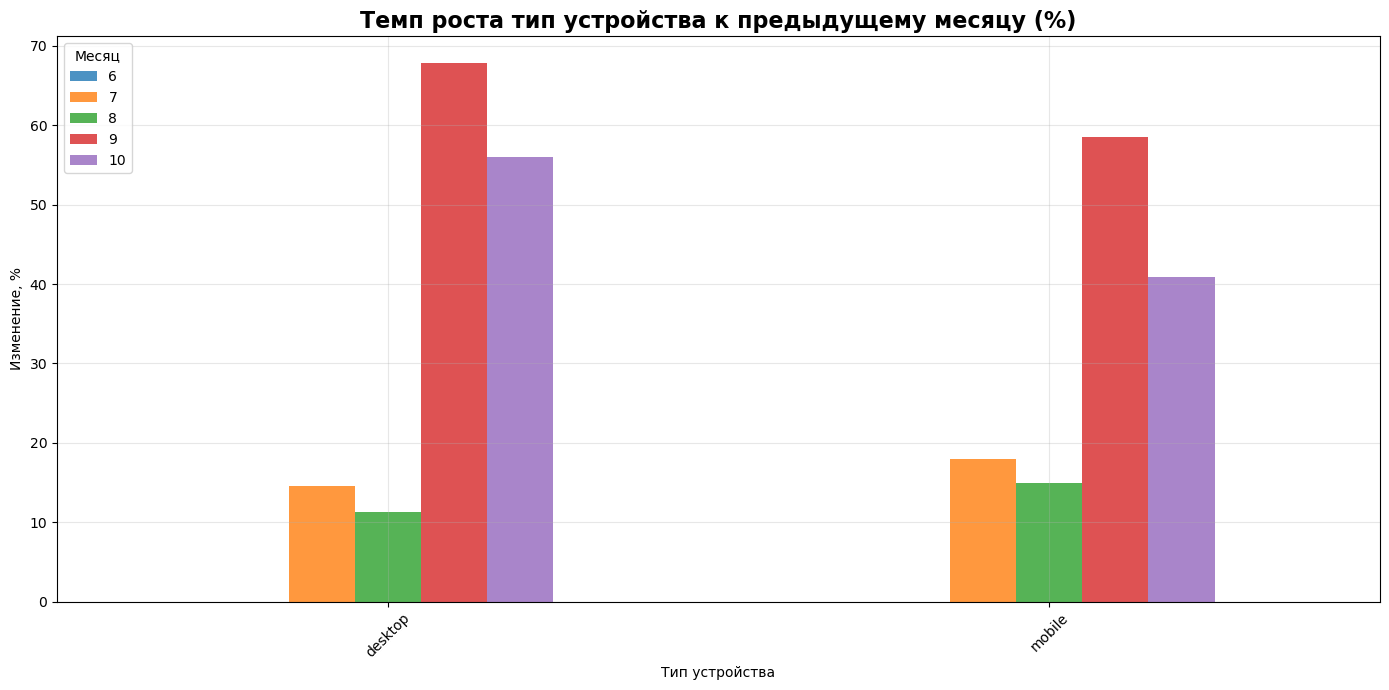

In [92]:
plt.figure(figsize=(14, 7))
pivot_df.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Количество заказов по типам устройств и месяцам', fontsize=16, fontweight='bold')
plt.xlabel('Тип устройства')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
percentage_by_month.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Темп роста тип устройства к предыдущему месяцу (%)', fontsize=16, fontweight='bold')
plt.xlabel('Тип устройства')
plt.ylabel('Изменение, %')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

Стабильный рост по всем типам устройств.
Больше всего заказов с мобильных устройств, но по отношению к предыдущему месяцу незанчительная разница


Изменение числа заказов по месяцам 

month        6      7      8      9      10
age_limit                                  
0          5409   6197   8847  15488  23620
6          5627   7161   7419  12347  16330
12         6976   7232   8199  15231  20700
16         9160  10908  11548  17223  25858
18         4093   5181   5895   6884  10078

Изменение заказов в % по отношению к прошлому месяцу 

month      6      7      8      9      10
age_limit                                
0         NaN  14.57  42.76  75.06  52.51
6         NaN  27.26   3.60  66.42  32.26
12        NaN   3.67  13.37  85.77  35.91
16        NaN  19.08   5.87  49.14  50.14
18        NaN  26.58  13.78  16.78  46.40


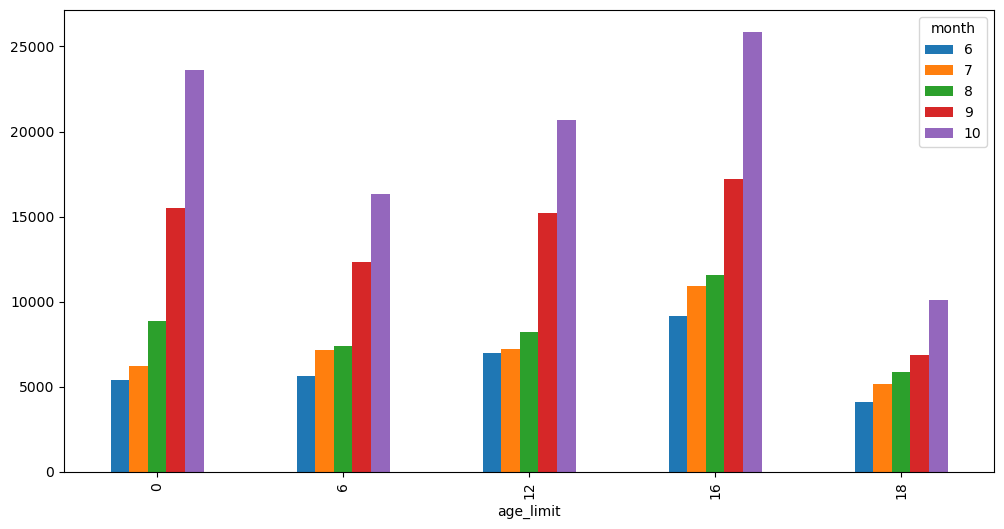

In [93]:
pivot_df = df_final.pivot_table(index='age_limit', columns='month', values='order_id',  aggfunc='count', fill_value=0)
pivot_df.plot(kind='bar', figsize=(12,6))

print('Изменение числа заказов по месяцам \n')
print(pivot_df)
print()
percentage_by_month = percentage_by_month = pivot_df.div(pivot_df.shift(1, axis=1))*100-100

percentage_by_month_rounded = percentage_by_month.round(2)
print('Изменение заказов в % по отношению к прошлому месяцу \n')
print(percentage_by_month_rounded)

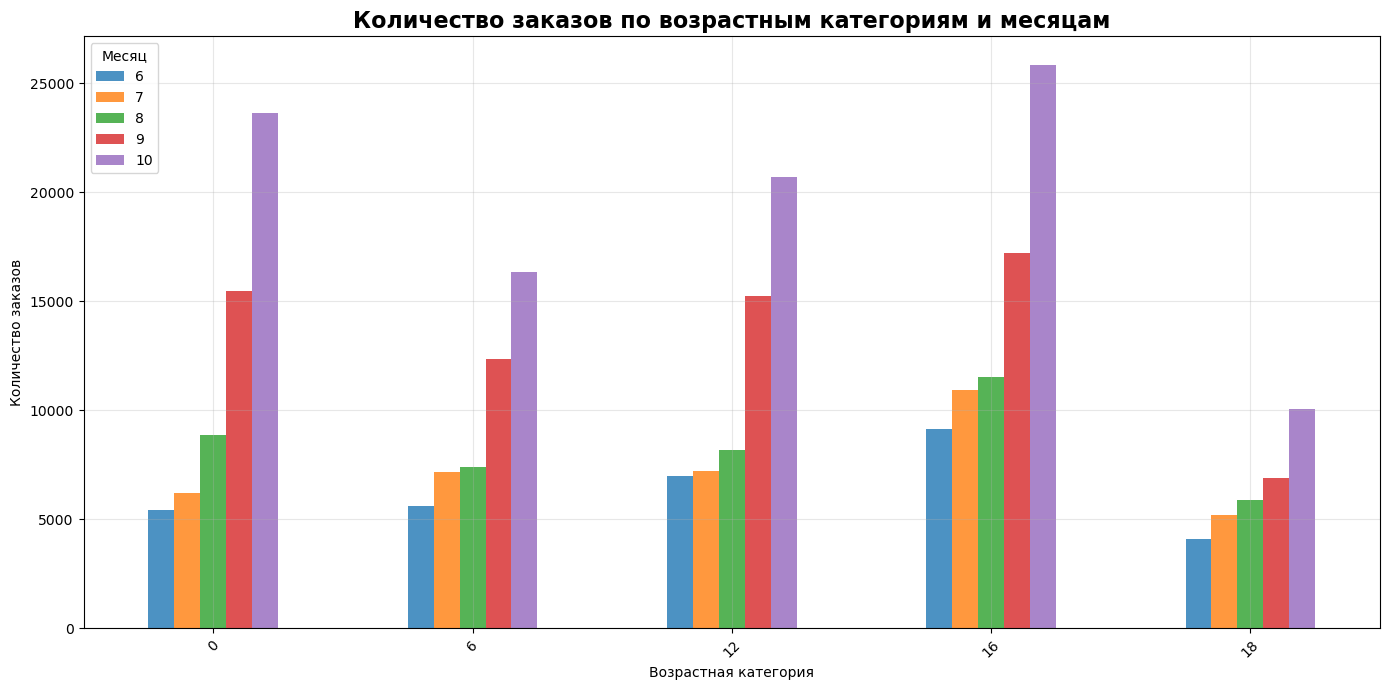

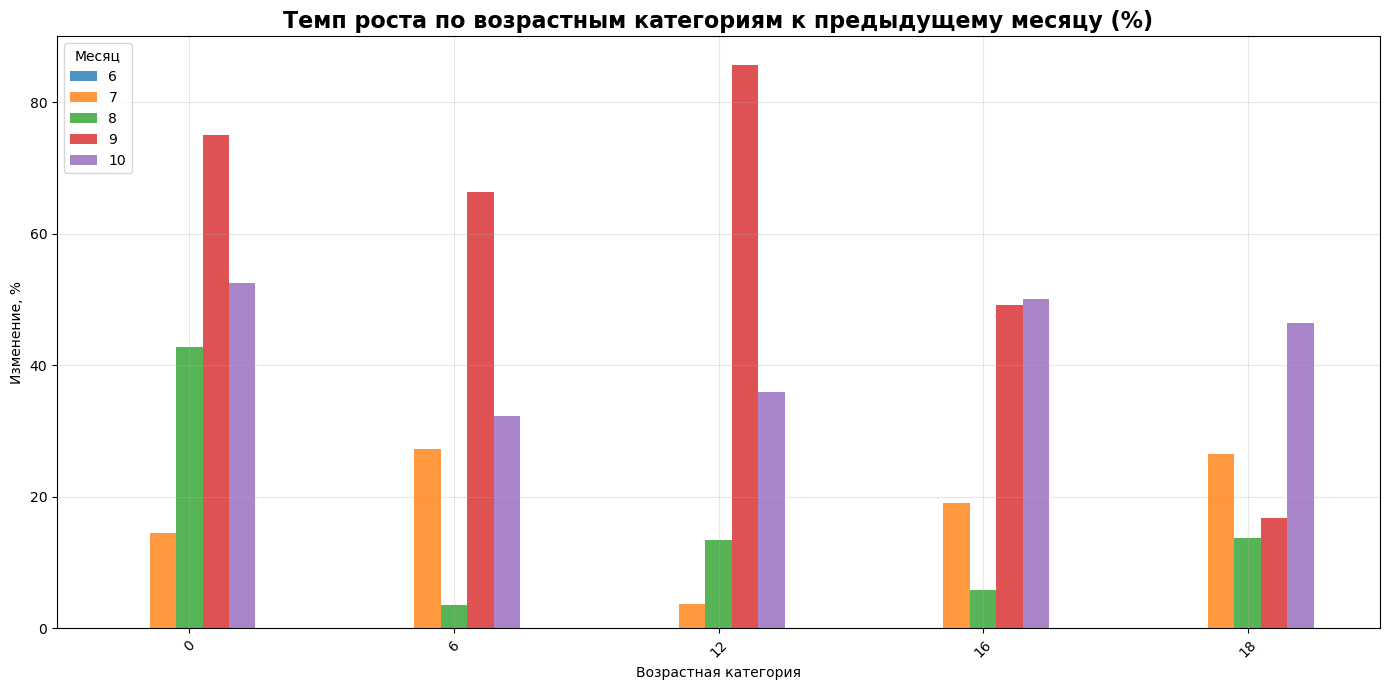

In [94]:
plt.figure(figsize=(14, 7))
pivot_df.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Количество заказов по возрастным категориям и месяцам', fontsize=16, fontweight='bold')
plt.xlabel('Возрастная категория')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
percentage_by_month.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Темп роста по возрастным категориям к предыдущему месяцу (%)', fontsize=16, fontweight='bold')
plt.xlabel('Возрастная категория')
plt.ylabel('Изменение, %')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

Наименее востребованная для взрослых категория наиболее востребованая для 16+ - в июне максимум 8,7 тыс заказов, октябрь максимум 26 тыс. остальные незначательно отличаются дру от друга 

при этом при этом в июле у всех рост а в августе рост тока +0 и +12 16+ и 18+ почти неменятся у +6 незначительный спад  в сентябре и рост значитеьный у всех кроме + 18 в октябре у всех категорий значительный рост
при сутствует сезоность вероятно сказываются отпуска летние 

#### Сезоный анализ

In [95]:
df_final.columns

Index(['order_id', 'user_id', 'data', 'created_ts_msk', 'event_id',
       'cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical',
       'revenue', 'service_name', 'tickets_count', 'total', 'days_since_prev',
       'event_name', 'event_type_description', 'event_type_main', 'organizers',
       'region_name', 'city_name', 'city_id', 'venue_id', 'venue_name',
       'venue_address', 'curs', 'sum_rub', 'revenue_rub',
       'one_ticket_revenue_rub', 'month', 'season'],
      dtype='object')

In [96]:
pivot_df = df_final.pivot_table(index='event_type_main', columns='season', values='order_id',  aggfunc='count', fill_value=0)
print('Изменение числа заказов по сезонам \n')
print(pivot_df)
print()
percentage_by_month = percentage_by_month = pivot_df.div(pivot_df.shift(1, axis=1))*100-100

percentage_by_month_rounded = percentage_by_month.round(2)
print('Изменение заказов в % по отношению к прошлому сезону \n')
print(percentage_by_month_rounded)

Изменение числа заказов по сезонам 

season            лето  осень
event_type_main              
выставки          2406   2399
другое           28273  32493
концерты         47086  60039
спорт             2760  18770
стендап           6075   6738
театр            22998  41722
ёлки               254   1598

Изменение заказов в % по отношению к прошлому сезону 

season           лето   осень
event_type_main              
выставки          NaN   -0.29
другое            NaN   14.93
концерты          NaN   27.51
спорт             NaN  580.07
стендап           NaN   10.91
театр             NaN   81.42
ёлки              NaN  529.13


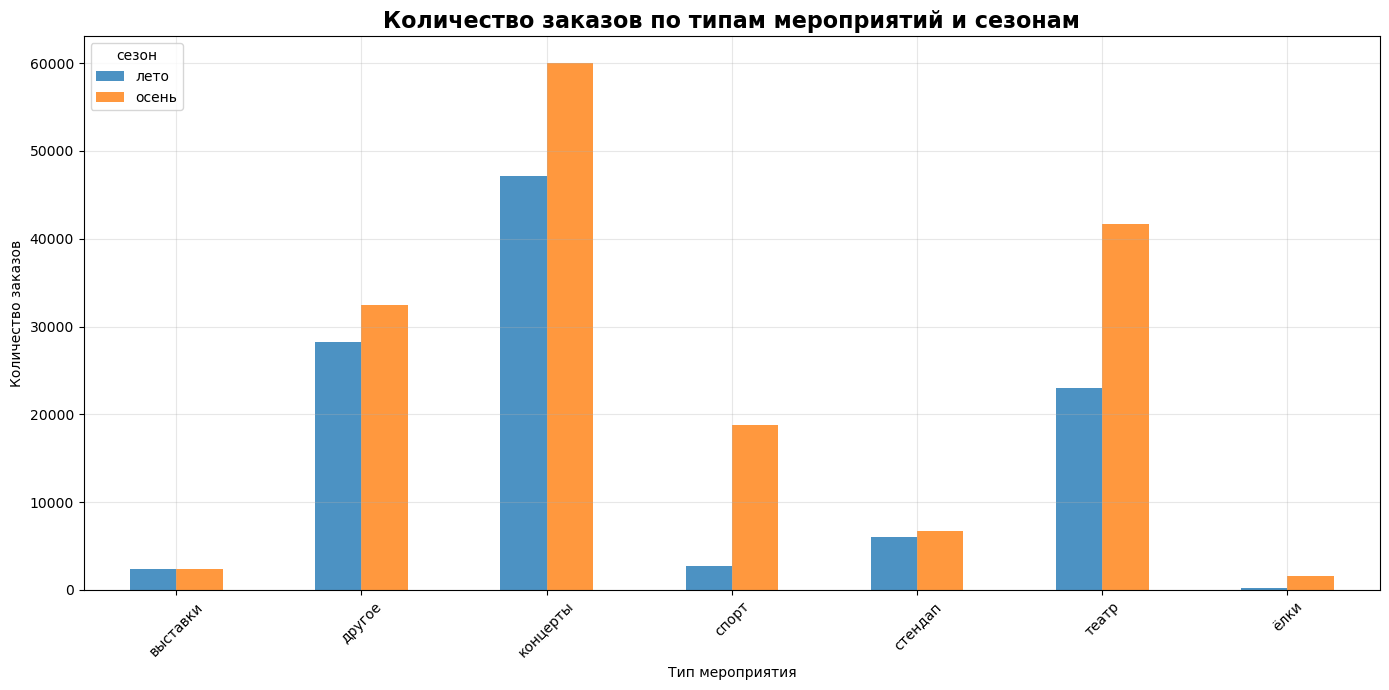

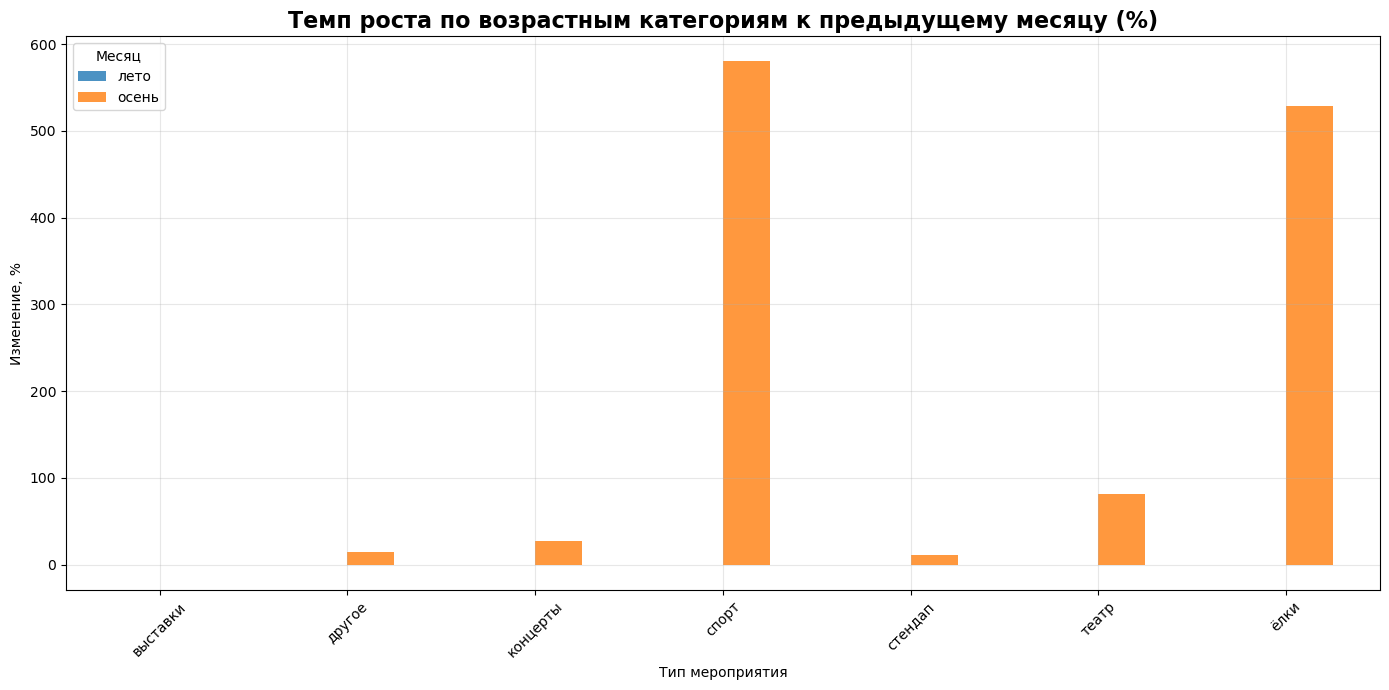

In [97]:
plt.figure(figsize=(14, 7))
pivot_df.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Количество заказов по типам мероприятий и сезонам', fontsize=16, fontweight='bold')
plt.xlabel('Тип мероприятия')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.legend(title='сезон', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
percentage_by_month.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Темп роста по возрастным категориям к предыдущему месяцу (%)', fontsize=16, fontweight='bold')
plt.xlabel('Тип мероприятия')
plt.ylabel('Изменение, %')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

Из 7 типов мероприйтий только Концерты, театр, спорт и елки выросли осенью по сравнению с летом
Концерты на 30%
театр на 79%
спорт на 527%
елки 533%
осатльгные незначительно выросли

Axes(0.125,0.11;0.775x0.77)
Изменение числа заказов по сезонам 

season                  лето   осень
device_type_canonical               
desktop                20762   33250
mobile                 89090  130509

Изменение заказов в % по отношению к прошлому сезону 

season                 лето  осень
device_type_canonical             
desktop                 NaN  60.15
mobile                  NaN  46.49


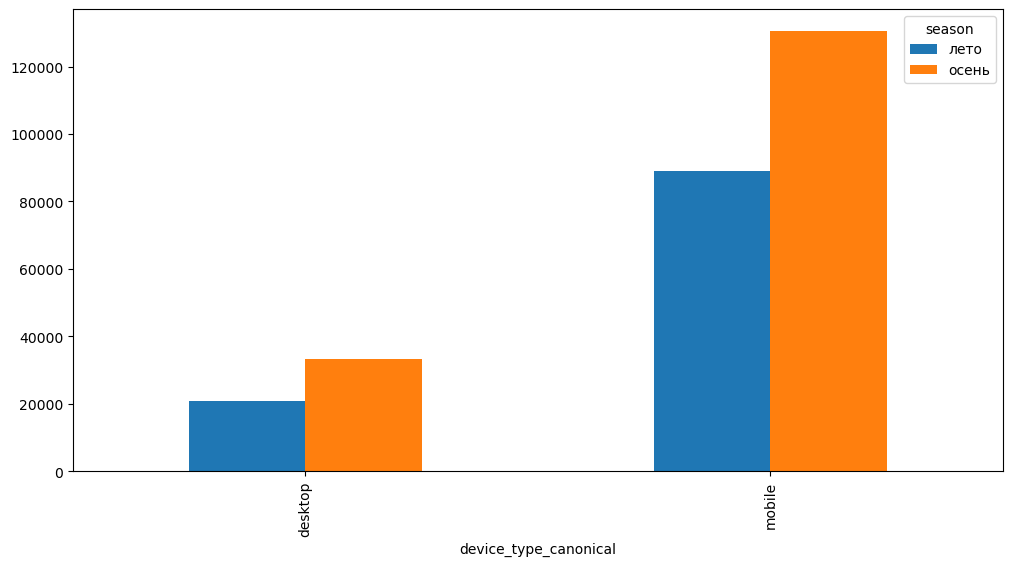

In [98]:
pivot_df = df_final.pivot_table(index='device_type_canonical', columns='season', values='order_id',  aggfunc='count', fill_value=0)
print(pivot_df.plot(kind='bar', figsize=(12,6)))
print('Изменение числа заказов по сезонам \n')
print(pivot_df)
print()
percentage_by_month = percentage_by_month = pivot_df.div(pivot_df.shift(1, axis=1))*100-100

percentage_by_month_rounded = percentage_by_month.round(2)
print('Изменение заказов в % по отношению к прошлому сезону \n')
print(percentage_by_month_rounded)

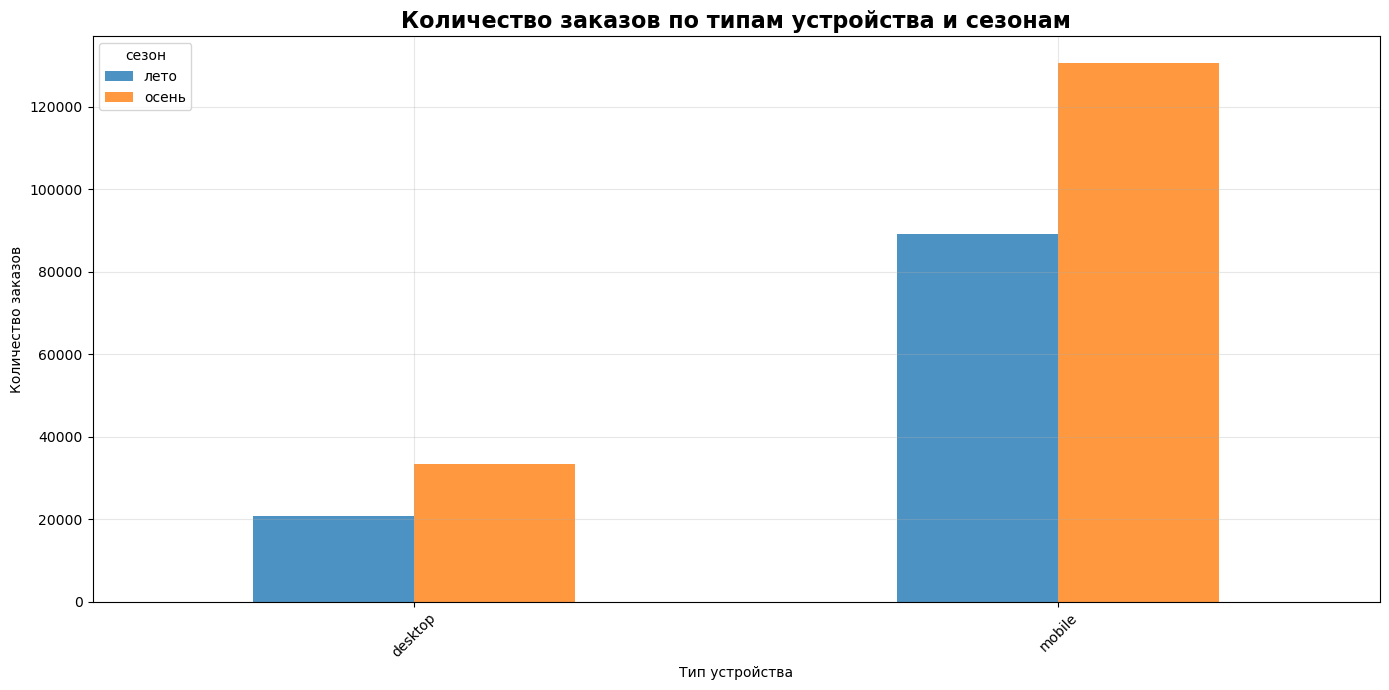

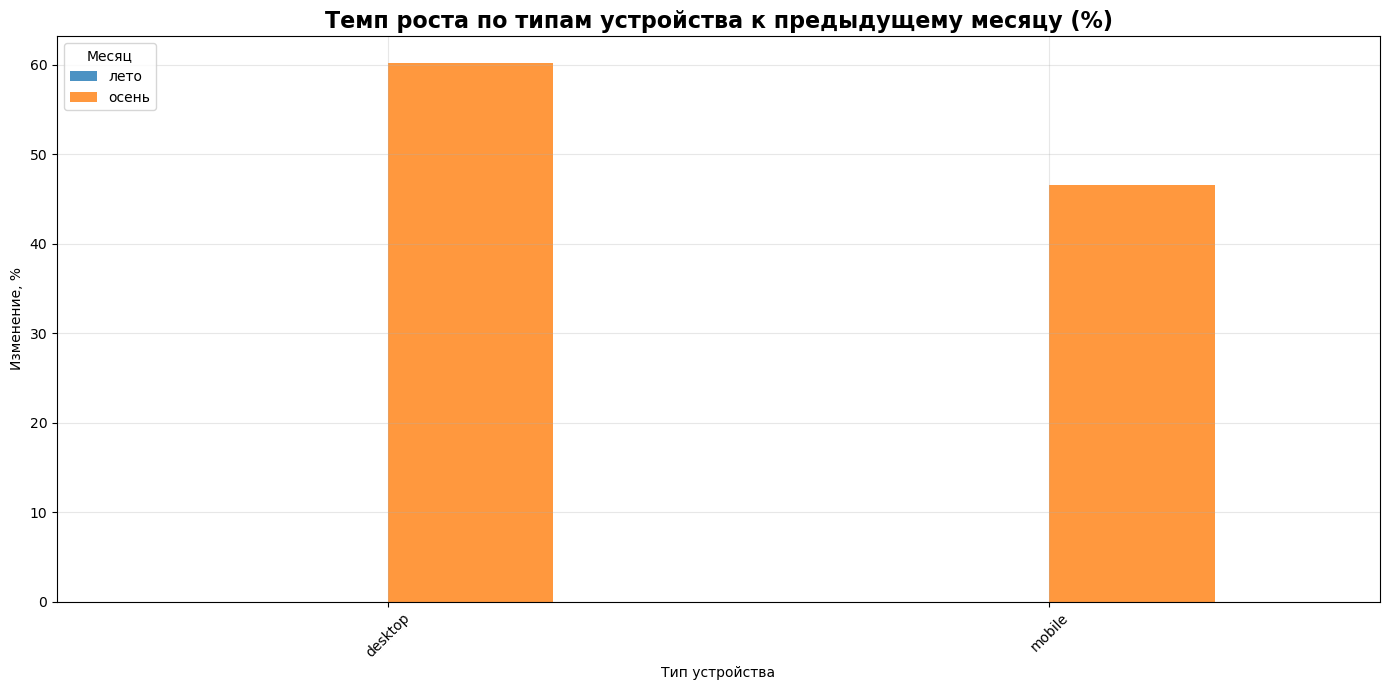

In [99]:
plt.figure(figsize=(14, 7))
pivot_df.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Количество заказов по типам устройства и сезонам', fontsize=16, fontweight='bold')
plt.xlabel('Тип устройства')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.legend(title='сезон', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 7))
percentage_by_month.plot(
    kind='bar',
    ax=plt.gca(),
    alpha=0.8
)
plt.title('Темп роста по типам устройства к предыдущему месяцу (%)', fontsize=16, fontweight='bold')
plt.xlabel('Тип устройства')
plt.ylabel('Изменение, %')
plt.xticks(rotation=45)
plt.legend(title='Месяц', loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() 

Десктопные устройства растут быстрее чем мобильные, так же возможно одни пользователи используют оба типа

Основной канал заказов мобильные устройства, при этом десктопные так же имееют значительный вес, при этом темпы роста по декстпным выше чем моибльным, что может говорить о пределе для мобильных устройств и потенциале для декстопных устройств

Следуте развивать дестопные ПО, но не забывать про мобильное для поддержанеие техничесокй стабильности
так же рост дектопных возможено что с мобильных люди делали с отдыха, а осенью во время работы с декстопных устройств работают

#### Анализ изменения выручки с продажи одного билета

In [100]:

stats = df_final.groupby(['event_type_main', 'season']).agg(
    total_revenue=('revenue', 'sum'),
    total_tickets=('tickets_count', 'sum')
).reset_index()

stats['avg_ticket_price'] = stats['total_revenue'] / stats['total_tickets']
pivot_avg_price = stats.pivot_table(
    index='event_type_main',
    columns='season',
    values='avg_ticket_price'
)

print("\nСводная таблица средней цены билета:")
print(pivot_avg_price.round(2))

if 'лето' in pivot_avg_price.columns and 'осень' in pivot_avg_price.columns:
    pivot_avg_price['change_pct'] = ((pivot_avg_price['осень'] - pivot_avg_price['лето']) / pivot_avg_price['лето'] * 100).round(2)
    print("\nИзменение цены билета осенью относительно лета (%):")
    print(pivot_avg_price['change_pct'])


Сводная таблица средней цены билета:
season             лето   осень
event_type_main                
выставки          89.01   92.62
другое            93.38   84.33
концерты         350.83  259.67
спорт             58.85   53.54
стендап          196.84  219.08
театр            200.31  164.36
ёлки             243.76  197.56

Изменение цены билета осенью относительно лета (%):
event_type_main
выставки     4.05
другое      -9.69
концерты   -25.98
спорт       -9.02
стендап     11.30
театр      -17.95
ёлки       -18.95
Name: change_pct, dtype: float64


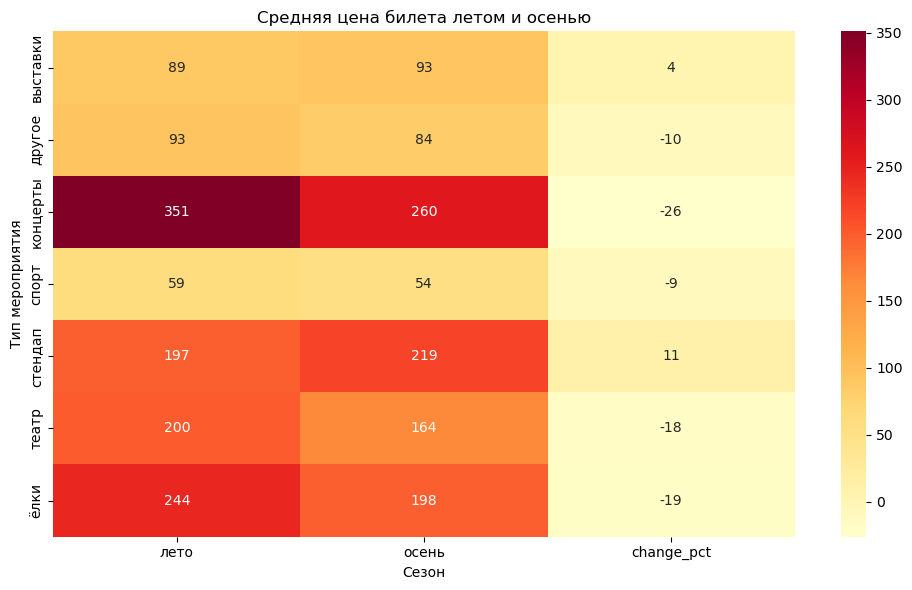

In [101]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_avg_price,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd'
)

plt.title('Средняя цена билета летом и осенью')
plt.xlabel('Сезон')
plt.ylabel('Тип мероприятия')
plt.tight_layout()
plt.show()

Только две категории увеличили среднию ценну билета Выставки на 4% и стендап на 11%.
Все остальные категории упали от 9% спорт до 26% концерты При том разница значительная

Ранне было установлено что концерты самые массовые, норст незначительный
Спорт не самы й востребованный но резкий рост осенью начался как и у елок, как будто ценна должна расти с ростом спроса , возможно дело в том что рост предложения так де вырос и неполная заполнеость мероприятий и вынуждает сбавлять ценну.


Рост так же преобладате в низкой ценновой категории более высокая не изменилась

В среднем выручка с одного билета по типам категоирй мероприятий в основном снижается
Рост был у стендапа на 8 руб, выставки 4
Спад у Концертов 8, театр 18 и елки 17

Вероятно связано с тем что летом у людей болшьше сводного арени поэтому и чаще должны выбиратся соответосвено на более высокйи спрос и вше ценна, а осенью все на работу и цчебуц идут ниже делжен быть спрос вот и снижение идет 

### Вывод

Распределение выручки имеет ярко выраженную правостороннюю асимметрию, что говорит о преобладании мероприятий в низкой ценовой категории.
Осенью наблюдается рост общего числа заказов по сравнению с летом, однако средний чек снижается. Это связано с увеличением доли покупок в низком ценовом сегменте.
Темпы роста заказов по типам устройств (мобильные и десктопные) ведут себя синхронно, значимой разницы в динамике между ними нет.

Анализ категорий мероприятий:
- Лидеры по объему: Концерты и театр остаются самыми массовыми и популярными категориями.

* Лидеры по росту: Осенью по сравнению с летом наибольший прирост показали Спорт (+527%) и Новогодние ёлки (+533%). Концерты выросли на 30%, театр — на 79%. Остальные категории показали незначительный рост.

* Динамика цен: Несмотря на рост спроса, средняя цена билета в большинстве категорий упала (концерты -26%, спорт -9%). Исключение составили выставки (+4%) и стендап (+11%).

Гипотеза: Резкий рост предложения в категориях «спорт» и «ёлки» привел к неполной заполняемости площадок, что вынудило организаторов снижать цены.

* Аутсайдеры: Стендап и выставки крайне непопулярны. Категория «ёлки» имеет ярко выраженную сезонность (подготовка к Новому году) и является редким явлением в течение года.
Возрастные ограничения

Наиболее востребованной возрастной категория 16+ и +0. Остальные возрастные категории отличаются незначительно, наименьшеая +18.

Наблюдается сезонность: в июле рост у всех категорий, в августе стагнация (вероятно, из-за летних отпусков), в сентябре незначительный спад у +6, а в октябре — значительный рост у всех, кроме +18.


## Осенняя активность пользователей
### Анализ дневной динамики

In [102]:
df_final.columns

Index(['order_id', 'user_id', 'data', 'created_ts_msk', 'event_id',
       'cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical',
       'revenue', 'service_name', 'tickets_count', 'total', 'days_since_prev',
       'event_name', 'event_type_description', 'event_type_main', 'organizers',
       'region_name', 'city_name', 'city_id', 'venue_id', 'venue_name',
       'venue_address', 'curs', 'sum_rub', 'revenue_rub',
       'one_ticket_revenue_rub', 'month', 'season'],
      dtype='object')

In [103]:
pivot_atumun = autumn.pivot_table(index='event_type_main', columns='data', values='one_ticket_revenue_rub',  aggfunc='mean', fill_value=0)


In [104]:
daily_metrics = autumn.groupby('data').agg(
    total_orders=('order_id', 'count'),
    active_users=('user_id', 'nunique'),
).reset_index()

daily_metrics['avg_order_per_user'] = round(daily_metrics['total_orders'] / daily_metrics['active_users'],2 )
daily_metrics['avg_ticket'] = autumn.groupby('data')['one_ticket_revenue_rub'].mean().round(2).values
daily_metrics['data'] = daily_metrics['data'].dt.strftime('%m-%d')

In [105]:
daily_metrics

,data,total_orders,active_users,avg_order_per_user,avg_ticket
0,09-01,1267,541,2.34,188.80
1,09-02,1337,562,2.38,182.58
2,09-03,5054,767,6.59,77.63
3,09-04,1711,670,2.55,170.72
4,09-05,1875,722,2.60,177.38
...,...,...,...,...,...
56,10-27,2770,1015,2.73,179.32
57,10-28,2781,981,2.83,163.64
58,10-29,2752,980,2.81,163.55
59,10-30,2851,1029,2.77,173.23


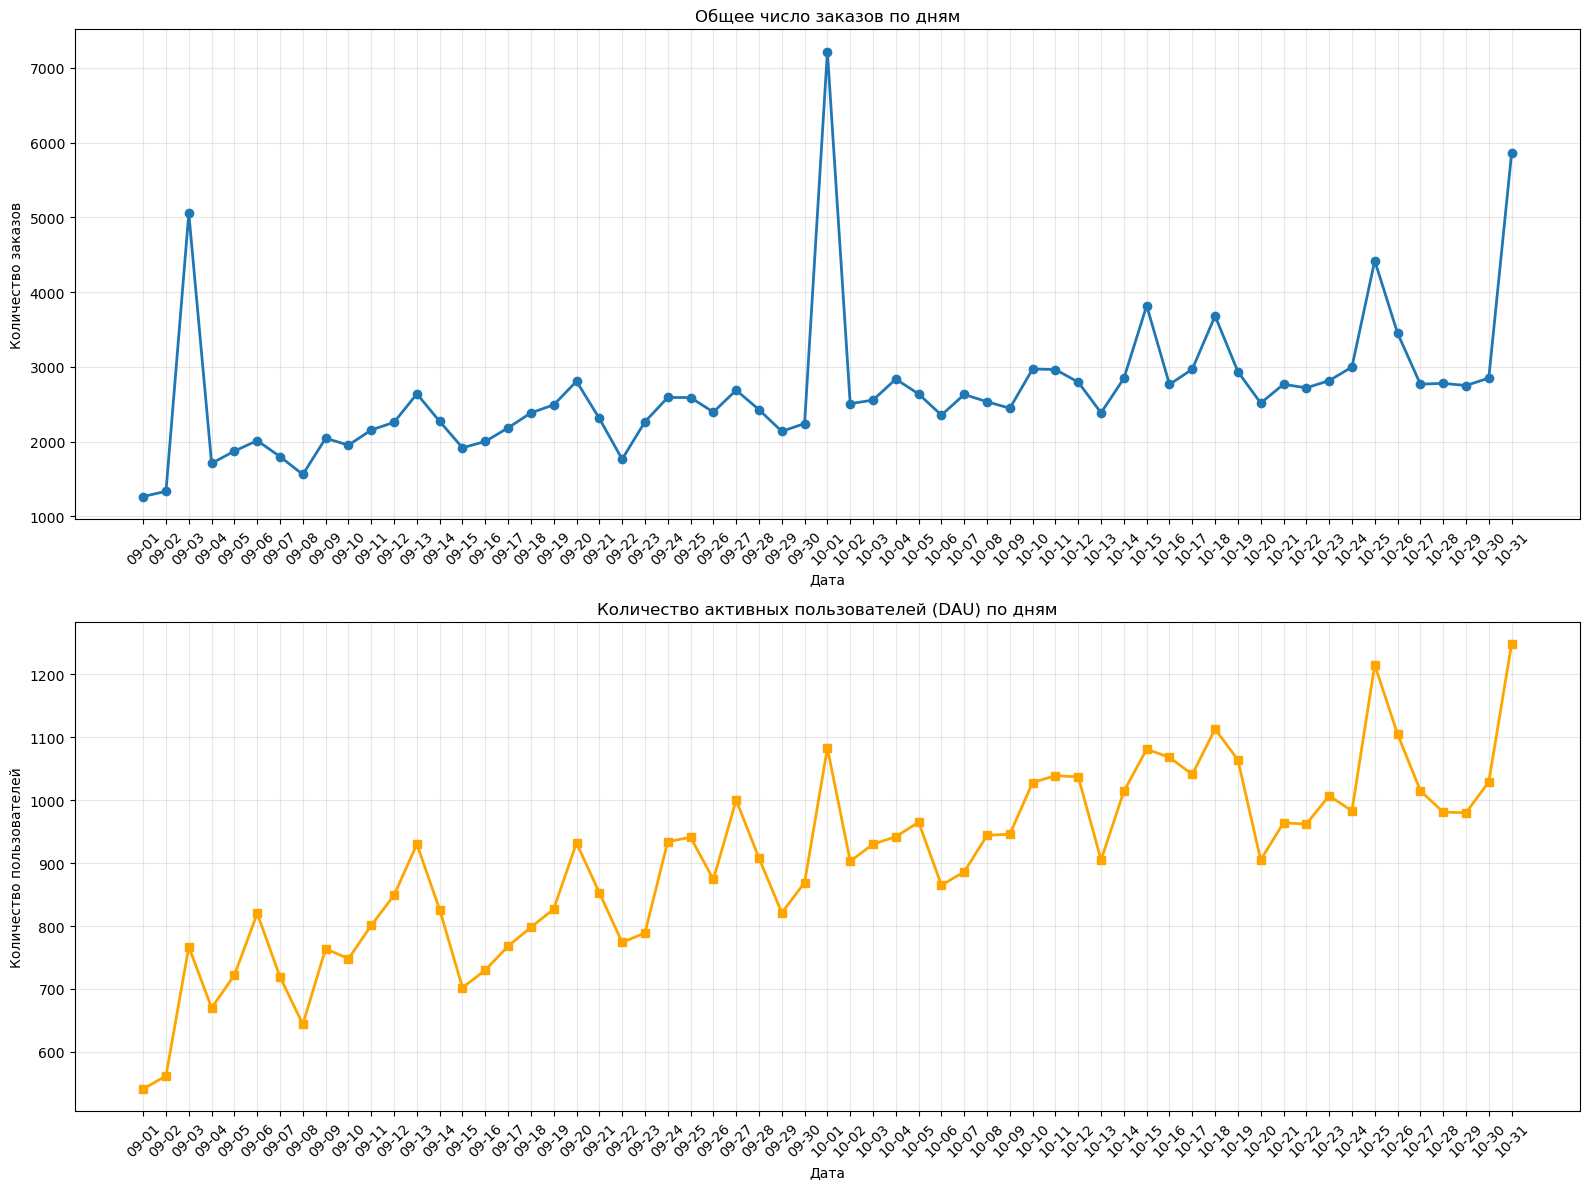

In [106]:
plt.figure(figsize=(16, 12))

# Общее число заказов
plt.subplot(2, 1, 1)
plt.plot(daily_metrics['data'], daily_metrics['total_orders'], marker='o', linewidth=2)
plt.title('Общее число заказов по дням')
plt.xlabel('Дата')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)


# Количество активных пользователей (DAU)
plt.subplot(2, 1, 2)
plt.plot(daily_metrics['data'], daily_metrics['active_users'], marker='s', color='orange', linewidth=2)
plt.title('Количество активных пользователей (DAU) по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Много локальных пиков по числу заказов приходится на пятницу, а локльные минимумы на воскресенье
Основыне пики приходятся на начало / конец месяц 9.1, 10.1, 10.31

Активные пользователи в целом повторяте графки число заказов

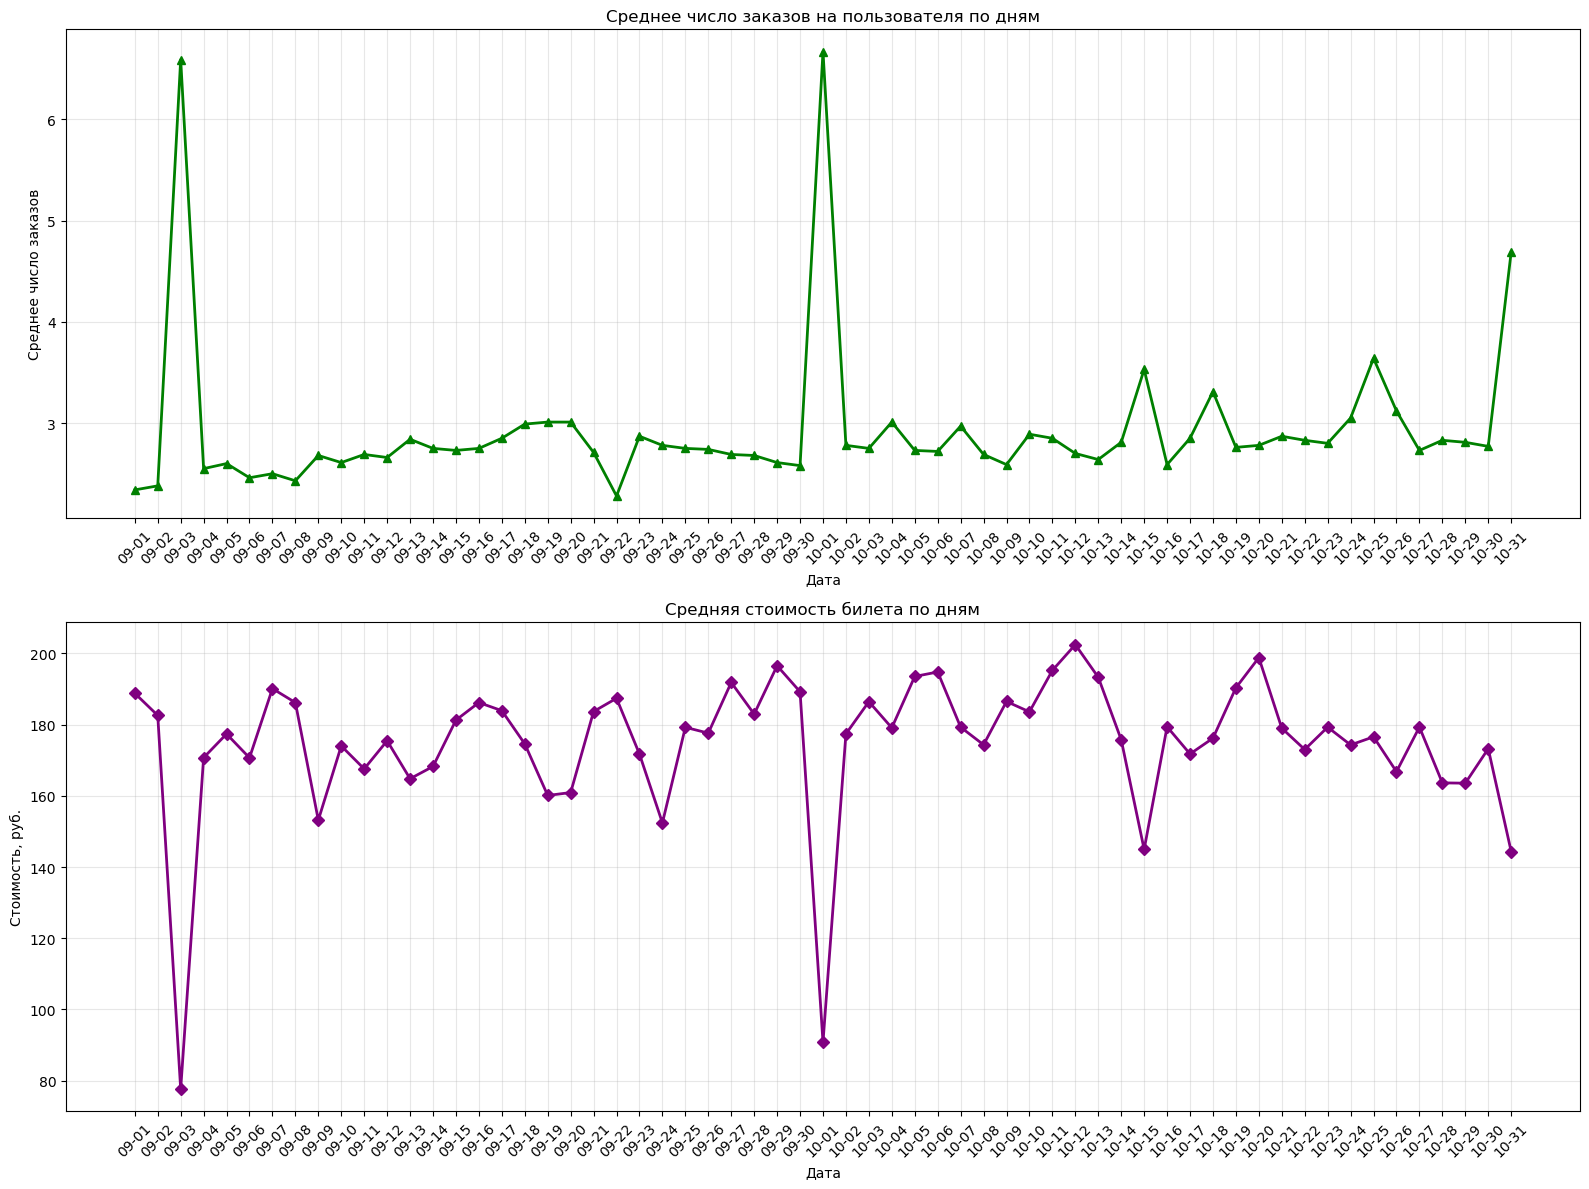

In [107]:
plt.figure(figsize=(16, 12))

# Среднее число заказов на пользователя
plt.subplot(2, 1, 1)
plt.plot(daily_metrics['data'], daily_metrics['avg_order_per_user'], marker='^', color='green', linewidth=2)
plt.title('Среднее число заказов на пользователя по дням')
plt.xlabel('Дата')
plt.ylabel('Среднее число заказов')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# Средняя стоимость билета
plt.subplot(2, 1, 2)
plt.plot(daily_metrics['data'], daily_metrics['avg_ticket'], marker='D', color='purple', linewidth=2)
plt.title('Средняя стоимость билета по дням')
plt.xlabel('Дата')
plt.ylabel('Стоимость, руб.')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Средня стоиомтсь по дням обратный график числу заказов, судя по всему это дни акций / скидок так минимум основные приходятся на начало / конец месяца

### Анализ недельной динамики

In [108]:
# недельная цикличность 

daily_metrics['day_of_week'] = df_final['data'].dt.dayofweek

days_map = {0: 'Понедельник', 1: 'Вторник', 2: 'Среда',
           3: 'Четверг', 4: 'Пятница', 5: 'Суббота', 6: 'Воскресенье'}
daily_metrics['weekday_name'] = daily_metrics['day_of_week'].map(days_map)


# Определяем тип дня: будни или выходные
daily_metrics['day_type'] = daily_metrics['day_of_week'].apply(lambda x: 'Выходной' if x >= 5 else 'Будний') 

In [109]:
# Группируем по дням недели и считаем средние показатели
weekly_activity = daily_metrics.groupby(['day_of_week', 'weekday_name', 'day_type']).agg({
    'total_orders': 'mean',
    'active_users': 'mean',
    'avg_order_per_user': 'mean',
    'avg_ticket': 'mean'
}).round(2).reset_index()

print("Активность по дням недели:")
print(weekly_activity) 

Активность по дням недели:
   day_of_week weekday_name  day_type  total_orders  active_users  \
0          0.0  Понедельник    Будний       2485.67        889.33   
1          1.0      Вторник    Будний       2669.88        805.88   
2          2.0        Среда    Будний       2667.60        972.70   
3          3.0      Четверг    Будний       2188.30        807.30   
4          4.0      Пятница    Будний       2418.11        857.44   
5          5.0      Суббота  Выходной       2888.70        984.60   
6          6.0  Воскресенье  Выходной       3314.30        971.20   

   avg_order_per_user  avg_ticket  
0                2.80      179.95  
1                3.12      165.25  
2                2.74      182.73  
3                2.71      178.35  
4                2.81      177.89  
5                2.90      173.90  
6                3.41      166.21  


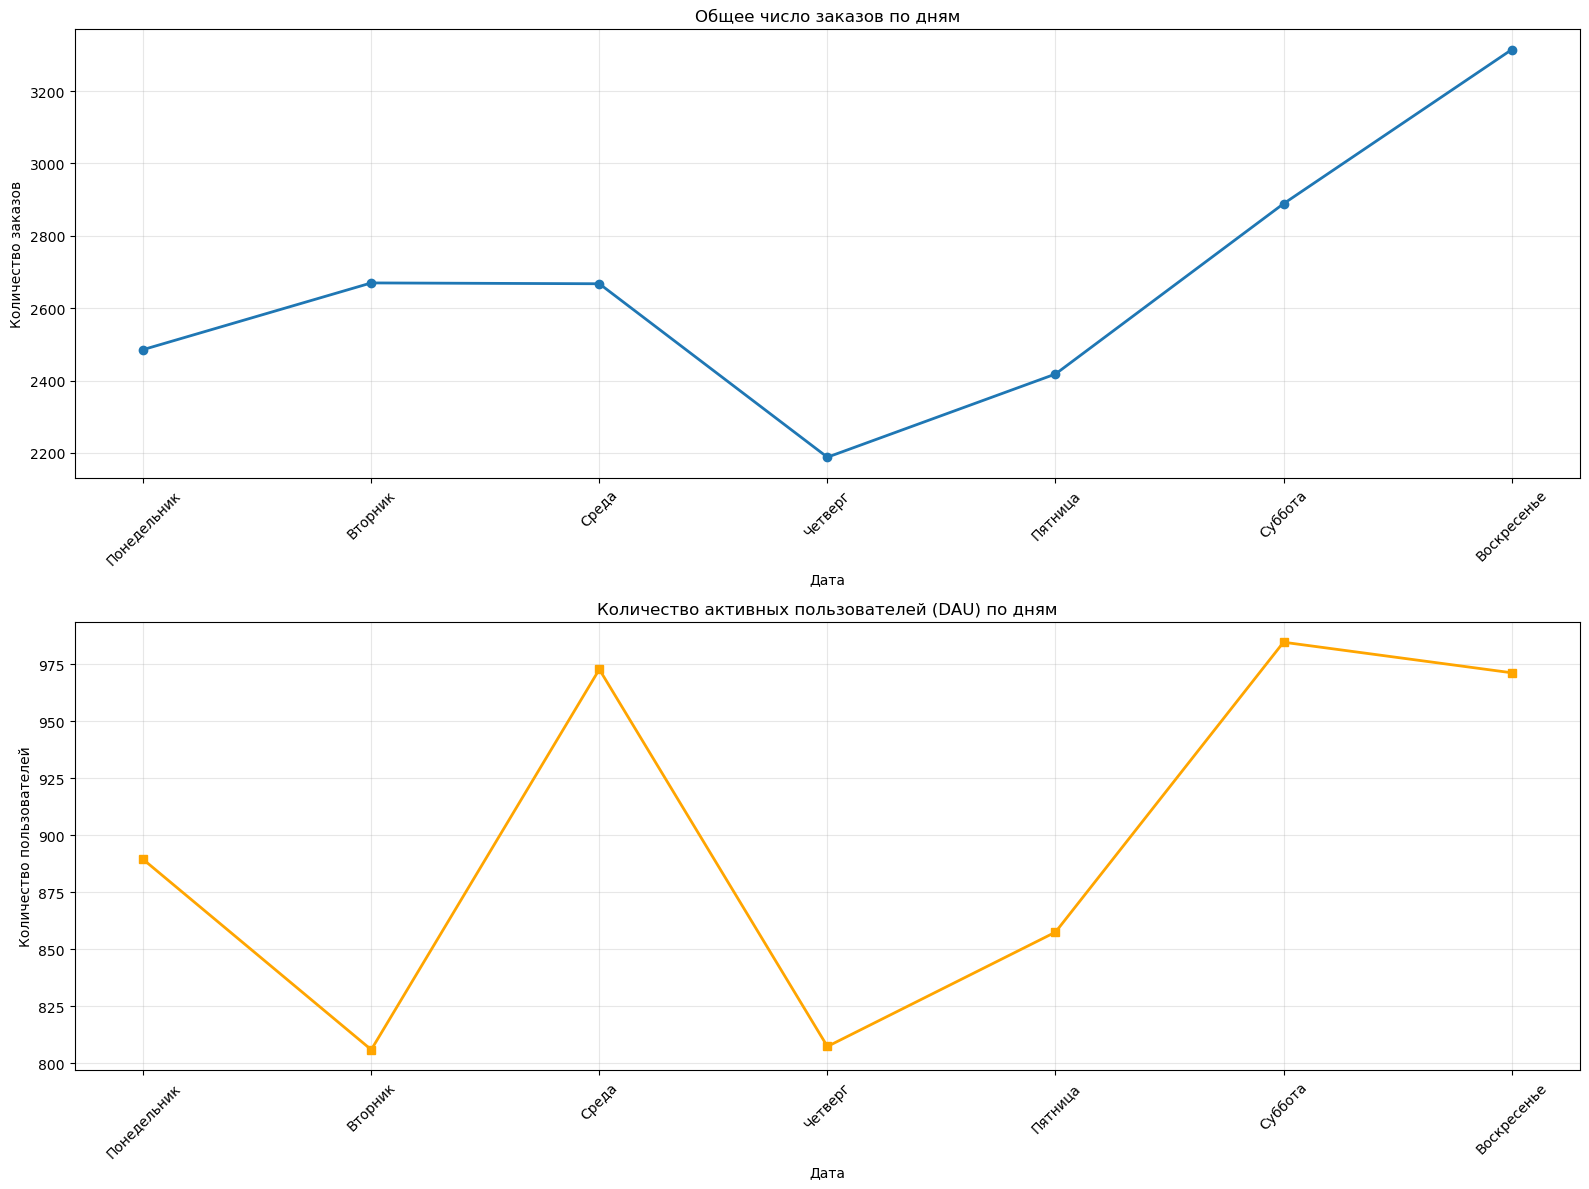

In [110]:
plt.figure(figsize=(16, 12))

# Общее число заказов
plt.subplot(2, 1, 1)
plt.plot(weekly_activity['weekday_name'], weekly_activity['total_orders'], marker='o', linewidth=2)
plt.title('Общее число заказов по дням')
plt.xlabel('Дата')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)


# Количество активных пользователей (DAU)
plt.subplot(2, 1, 2)
plt.plot(weekly_activity['weekday_name'], weekly_activity['active_users'], marker='s', color='orange', linewidth=2)
plt.title('Количество активных пользователей (DAU) по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Наиболшьшее число закзаов по дням недели среда, пятницу и воскресенье, миннимкм понедельник, вторник и субота
По активным пользователям наблюдается схложесть с закупками графики схоже себя ведут 

Причинв начале недели люди входят в рабочий режим к серпедине могнут начать планировать выходные, особено по пятницам в Суботу на иболее вероятен выход кна мероприятие а воскресенье отдыхать и готовится к новой неделе

следует в дни низкой активностим добавить больше рекламы или скидки, чем больше привлекать активных пользовтаелей тем веряотней что они смогут чтото приобрести 

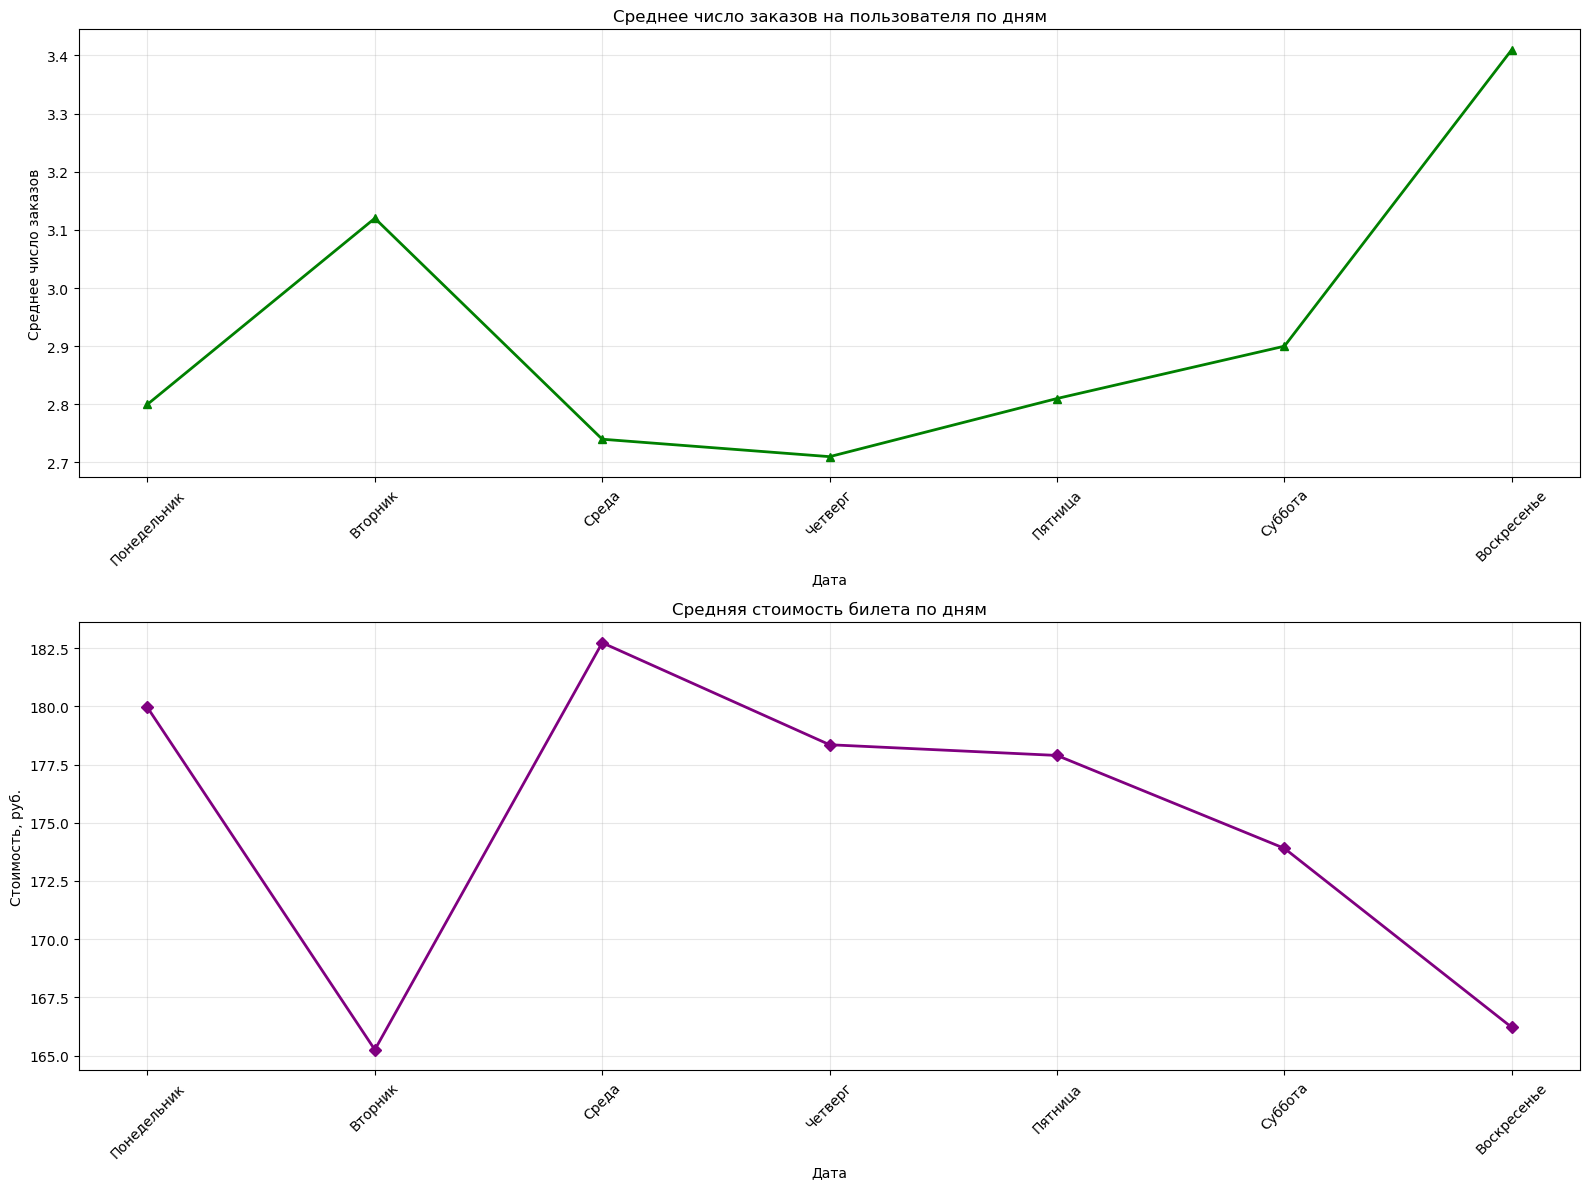

In [111]:
plt.figure(figsize=(16, 12))

# Среднее число заказов на пользователя
plt.subplot(2, 1, 1)
plt.plot(weekly_activity['weekday_name'], weekly_activity['avg_order_per_user'], marker='^', color='green', linewidth=2)
plt.title('Среднее число заказов на пользователя по дням')
plt.xlabel('Дата')
plt.ylabel('Среднее число заказов')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# Средняя стоимость билета
plt.subplot(2, 1, 2)
plt.plot(weekly_activity['weekday_name'], weekly_activity['avg_ticket'], marker='D', color='purple', linewidth=2)
plt.title('Средняя стоимость билета по дням')
plt.xlabel('Дата')
plt.ylabel('Стоимость, руб.')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Среднее число закзазов на пользовтаеля растет к середине недели и далее на спад идет к концу недели

большая часть актвиных пользотваелей больше всего делают покупки в середину недели 
Может быть связано с тем что когда планируют свои выходные  уже в середине недели могут так же брать небольшие мероприятия и в буднии дни сразу несоклько  в дни низких закзаов можно давать бонусы на несколько заказов.


Средняя стоимть билета ведет противоположно среднему числу закзаов, и подтвреждат предложение данное ранне 

Наибольшее число заказов в выходыне дни так же число актинвых пользователей в выходные дни на пике

### Анализ будних и выходных дней


In [112]:
comparison = daily_metrics.groupby('day_type').agg({
    'total_orders': 'mean',
    'active_users': 'mean',
    'avg_order_per_user': 'mean',
    'avg_ticket': 'mean'
}).round(2)

print("\nСравнение активности: будни и выходные")
print(comparison) 


Сравнение активности: будни и выходные
          total_orders  active_users  avg_order_per_user  avg_ticket
day_type                                                            
Будний          2481.2        867.63                2.82      176.90
Выходной        3101.5        977.90                3.15      170.06


In [113]:
comparison1 = pd.pivot_table(
    daily_metrics,
    values=['total_orders', 'active_users', 'avg_order_per_user', 'avg_ticket'],
    index='day_type',          # строки – типы дней
    aggfunc='mean'
).round(2)

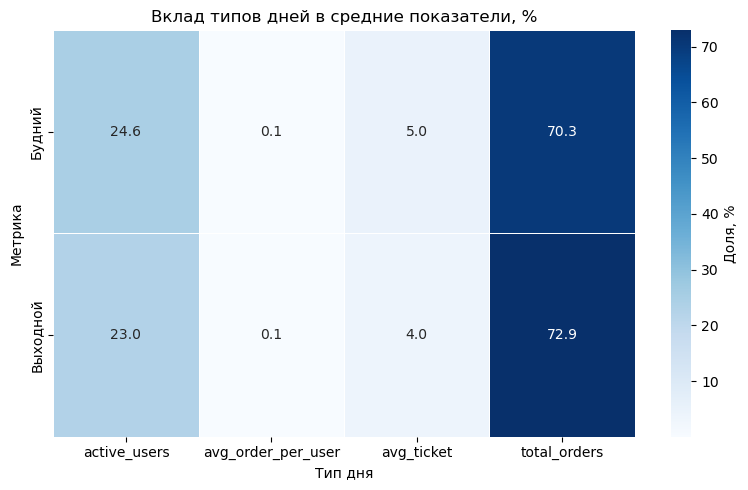

In [114]:
pivot_dolya = comparison1.div(comparison1.sum(axis=1), axis=0) * 100

plt.figure(figsize=(8, 5))
sns.heatmap(
    pivot_dolya,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    cbar_kws={'label': 'Доля, %'},
    linewidths=0.5,
    linecolor='white'
)
plt.title('Вклад типов дней в средние показатели, %')
plt.xlabel('Тип дня')
plt.ylabel('Метрика')
plt.tight_layout()
plt.show()

разница по типу дня недели незначитеьная

### вывод

Осенняя динамика и активность пользователей:

* Месячная динамика: Основные пики заказов приходятся на начало и конец месяца (1-е, 9-10-е, 30-31-е числа). Средняя стоимость билета находится в обратной корреляции с числом заказов: минимумы цены совпадают с пиками заказов, что указывает на проведение акций и скидок в эти периоды.

Динамика по дням недели:

* Пики заказов приходятся на среду, пятницу и воскресенье. Минимумы — на понедельник, вторник и субботу.
* Разница между буднями и выходными днями незначительная.
* Среднее число заказов на одного пользователя растет к середине недели и снижается к выходным.
* Поведение пользователей: Активные пользователи повторяют график заказов. Большая часть покупок совершается в середине недели (вероятно, в процессе планирования выходных).

## Анализ Популярных событийи партнёров

In [115]:
region_metrics = df_final.groupby('region_name').agg(
    unique_events=('event_id', 'nunique'),  # уникальное количество мероприятий
    total_orders=('order_id', 'count')       # общее число заказов
).reset_index()

region_metrics_sorted = region_metrics.sort_values('unique_events', ascending=False)

total_unique = region_metrics['unique_events'].sum()
total_orders_all = region_metrics['total_orders'].sum()

# 3. Расчёт долей в процентах
region_metrics['share_events'] = round((region_metrics['unique_events'] / total_unique) * 100, 2)
region_metrics['share_orders'] = round((region_metrics['total_orders'] / total_orders_all) * 100, 2)

# 4. Сортировка (по уникальным мероприятиям, можно и по доле)
region_metrics_sorted = region_metrics.sort_values('unique_events', ascending=False)

region_metrics

,region_name,unique_events,total_orders,share_events,share_orders
0,Белоярская область,57,197,0.26,0.07
1,Берестовский округ,39,383,0.18,0.14
2,Берёзовская область,134,1146,0.61,0.42
3,Боровлянский край,97,1662,0.44,0.61
4,Верховинская область,7,41,0.03,0.01
...,...,...,...,...,...
76,Шанырский регион,26,2242,0.12,0.82
77,Широковская область,1214,15320,5.55,5.60
78,Яблоневская область,531,5709,2.43,2.09
79,Ягодиновская область,117,1018,0.54,0.37


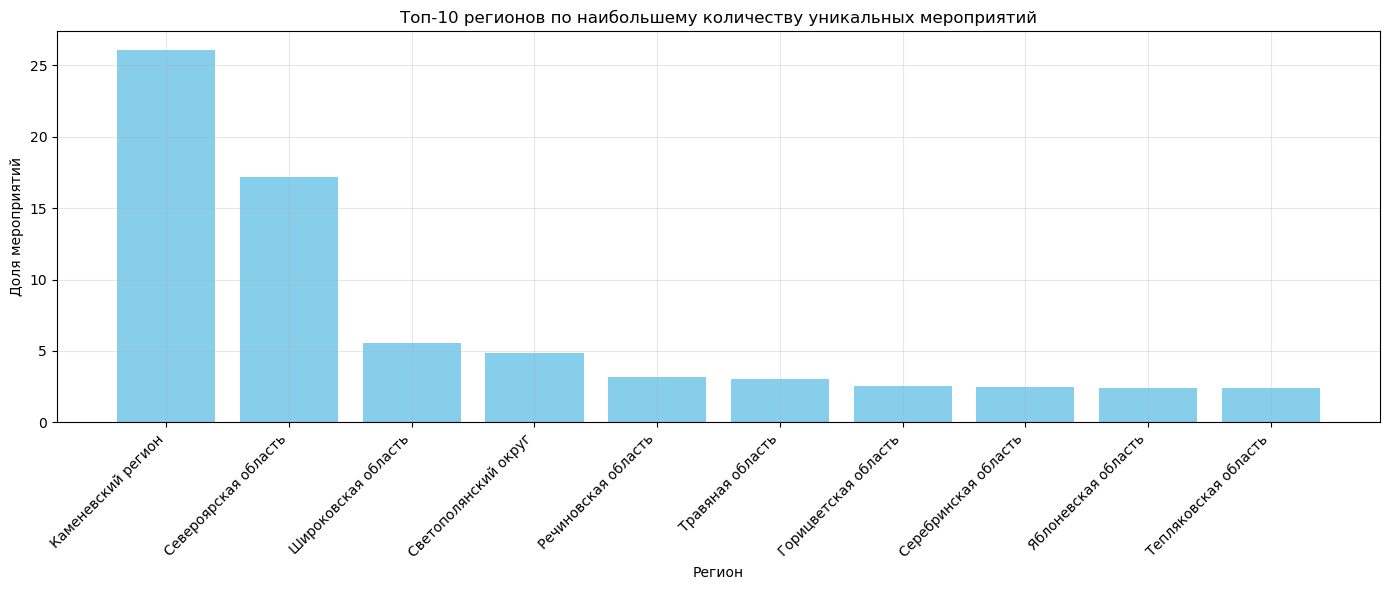

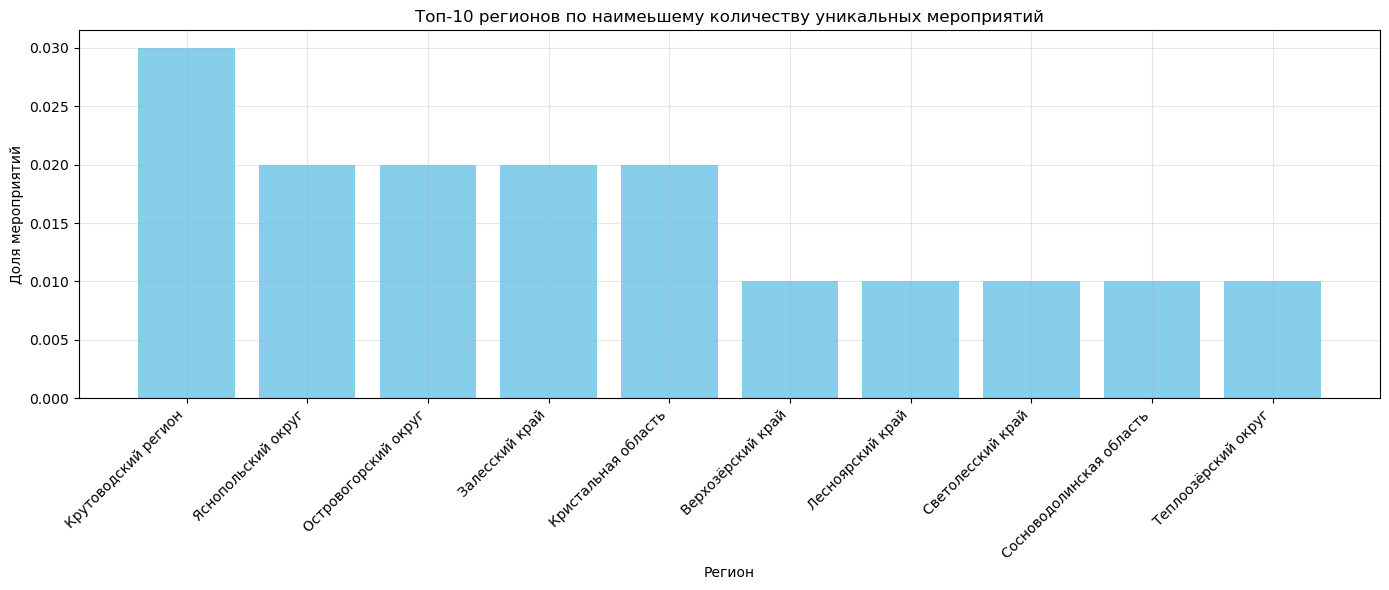

In [116]:
plt.figure(figsize=(14, 6))
# Топ‑10 регионов
top10 = region_metrics_sorted.head(10)
plt.bar(top10['region_name'], top10['share_events'], color='skyblue')
plt.title('Топ‑10 регионов по наибольшему количеству уникальных мероприятий')
plt.xlabel('Регион')
plt.ylabel('Доля мероприятий')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

top10 = region_metrics_sorted.tail(10)
plt.bar(top10['region_name'], top10['share_events'], color='skyblue')
plt.title('Топ‑10 регионов по наимеьшему количеству уникальных мероприятий')
plt.xlabel('Регион')
plt.ylabel('Доля мероприятий')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Больше всего мероприятий приходится на каменский регион  25%, североярская область 17%, шировкская область
меньше всего леснярский , светлолесский и верхозерские края по 0.01%

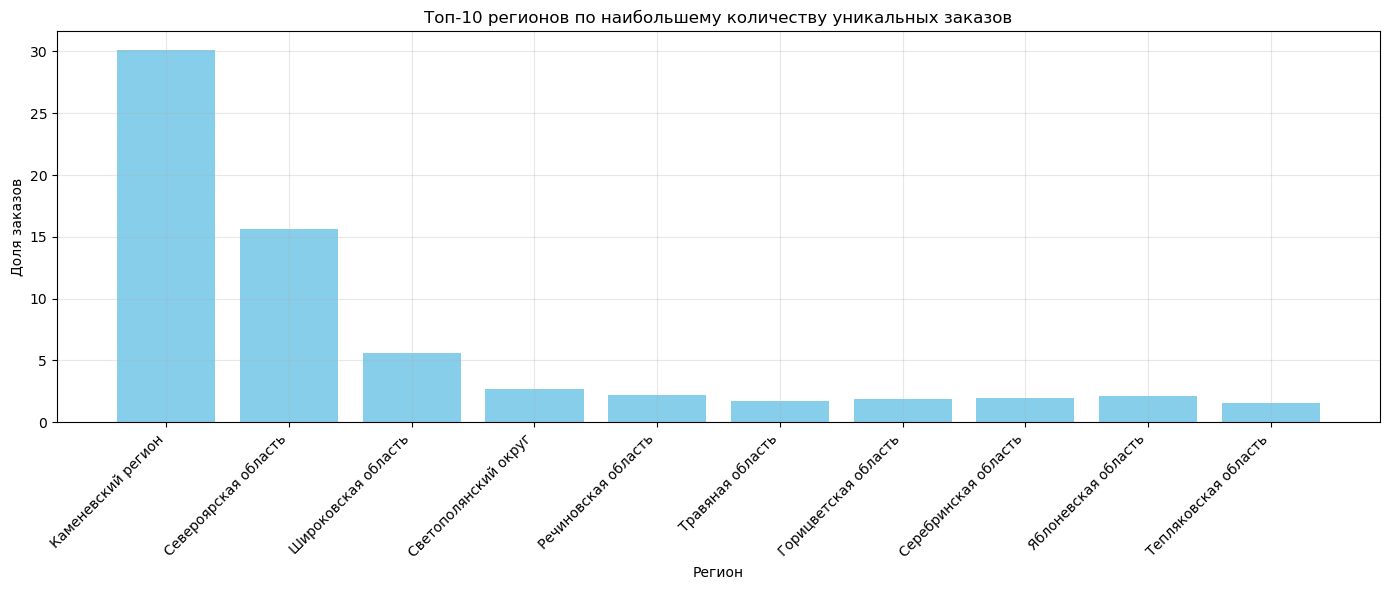

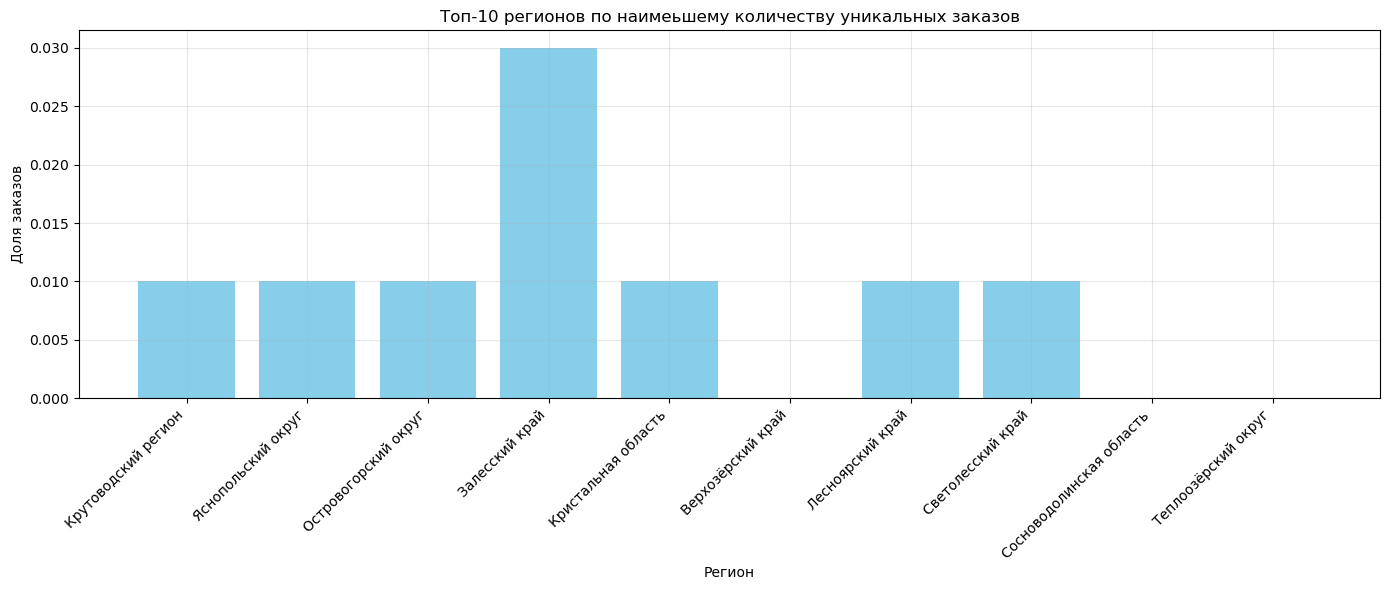

In [117]:
plt.figure(figsize=(14, 6))
# Топ‑10 регионов
top10 = region_metrics_sorted.head(10)
plt.bar(top10['region_name'], top10['share_orders'], color='skyblue')
plt.title('Топ‑10 регионов по наибольшему количеству уникальных заказов')
plt.xlabel('Регион')
plt.ylabel('Доля заказов')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

top10 = region_metrics_sorted.tail(10)
plt.bar(top10['region_name'], top10['share_orders'], color='skyblue')
plt.title('Топ‑10 регионов по наимеьшему количеству уникальных заказов')
plt.xlabel('Регион')
plt.ylabel('Доля заказов')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Топ 10 наибольших и наименьших в целом аналогичен с топпо числу мероприяйти по регионам
что говорит о сходжем спросе и предложение мероприятий 

Для определение потенциала регионаов с малым числом мероприятий и закаво следуте изучить демографию данных регоинов, при выявление потенциала по клиентам возможно следует привлечь туда партнеров


In [118]:
df_final['revenue_rub_k'] = round(df_final['revenue_rub']/1000, 2) # приведение выручки в тыс. руб.
venue_metrics = df_final.groupby('service_name').agg(
    unique_events=('event_id', 'nunique'),  # уникальное количество мероприятий
    total_orders=('order_id', 'count'),       # общее число заказов
    sum_revenue=('revenue_rub_k', 'sum')
).reset_index()

venue_metrics_sorted = venue_metrics.sort_values('unique_events', ascending=False)

venue_metrics_sorted.head()



,service_name,unique_events,total_orders,sum_revenue
21,Лови билет!,4795,39785,15180.63
3,Билеты без проблем,4010,56452,21391.25
5,Билеты в руки,3470,39477,12506.92
25,Облачко,2299,25666,17051.21
22,Лучшие билеты,1740,17532,2532.49


In [119]:
top_by_events = venue_metrics.sort_values('unique_events', ascending=False).head(10)
print("\nТоп‑10 партнёров по количеству уникальных мероприятий:")
print(top_by_events[['service_name', 'unique_events', 'total_orders', 'sum_revenue']])


Топ‑10 партнёров по количеству уникальных мероприятий:
          service_name  unique_events  total_orders  sum_revenue
21         Лови билет!           4795         39785     15180.63
3   Билеты без проблем           4010         56452     21391.25
5        Билеты в руки           3470         39477     12506.92
25             Облачко           2299         25666     17051.21
22       Лучшие билеты           1740         17532      2532.49
24           Мой билет           1287         32804     18164.94
30         Тебе билет!           1060          5028      2612.06
26           Прачечная           1018         10042      4368.29
8       Весь в билетах            837         14978     13527.16
35              Яблоко            705          4821      3483.72


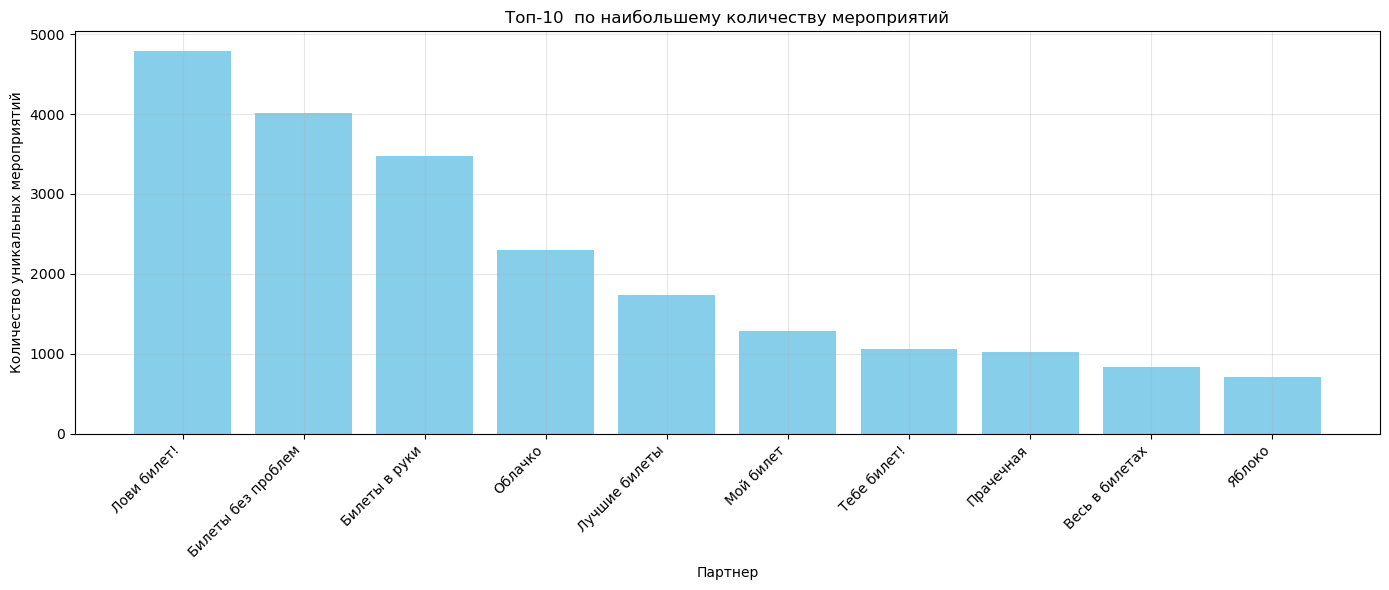

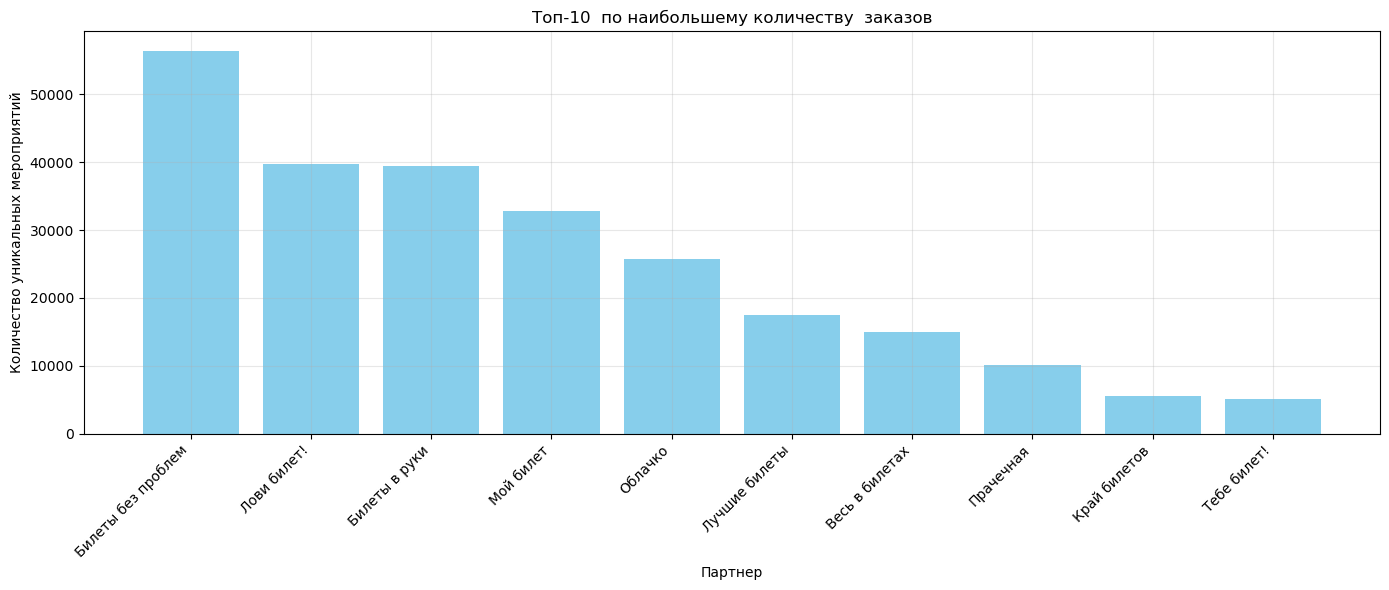

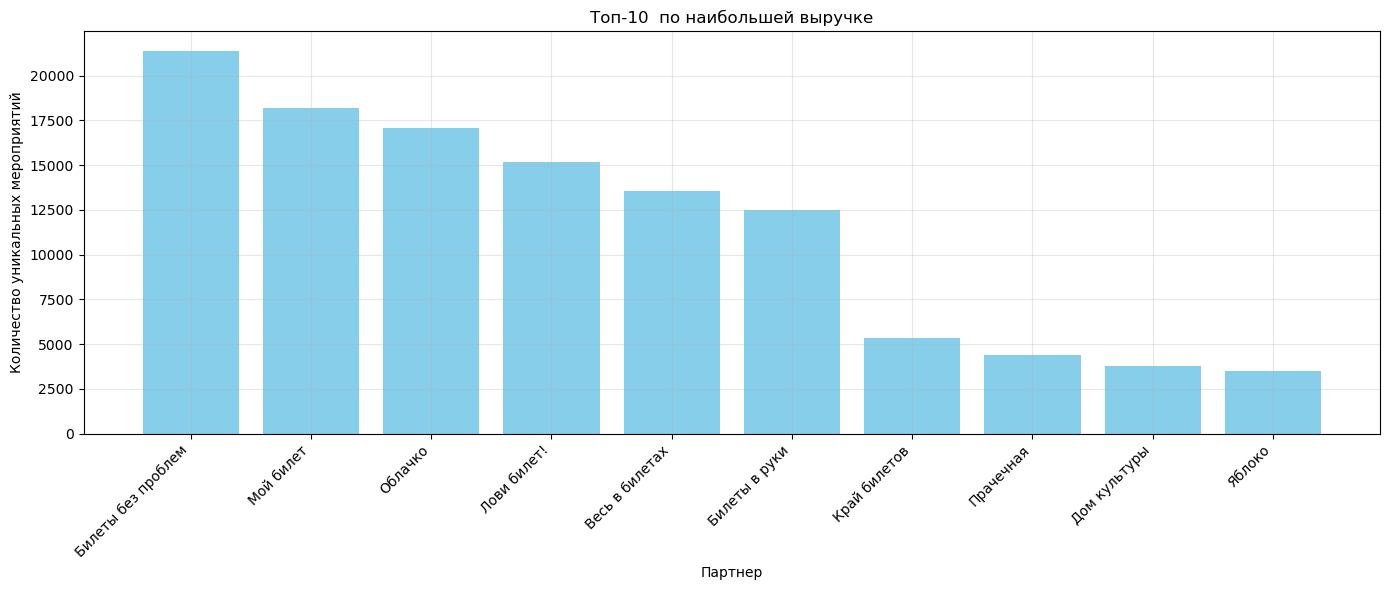

In [120]:
plt.figure(figsize=(14, 6))

top101 = venue_metrics_sorted.head(10)
plt.bar(top101['service_name'], top101['unique_events'], color='skyblue')
plt.title('Топ‑10  по наибольшему количеству мероприятий')
plt.xlabel('Партнер')
plt.ylabel('Количество уникальных мероприятий')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

top101 = venue_metrics_sorted.sort_values('total_orders', ascending=False).head(10)
plt.bar(top101['service_name'], top101['total_orders'], color='skyblue')
plt.title('Топ‑10  по наибольшему количеству  заказов')
plt.xlabel('Партнер')
plt.ylabel('Количество уникальных мероприятий')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

top101 = venue_metrics_sorted.sort_values('sum_revenue', ascending=False).head(10)
plt.bar(top101['service_name'], top101['sum_revenue'], color='skyblue')
plt.title('Топ‑10  по наибольшей выручке')
plt.xlabel('Партнер')
plt.ylabel('Количество уникальных мероприятий')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Топ 6 партнеров одинаковый  меняются местами, есть явные лидеры рынка 

In [121]:
venue_metrics_sorted.head()

,service_name,unique_events,total_orders,sum_revenue
21,Лови билет!,4795,39785,15180.63
3,Билеты без проблем,4010,56452,21391.25
5,Билеты в руки,3470,39477,12506.92
25,Облачко,2299,25666,17051.21
22,Лучшие билеты,1740,17532,2532.49


### Вывод

Регионы: Лидером является Каменский регион (25% мероприятий), далее следует Североярская область (17%). Наименьшая доля у Леснярского, Светлолесского и Верхозерского краев (по 0.01%). Топ-10 регионов по числу мероприятий полностью совпадает с Топ-10 по числу заказов, что говорит о балансе спроса и предложения.

Партнеры: Рынок консолидирован: Топ-6 партнеров стабильно удерживают лидерство, периодически меняясь местами. Явных аутсайдеров среди лидеров нет.

## Статистический анализ данных

Необходимо проверить следующие гипотезы

Гипотеза 1:
Среднее количество заказов на одного пользователя мобильного приложения выше по сравнению с пользователями стационарных устройств.

* Н0:Среднее количество заказов на одного пользователя мобильного устройства и  пользователя стационарных устройств одинаково.

* Н1: Среднее количество заказов на одного пользователя мобильного устройства выше по сравнению с пользователями стационарных устройств.
* Н2: Среднее количество заказов на одного пользователя обоих устройств выше по сравнению с пользователями стационарных устройств.
* H3 Среднее количество заказов на одного пользователя обоих устройств выше по сравнению с пользователями мобильных устройств.


Гипотеза 2:
Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.

* Н0:Среднее время между заказами пользователей мобильных приложений и пользоватей стационарных устройств одинаково.

* Н1:Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.

Перед проведением теста необходимо подготовить данные разделить пользователй по категории устройств

In [122]:
user_devices = df_final.groupby('user_id')['device_type_canonical'].unique().reset_index()
user_devices.columns = ['user_id', 'devices_used']

# Функция для классификации пользователей
def classify_user(devices):
    has_mobile = 'mobile' in devices
    has_desktop = 'desktop' in devices

    if has_mobile and has_desktop:
        return 'оба устройства'
    elif has_mobile:
        return 'только мобильные'
    elif has_desktop:
        return 'только десктоп'
    else:
        return 'неопределено'
user_devices['user_group'] = user_devices['devices_used'].apply(classify_user)

df_final = df_final.merge(user_devices[['user_id', 'user_group']], on='user_id', how='left')

group_counts = user_devices['user_group'].value_counts()
print("Распределение пользователей по группам:")
print(group_counts)

group_percentages = (group_counts / len(user_devices)) * 100
print("\nРаспределение в процентах:")
print(group_percentages.round(2))



Распределение пользователей по группам:
user_group
только мобильные    14513
оба устройства       4808
только десктоп       2094
Name: count, dtype: int64

Распределение в процентах:
user_group
только мобильные    67.77
оба устройства      22.45
только десктоп       9.78
Name: count, dtype: float64


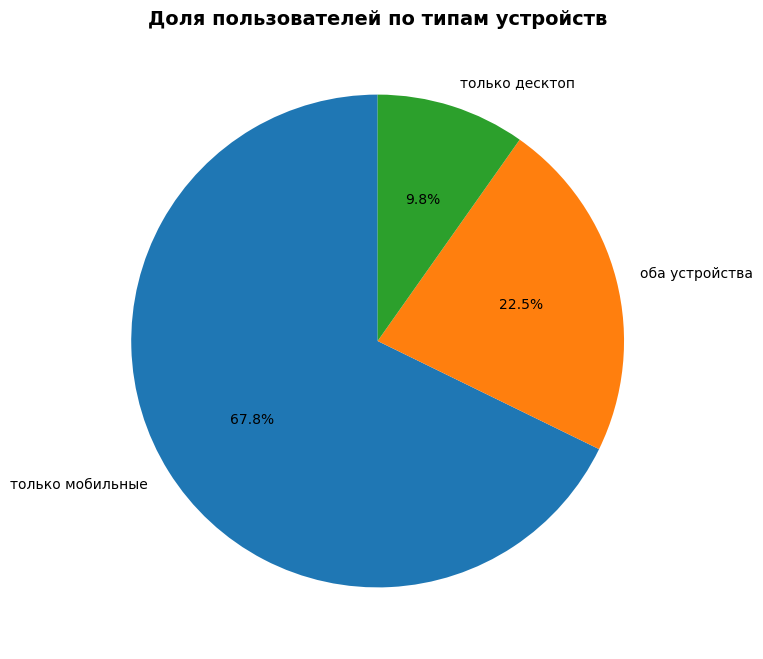

In [123]:
plt.figure(figsize=(8, 8))
plt.pie(
    group_counts,
    labels=group_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Доля пользователей по типам устройств', fontsize=14, fontweight='bold')
plt.show()

In [124]:
mob = df_final[df_final['user_group']=='только мобильные']
desk = df_final[df_final['user_group']=='только десктоп']
moab_desk = df_final[df_final['user_group']=='оба устройства']

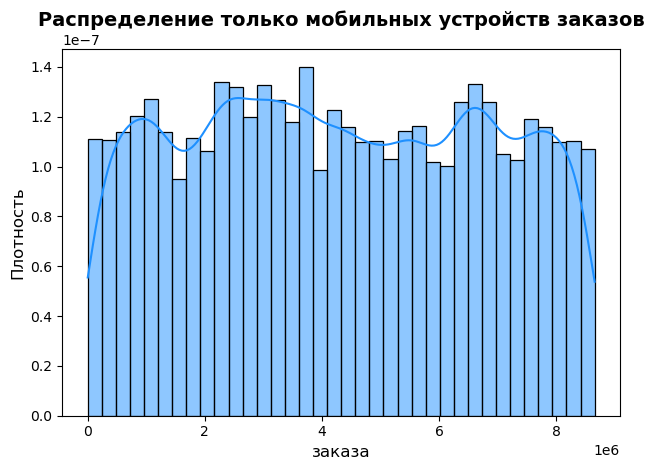

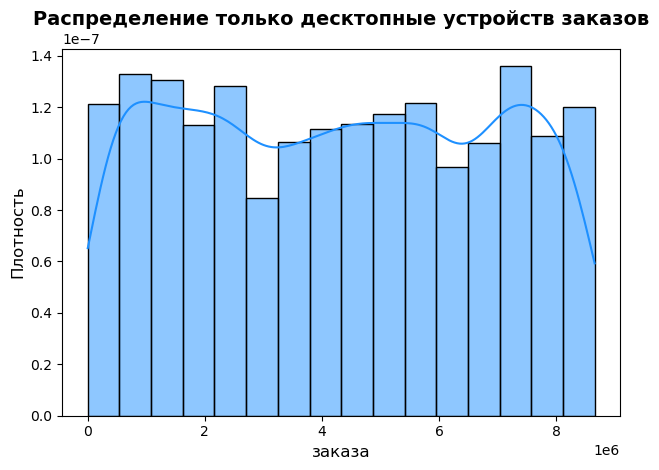

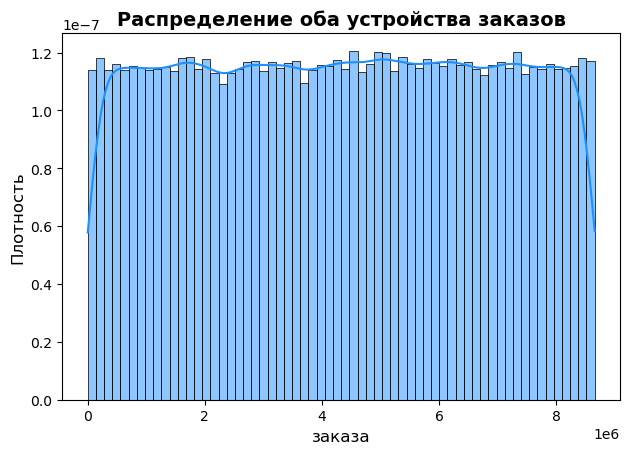

In [125]:
sns.histplot(data=mob['order_id'],
             bins='auto',
             kde=True,
             stat='density',
             color='dodgerblue',
             edgecolor='black'
            )

plt.title('Распределение только мобильных устройств заказов', fontsize=14, fontweight='bold')
plt.xlabel('заказа', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.tight_layout()
plt.show()


sns.histplot(data=desk['order_id'],
             bins='auto',
             kde=True,
             stat='density',
             color='dodgerblue',
             edgecolor='black'
            )

plt.title('Распределение только десктопные устройств заказов', fontsize=14, fontweight='bold')
plt.xlabel('заказа', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.tight_layout()
plt.show()

sns.histplot(data=moab_desk['order_id'],
             bins='auto',
             kde=True,
             stat='density',
             color='dodgerblue',
             edgecolor='black'
            )

plt.title('Распределение оба устройства заказов', fontsize=14, fontweight='bold')
plt.xlabel('заказа', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.tight_layout()
plt.show()

Данные распределены не нормально

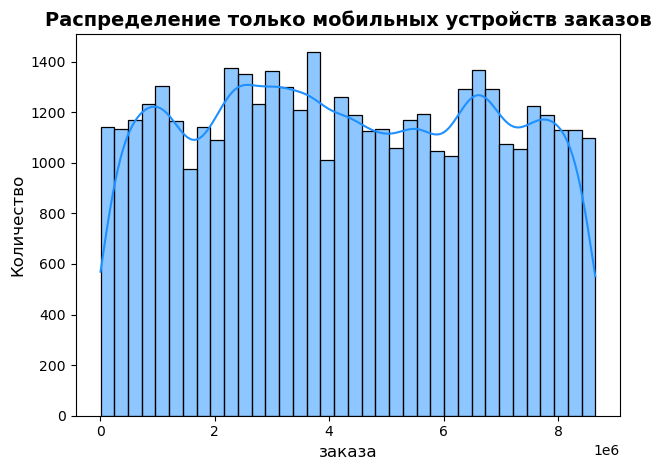

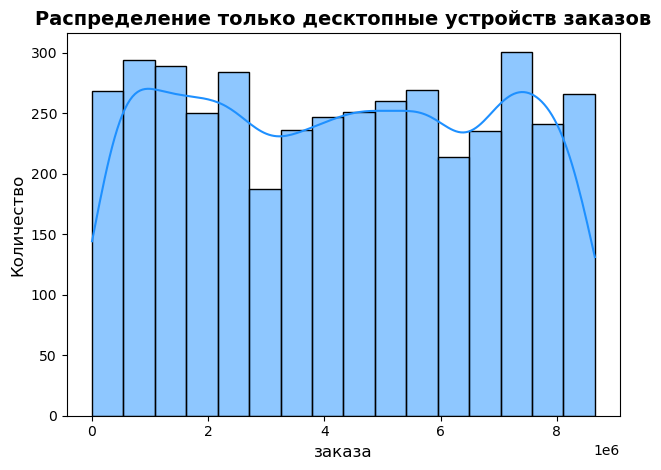

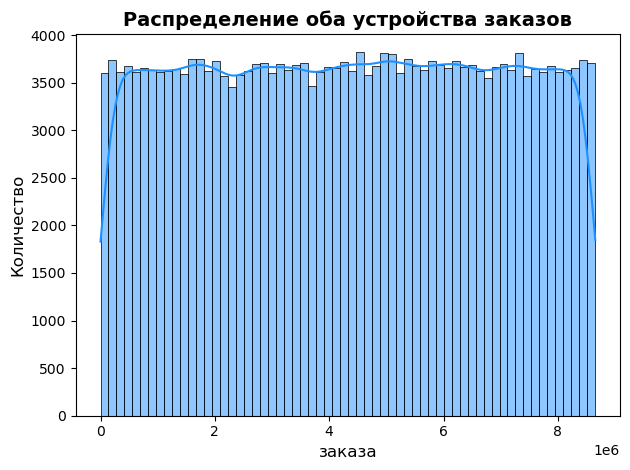

In [126]:
sns.histplot(data=mob['order_id'],
             bins='auto',
             kde=True,
             color='dodgerblue',
             edgecolor='black'
            )

plt.title('Распределение только мобильных устройств заказов', fontsize=14, fontweight='bold')
plt.xlabel('заказа', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.tight_layout()
plt.show()


sns.histplot(data=desk['order_id'],
             bins='auto',
             kde=True,

             color='dodgerblue',
             edgecolor='black'
            )

plt.title('Распределение только десктопные устройств заказов', fontsize=14, fontweight='bold')
plt.xlabel('заказа', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.tight_layout()
plt.show()

sns.histplot(data=moab_desk['order_id'],
             bins='auto',
             kde=True,

             color='dodgerblue',
             edgecolor='black'
            )

plt.title('Распределение оба устройства заказов', fontsize=14, fontweight='bold')
plt.xlabel('заказа', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.tight_layout()
plt.show()

In [127]:
df_final.head(2)

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,venue_name,venue_address,curs,sum_rub,revenue_rub,one_ticket_revenue_rub,month,season,revenue_rub_k,user_group
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",18.6972,0,1521.94,380.485,8,лето,1.52,только мобильные
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,"Музыкальная школа для детей ""Аккаунт"" Лтд","алл. Шмидта, д. 9 стр. 4",18.3419,0,289.45,144.725,7,лето,0.29,только мобильные


In [128]:
df_sorted = df_final.sort_values(['user_id', 'created_ts_msk'])

df_sorted['prev_datetime'] = df_sorted.groupby('user_id')['created_ts_msk'].shift(1)

df_sorted['interval_seconds'] = (df_sorted['created_ts_msk'] - df_sorted['prev_datetime']).dt.total_seconds()

df_sorted['interval_days']    = df_sorted['interval_seconds'] / 86400

In [129]:
df_sorted.head()

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,sum_rub,revenue_rub,one_ticket_revenue_rub,month,season,revenue_rub_k,user_group,prev_datetime,interval_seconds,interval_days
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,0,1521.94,380.4850,8,лето,1.52,только мобильные,NaT,NaN,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,0,289.45,144.7250,7,лето,0.29,только мобильные,NaT,NaN,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,0,1258.57,314.6425,10,осень,1.26,только мобильные,2024-07-23 18:36:24,6463178.0,74.805301
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,0,8.49,4.2450,7,лето,0.01,только мобильные,NaT,NaN,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,0,1390.41,463.4700,10,осень,1.39,только мобильные,2024-07-13 19:40:48,7181547.0,83.119757


In [130]:
df_intervals = df_sorted.dropna(subset=['interval_days'])
df_intervals.head()

,order_id,user_id,data,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,sum_rub,revenue_rub,one_ticket_revenue_rub,month,season,revenue_rub_k,user_group,prev_datetime,interval_seconds,interval_days
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,0,1258.57,314.642500,10,осень,1.26,только мобильные,2024-07-23 18:36:24,6463178.0,74.805301
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,0,1390.41,463.470000,10,осень,1.39,только мобильные,2024-07-13 19:40:48,7181547.0,83.119757
5,2613713,000898990054619,2024-10-23,2024-10-23 15:12:00,500862,нет,12,rub,mobile,902.74,...,0,902.74,300.913333,10,осень,0.90,только мобильные,2024-10-04 22:33:15,1615125.0,18.693576
8,4657952,000a55a418c128c,2024-10-15,2024-10-15 10:29:04,271579,нет,12,rub,mobile,74.84,...,0,74.84,37.420000,10,осень,0.07,только мобильные,2024-09-29 19:39:12,1349392.0,15.617963
11,6818249,000cf0659a9f40f,2024-06-20,2024-06-20 10:49:48,516728,нет,12,rub,mobile,710.95,...,0,710.95,355.475000,6,лето,0.71,только мобильные,2024-06-20 10:35:26,862.0,0.009977


In [131]:
user_avg_interval = df_intervals.groupby('user_id').agg(
    avg_interval_days = ('interval_days', 'mean')
).reset_index()

# Добавляем группу устройств
user_avg_interval = user_avg_interval.merge(
    df_final[['user_id', 'user_group']].drop_duplicates(),
    on='user_id',
    how='left'
)

user_avg_interval

,user_id,avg_interval_days,user_group
0,0005ca5e93f2cf4,74.805301,только мобильные
1,000898990054619,50.906667,только мобильные
2,000a55a418c128c,15.617963,только мобильные
3,000cf0659a9f40f,0.062549,только мобильные
4,00147c9209d45d3,0.001319,только мобильные
...,...,...,...
13136,ffecf05f1f6a9c6,19.870417,только мобильные
13137,ffed3ff067d4f12,26.011316,только мобильные
13138,fff13b79bd47d7c,13.355443,только мобильные
13139,fff32fc9ad0f9f6,74.377894,только десктоп


In [132]:
moba = user_avg_interval[user_avg_interval['user_group']== 'только мобильные']
deska = user_avg_interval[user_avg_interval['user_group']== 'только десктоп']
both = user_avg_interval[user_avg_interval['user_group']== 'оба устройства']

In [133]:
moba.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7564 entries, 0 to 13138
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            7564 non-null   object 
 1   avg_interval_days  7564 non-null   float64
 2   user_group         7564 non-null   object 
dtypes: float64(1), object(2)
memory usage: 236.4+ KB


C:\Users\User\AppData\Local\Temp\ipykernel_19680\3838009109.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=user_avg_interval, x='user_group', y='avg_interval_days', palette='Set2')


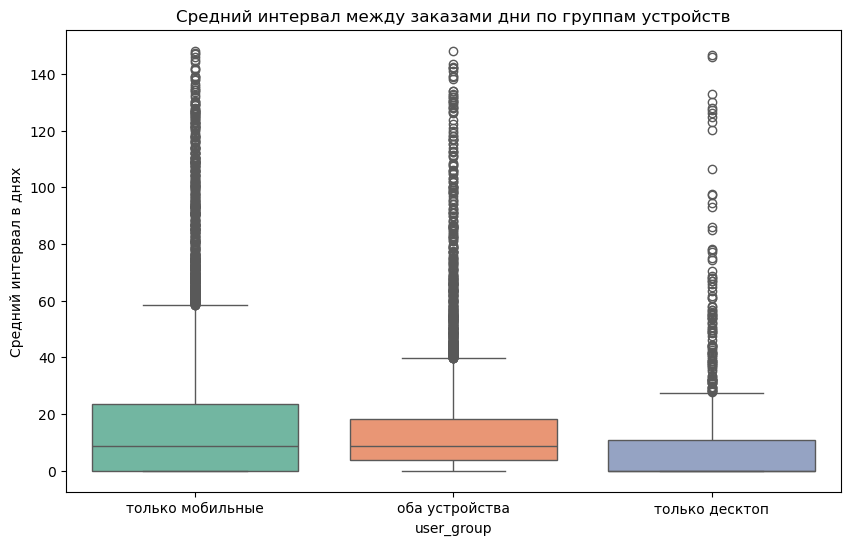

In [134]:
plt.figure(figsize=(10,6))
sns.boxplot(data=user_avg_interval, x='user_group', y='avg_interval_days', palette='Set2')
plt.title('Средний интервал между заказами дни по группам устройств')
plt.ylabel('Средний интервал в днях')
plt.show()


Между группами есть различия при этом в каждой есть выбросы, что сильно влияет на среднее значение, для его нивилирования выбросов лушче использовать медиану. 
На именьший разброс в группе десктопных, наимбольший в группе мобильных устройств

Коментарий студента

здесь останавливается код и требуется заново загрузить библиотеки

AttributeError: 'DataFrame' object has no attribute 'probplot'

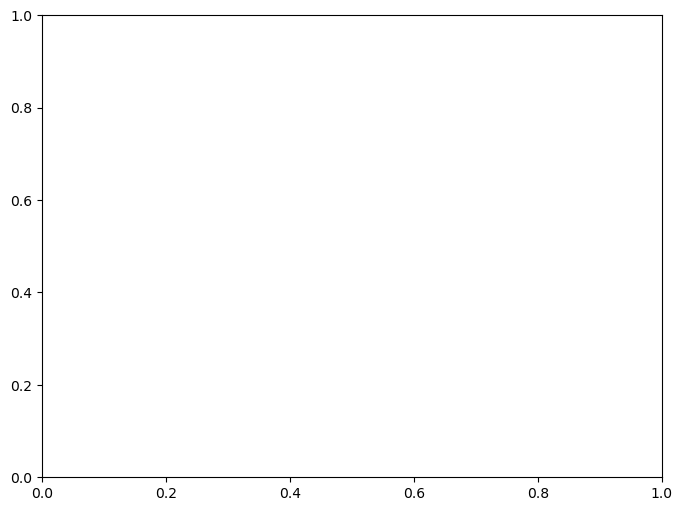

In [135]:
data = user_avg_interval[user_avg_interval['user_group'] == 'только мобильные']['avg_interval_days']

# Строим Q-Q график против нормального распределения
fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(data, dist="norm", plot=ax)
ax.set_title('Q-Q график (нормальное распределение)')
ax.set_xlabel('Теоретические квантили')
ax.set_ylabel('Эмпирические квантили')
plt.grid(True)
plt.show()

data = user_avg_interval[user_avg_interval['user_group'] == 'оба устройства']['avg_interval_days']

# Строим Q-Q график против нормального распределения
fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(data, dist="norm", plot=ax)
ax.set_title('Q-Q график (нормальное распределение)')
ax.set_xlabel('Теоретические квантили')
ax.set_ylabel('Эмпирические квантили')
plt.grid(True)
plt.show()

data = user_avg_interval[user_avg_interval['user_group'] == 'только десктоп']['avg_interval_days']

# Строим Q-Q график против нормального распределения
fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(data, dist="norm", plot=ax)
ax.set_title('Q-Q график (нормальное распределение)')
ax.set_xlabel('Теоретические квантили')
ax.set_ylabel('Эмпирические квантили')
plt.grid(True)
plt.show()

Данные не ясвлябтся нормлаьными, нужно использовать не параметрический тест

In [ ]:
df_intervals1 = df_intervals[['order_id', 'user_id', 'user_group']]
df_intervals1.head()

In [ ]:
moba = df_intervals1[df_intervals1['user_group']=='только мобильные']
deska = df_intervals1[df_intervals1['user_group']=='только десктоп']
both = df_intervals1[df_intervals1['user_group']=='оба устройства']

moba_count = moba.groupby('user_id')['order_id'].count()
deska_count = deska.groupby('user_id')['order_id'].count()
both_count = both.groupby('user_id')['order_id'].count()

In [ ]:
mobile_user = df_intervals1[df_intervals1['user_group'] == 'только мобильные']['order_id'].astype(float)
desktop_user = df_intervals1[df_intervals1['user_group'] == 'только десктоп']['order_id'].astype(float)
both_user = df_intervals1[df_intervals1['user_group'] == 'оба устройства']['order_id'].astype(float)

### Тест первой гипотезы

In [ ]:
print("Размер выборки (desktop):", len(desktop_user))
print("Размер выборки (both):", len(both_user))
print("Размер выборки (mobile_user):", len(mobile_user))



print("\nОписательная статистика (desktop):")
print(desktop_user.describe())
print("\nОписательная статистика (both):")
print(both_user.describe())

print("\nОписательная статистика (mobile_user):")
print(mobile_user.describe()) 

In [ ]:
stat, p_value1 = stats.mannwhitneyu(
    mobile_user,
    desktop_user,
    alternative='two-sided'
)

print(f"P-value: {p_value1}")
if p_value1 < 0.05:
    print("Нулевая гипотеза не подтверждена: Пользователи мобильных устройств делают статистически значимо больше заказов, чем компьютеров.")
else:
    print("Нулевая гипотеза не отвергатеся: Различий нет.")


In [ ]:
stat, p_value2 = stats.mannwhitneyu(
    both_user,
    desktop_user,
    alternative='two-sided'
)


print(f"P-value: {p_value2}")
if p_value1 < 0.05:
    print("Нулевая гипотеза не подтверждена: Пользователи обоих устройств делают статистически значимо больше заказов, чем мобильных.")
else:
    print("Нулевая гипотеза не отвергатеся: Различий нет")


In [ ]:
stat, p_value3 = stats.mannwhitneyu(
    both_user,
    mobile_user,
    alternative='two-sided'
)

print(f"P-value: {p_value3}")
if p_value1 < 0.05:
    print("Нулевая гипотеза не подтверждена: Пользователи обоих устройств делают статистически значимо больше заказов, чем мобильных.")
else:
    print("Нулевая гипотеза не отвергатеся: Различий нет.")


Значимой разницы между устройствами в среднем нет, невжано только мобильныеили десктопные или обоими устройствами.
ПРичинами могут быть следующие сервис работает одинаково хорошо на любом устройствее.

Соврешать одинково легко независимо от типа устройства.

Из этого следуте можно одинаково развивать  обо канала

### Теста второй гипотезы

In [ ]:
df_final.info()

In [ ]:
df_final.head()

In [ ]:
df_final['device_type_canonical'].value_counts()

In [ ]:
user_device_counts = df_final.groupby('user_id').agg(
    total_orders=('order_id', 'nunique'),
    mobile_orders=('device_type_canonical', lambda x: (x == 'mobile').sum())
).reset_index()

# Вычисляем долю мобильных заказов
user_device_counts['mobile_share'] = user_device_counts['mobile_orders'] / user_device_counts['total_orders']

In [ ]:
def classify_user(row):
    share = row['mobile_share']
    if share >= 0.8:
        return 'преимущественно мобильные'
    elif share <= 0.2:   # т.е. десктопных >= 80%
        return 'преимущественно десктопные'
    else:
        return 'смешанный паттерн'

user_device_counts['user_group'] = user_device_counts.apply(classify_user, axis=1)

In [ ]:
# Сортируем заказы по пользователю и времени
df_sorted = df_final.sort_values(['user_id', 'created_ts_msk'])

# Вычисляем разницу с предыдущим заказом в часах
df_sorted['prev_datetime'] = df_sorted.groupby('user_id')['created_ts_msk'].shift(1)
df_sorted['interval_hours'] = (df_sorted['created_ts_msk'] - df_sorted['prev_datetime']).dt.total_seconds() / 3600

# Удаляем NaN (первые заказы)
df_intervals = df_sorted.dropna(subset=['interval_hours'])

# Для каждого пользователя считаем средний интервал (можно также медиану)
user_avg_interval = df_intervals.groupby('user_id').agg(
    avg_interval_hours=('interval_hours', 'mean')
).reset_index()

# Добавляем группу пользователя
user_avg_interval = user_avg_interval.merge(
    user_device_counts[['user_id', 'user_group']],
    on='user_id',
    how='inner'
)

In [ ]:
# Извлекаем данные для двух групп
mobile = user_avg_interval[user_avg_interval['user_group'] == 'преимущественно мобильные']['avg_interval_hours']
desktop = user_avg_interval[user_avg_interval['user_group'] == 'преимущественно десктопные']['avg_interval_hours']
oboth = user_avg_interval[user_avg_interval['user_group'] == 'смешанный паттерн']['avg_interval_hours']
# Односторонний тест: мобильные > десктопные
u_stat, p_value = mannwhitneyu(mobile, desktop, alternative='greater')
print(f'U-статистика = {u_stat:.2f}')
print(f'p-value = {p_value}')

u_stat2, p_value2 = mannwhitneyu(oboth, mobile, alternative='greater')
print(f'U-статистика = {u_stat2:.2f}')
print(f'p-value = {p_value2}')

u_stat3, p_value3 = mannwhitneyu(oboth, desktop, alternative='greater')
print(f'U-статистика = {u_stat3:.2f}')
print(f'p-value = {p_value3}')


In [ ]:
print("Медианы:")
print(f"Мобильные: {mobile.median():.2f}")
print(f"Десктоп: {desktop.median():.2f}")
print(f"Оба устройства: {oboth.median():.2f}")


print("\nСредние:")
print(f"Мобильные: {mobile.mean():.2f}")
print(f"Десктоп: {desktop.mean():.2f}")
print(f"Оба устройства: {oboth.mean():.2f}")

Десктопные пользователи — наименее активные. Медиана  низка 4,27, что может указывать на:
разовое использование

Использование десктопа скорее для ознакомления, а не для совершение заказов;
.
Пользователи обоих устройств — самые активные. наибольшии медиана и среднее. Вероятно, самые лояльные клиенты, использующие разные устройства для удобства

Рекомендаации:
1. Акцент на мобильных пользователях
2. Провести изучение десктопной версии, для выявления проблем, при совершении заказа
3. давать бонусы за использование обоих устройств

## Вывод

1. Подготовка и обработка данных:

Анализ проводился на данных сервиса за период с июня по октябрь 2024 года. В ходе предобработки были выполнены следующие шаги:
Создание новых признаков: сформированы столбцы evenue_rub (выручка с заказа в руб.), one_ticket_revenue_rub (выручка с одного билета), month (месяц заказа) и season (сезон).
Очистка от аномалий: выбросы были ограничены 2-м и 99-м процентилями. Удалено незначительное для общего анализа количество аномальных записей (8 970 в рублях и 283 в тенге).
Пропуски и оптимизация: пропуски выявлены только в одном столбце, где они логически допустимы. Типы данных столбцов оптимизированы для снижения потребления памяти.

2. Выводы по анализу:

Общий анализ выручки и сезонности:

Распределение выручки имеет ярко выраженную правостороннюю асимметрию, что говорит о преобладании мероприятий в низкой ценовой категории.
Осенью наблюдается рост общего числа заказов по сравнению с летом, однако средний чек снижается. Это связано с увеличением доли покупок в низком ценовом сегменте.
Темпы роста заказов по типам устройств (мобильные и десктопные) ведут себя синхронно, значимой разницы в динамике между ними нет.

Анализ категорий мероприятий:
- Лидеры по объему: Концерты и театр остаются самыми массовыми и популярными категориями.

* Лидеры по росту: Осенью по сравнению с летом наибольший прирост показали Спорт (+527%) и Новогодние ёлки (+533%). Концерты выросли на 30%, театр — на 79%. Остальные категории показали незначительный рост.

* Динамика цен: Несмотря на рост спроса, средняя цена билета в большинстве категорий упала (концерты -26%, спорт -9%). Исключение составили выставки (+4%) и стендап (+11%).

Гипотеза: Резкий рост предложения в категориях «спорт» и «ёлки» привел к неполной заполняемости площадок, что вынудило организаторов снижать цены.

* Аутсайдеры: Стендап и выставки крайне непопулярны. Категория «ёлки» имеет ярко выраженную сезонность (подготовка к Новому году) и является редким явлением в течение года.
Возрастные ограничения

Наиболее востребованной возрастной категория 16+ и +0. Остальные возрастные категории отличаются незначительно, наименьшеая +18.

Наблюдается сезонность: в июле рост у всех категорий, в августе стагнация (вероятно, из-за летних отпусков), в сентябре незначительный спад у +6, а в октябре — значительный рост у всех, кроме +18.

Осенняя динамика и активность пользователей:

* Месячная динамика: Основные пики заказов приходятся на начало и конец месяца (1-е, 9-10-е, 30-31-е числа). Средняя стоимость билета находится в обратной корреляции с числом заказов: минимумы цены совпадают с пиками заказов, что указывает на проведение акций и скидок в эти периоды.

Динамика по дням недели:

* Пики заказов приходятся на среду, пятницу и воскресенье. Минимумы — на понедельник, вторник и субботу.
* Разница между буднями и выходными днями незначительная.
* Среднее число заказов на одного пользователя растет к середине недели и снижается к выходным.
* Поведение пользователей: Активные пользователи повторяют график заказов. Большая часть покупок совершается в середине недели (вероятно, в процессе планирования выходных).


География и партнеры

Регионы: Лидером является Каменский регион (25% мероприятий), далее следует Североярская область (17%). Наименьшая доля у Леснярского, Светлолесского и Верхозерского краев (по 0.01%). Топ-10 регионов по числу мероприятий полностью совпадает с Топ-10 по числу заказов, что говорит о балансе спроса и предложения.

Партнеры: Рынок консолидирован: Топ-6 партнеров стабильно удерживают лидерство, периодически меняясь местами. Явных аутсайдеров среди лидеров нет.

Статистический тест

Статистически значимой разницы в средних показателях между мобильными и десктопными пользователями не выявлено. Сервис работает одинаково хорошо на обоих платформах.
Однако медиана заказов у десктопных пользователей низкая (4,27), что указывает на разовое использование или использование ПК только для ознакомления с афишей.
Самые лояльные и активные клиенты — пользователи, которые чередуют оба типа устройств (наибольшие медиана и среднее).

3. Практические рекомендации:

Для рекламы

Стимулирование спроса в «тихие» дни: В дни низкой активности (понедельник, вторник, суббота) запускать таргетированную рекламу и предлагать персональные скидки для привлечения пользователей.
Бандлы и акции в середине недели: Так как пользователи активнее планируют досуг в среду-четверг, предлагать бонусы или скидки «2 по цене 1» при покупке нескольких билетов в будние дни.
Работа с непопулярными категориями: Для повышения прибыли в категориях «стендап» и «выставки» рассмотреть возможность организации более дорогих, эксклюзивных мероприятий с ограниченным числом мест.
Монетизация «Ёлок»: Учитывая высокий сезонный спрос и ограниченное предложение, изучить эластичность спроса и, возможно, увеличить средний чек на новогодние мероприятия.

Для развития продукта:

Сделать акцент на улучшении мобильного приложения, является основным каналом совершения заказов.
Проверка десктопной версии: Провести UX-исследование десктопной версии сайта. Низкая медиана заказов (4,27) может указывать на скрытые проблемы в пути пользователя (CJM) при оформлении заказа с ПК

мултиплатформная лояльность: Выдавать бонусы для пользователей, которые используют и мобильное приложение, и веб-версию (например, дополнительные бонусы за вход с разных устройств), так как это самые лояльные клиенты.

Для бизнес-развития и партнерства
Провести демографический анализ регионов с минимальным числом мероприятий (Леснярский, Светлолесский, Верхозерский края). При выявлении платежеспособного спроса привлечь туда новых партнеров-организаторов.

Поддержка лидеров: Усилить маркетинговую поддержку категорий «Спорт» и «Театр», которые показали взрывной рост осенью, чтобы закрепить тренд.

In [140]:
!jupyter nbconvert --to html --no-input 03_revenue_report.ipynb --output-dir reports/

This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute
    Execute the notebook prior to export.
    Equivalent to: [--ExecutePr

[NbConvertApp] WARNING | pattern '03_revenue_report.ipynb' matched no files
